# Сравнение IFN-ответа культур глиобластомы

Выполнила: Шилина Виктория, Б06-304а.

В работе выполнено сравнение изменения протеома пяти культур с сохранённым ответом на интерфероны:
GBM3821, GBM4446, GBM5410, GBM6067 и GBM6138. Для каждой культуры рассмотрела IFN-α и IFN-β
относительно контроля. В каждом условии было по четыре измерения, всего 60 файлов.

Данные относятся к исследованию [Lipatova et al., Cancers (2021), 13(21), 5268](https://doi.org/10.3390/cancers13215268)
и доступны в [PRIDE PXD022836](https://ftp.pride.ebi.ac.uk/pride/data/archive/2022/02/PXD022836/).
Все выбранные измерения выполнены на Orbitrap Fusion Lumos.

Исходные белки расщепляли на пептиды и анализировали методом bottom-up LC–MS/MS.
Полный пайплайн включает конвертацию RAW в mzML, поиск MSFragger, валидацию Scavager,
количественное сравнение QRePS и функциональный анализ STRING.
Здесь используются готовые отфильтрованные таблицы PSM и белков из PRIDE.
Конвертацию спектров, поиск и первичную валидацию повторно не запускали.


In [1]:
# Установка библиотек
import subprocess
import sys

packages = [
    'QRePS==1.2.1', 'numpy>=1.26,<3', 'pandas>=2.2,<3',
    'scipy>=1.12,<2', 'statsmodels>=0.14,<1', 'scikit-learn>=1.4,<2',
    'matplotlib>=3.8,<4', 'seaborn>=0.13,<0.14', 'requests>=2.31,<3',
]
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *packages])
print('Библиотеки установлены. Далее загрузите FASTA в предложенном окне.')

Библиотеки установлены. Далее загрузите FASTA в предложенном окне.


## 1. Параметры анализа

Для QRePS оставлены параметры семинара: импутация `kNN`, пороги `semi-dynamic`,
направление `UP`, α = 0.01 и параметр fold change = 2.
В режиме semi-dynamic порог отбора по BH FDR рассчитывается отдельно для каждого сравнения.
Поэтому он может отличаться от заданного α; фактические значения приведены в итоговой таблице.
Пониженные белки в основные списки DRG не включены.

В QRePS 1.2.1 log2 NSAF стандартизуется по каждому измерению.
Из-за этого столбец `log2(fold_change)` отражает разность средних стандартизованных значений.
Его нельзя напрямую перевести в изменение концентрации белка.
Дополнительно рассчитано описательное отношение средних наблюдаемых NSAF без импутации.

Функциональное обогащение выполнено в STRING 12.5 для Homo sapiens при FDR < 0.05.


In [2]:
from pathlib import Path
import os

ROOT = Path('/content/proteomics_homework')
CULTURES = ['3821', '4446', '5410', '6067', '6138']
CONDITIONS = ['A', 'B']
REGULATION = 'UP'
THRESHOLDS = 'semi-dynamic'
ALPHA = 0.01
FOLD_CHANGE = 2.0
MAX_MISSING = 0.5
ENRICHMENT_FDR = 0.05
STRING_API = 'https://version-12-5.string-db.org/api'
BASE_URL = 'https://ftp.pride.ebi.ac.uk/pride/data/archive/2022/02/PXD022836/'
DOWNLOAD_RESULTS = True

INPUT = ROOT / 'input'
RESULTS = ROOT / 'results'
GROUPS = RESULTS / 'protein_groups'
TABLES = RESULTS / 'tables'
FIGURES = RESULTS / 'figures'
QC = RESULTS / 'qc'
QREPS = RESULTS / 'qreps'
STRING = RESULTS / 'string'
CACHE = ROOT / 'cache'
for folder in (INPUT, RESULTS, GROUPS, TABLES, FIGURES, QC, QREPS, STRING, CACHE):
    folder.mkdir(parents=True, exist_ok=True)
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
print('Рабочая папка:', ROOT)

Рабочая папка: /content/proteomics_homework


### Загрузка и подготовка данных

Вспомогательные функции нужны для скачивания файлов PRIDE, чтения двух форматов PSM,
восстановления групп и обращения к STRING API. QRePS ниже запускается отдельной командой,
как в семинарском ноутбуке.


In [3]:
from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
import ast
import hashlib
import heapq
import importlib.metadata as metadata
import io
import json
import os
import re
import shutil
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import norm
from sklearn.impute import KNNImputer
from statsmodels.stats.multitest import multipletests
import QRePS.stattest_metrics as qr

qr.statsmodels.sandbox.stats.multicomp.multipletests = multipletests

def sha256(file):
    h = hashlib.sha256()
    with open(file, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def save_table(table, file):
    file = Path(file)
    file.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(file, sep='\t', index=False)
    return table

def accession(text):
    text = str(text).strip()
    if not text or text.lower() in ('nan', 'none'):
        return None
    token = text.split()[0]
    if token.startswith(('DECOY_', 'REV_', 'rev_', 'CON__')):
        return None
    match = re.match(r'(?:sp|tr)\|([^|]+)\|', token)
    return match.group(1) if match else None

def fetch(urls, destination, expected_size=None, expected_sha1=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    def valid(file):
        if not file.is_file() or file.stat().st_size == 0:
            return False
        if expected_size and file.stat().st_size != int(expected_size):
            return False
        if expected_sha1 and re.fullmatch(r'[a-fA-F0-9]{40}', expected_sha1):
            return hashlib.sha1(file.read_bytes()).hexdigest() == expected_sha1.lower()
        return True
    if valid(destination):
        return destination
    errors = []
    for url in urls:
        for attempt in range(2):
            temporary = destination.with_suffix(destination.suffix + '.part')
            try:
                with requests.get(url, stream=True, timeout=(20, 180)) as response:
                    response.raise_for_status()
                    with open(temporary, 'wb') as output:
                        for chunk in response.iter_content(1024 * 1024):
                            output.write(chunk)
                if not valid(temporary):
                    raise ValueError('Размер или контрольная сумма файла не совпали с PRIDE')
                temporary.replace(destination)
                return destination
            except Exception as error:
                errors.append(f'{url}: {error}')
                temporary.unlink(missing_ok=True)
                time.sleep(attempt + 1)
    raise RuntimeError('\n'.join(errors))

def parse_fasta(file):
    proteins, header, parts = {}, None, []
    counts = Counter()
    def store():
        if header is None:
            return
        token = header.split()[0]
        if token.startswith(('DECOY_', 'REV_', 'rev_')):
            counts['decoy'] += 1
            return
        counts['target_records'] += 1
        acc = accession(header)
        if acc:
            sequence = ''.join(parts).replace(' ', '').strip().upper()
            if not sequence:
                raise ValueError(f'Пустая последовательность: {acc}')
            if acc in proteins and proteins[acc]['length'] != len(sequence):
                raise ValueError(f'Разные длины для одного accession: {acc}')
            gene_match = re.search(r'\bGN=([^\s]+)', header)
            proteins[acc] = {
                'length': len(sequence), 'header': header,
                'dbname': token, 'description': header.partition(' ')[2],
                'Gene': gene_match.group(1) if gene_match else '',
            }
    with open(file, encoding='utf-8-sig') as source:
        for line in source:
            line = line.strip()
            if line.startswith('>'):
                store()
                header, parts = line[1:], []
            elif line:
                if header is None:
                    raise ValueError('Файл не похож на FASTA')
                parts.append(line)
    store()
    if len(proteins) < 10000:
        raise ValueError('Ожидалась полная FASTA белков человека, а не список генов')
    return proteins, dict(counts)

def make_design(mapping_csv, manifest):
    mapping = pd.read_csv(io.StringIO(mapping_csv))
    available = {row['fileName']: row for row in manifest}
    rows = []
    for _, record in mapping.iterrows():
        match = re.fullmatch(r'(\d+)[id]([ABK])_(\d+)', str(record['Sample ID']))
        if not match or match.group(1) not in CULTURES:
            continue
        culture, condition, replicate = match.groups()
        stem = str(record['File Name'])
        filename_match = re.search(r'VG_(\d+)([ABK])_', stem)
        rows.append({
            'Culture': culture, 'Condition': condition,
            'Treatment': {'A': 'IFN-alpha', 'B': 'IFN-beta', 'K': 'Control'}[condition],
            'Replicate': int(replicate), 'SampleID': culture + condition,
            'File_stem': stem, 'Raw_file': stem + '.raw',
            'Raw_available': stem + '.raw' in available,
            'Protein_file': stem + '_proteins.tsv',
            'PSM_file': stem + '_PSMs.tsv',
            'Filename_culture': filename_match.group(1),
            'Filename_condition': filename_match.group(2),
            'Metadata_differs_from_filename': (
                filename_match.group(1) != culture or filename_match.group(2) != condition
            ),
            'Project': 'PXD022836', 'Instrument': 'Orbitrap Fusion Lumos',
        })
    design = pd.DataFrame(rows).sort_values(['Culture', 'Condition', 'Replicate']).reset_index(drop=True)
    if design.duplicated(['Culture', 'Condition', 'Replicate']).any():
        raise ValueError('Дублируются идентификаторы измерений')
    expected = pd.MultiIndex.from_product([CULTURES, ['A', 'B', 'K']])
    counts = design.groupby(['Culture', 'Condition']).size().reindex(expected, fill_value=0)
    if len(design) != 60 or not counts.eq(4).all():
        raise ValueError(f'Неожиданный дизайн; нужно проверить метаданные:\n{counts}')
    return design, available

def download_inputs(design, available):
    wanted = sorted(set(design['Protein_file']) | set(design['PSM_file']))
    missing = [name for name in wanted if name not in available]
    if missing:
        raise ValueError(f'В реестре PRIDE не найдены: {missing}')
    total = sum(int(available[name].get('fileSizeBytes', 0)) for name in wanted)
    print(f'Таблиц: {len(wanted)}; общий объём {total / 2**20:.0f} MiB. RAW не загружаются.')
    def worker(name):
        row = available[name]
        urls = [BASE_URL + name, BASE_URL.replace('ftp.pride.ebi.ac.uk', 'ftp.ebi.ac.uk') + name]
        # У одного опубликованного proteins.tsv HTTP-копия усечена до 4096 байт.
        # Резерв разрешён ТОЛЬКО при том же SHA1 и размере в реестре PRIDE:
        # тогда protein_groups.tsv является побайтово тем же отфильтрованным входом.
        if name.endswith('_proteins.tsv'):
            alternate_name = name.replace('_proteins.tsv', '_protein_groups.tsv')
            alternate = available.get(alternate_name)
            if (alternate and row.get('checksum') and alternate.get('checksum') == row['checksum']
                    and alternate.get('fileSizeBytes') == row.get('fileSizeBytes')):
                urls.extend([BASE_URL + alternate_name,
                             BASE_URL.replace('ftp.pride.ebi.ac.uk', 'ftp.ebi.ac.uk') + alternate_name])
        file = fetch(urls, INPUT / name, row.get('fileSizeBytes'), row.get('checksum'))
        return {'file': name, 'bytes': file.stat().st_size, 'sha256': sha256(file),
                'url': urls[0], 'verified_equivalent_download_urls': ';'.join(urls)}
    records = []
    # Два одновременных скачивания
    with ThreadPoolExecutor(max_workers=2) as pool:
        futures = {pool.submit(worker, name): name for name in wanted}
        for future in as_completed(futures):
            records.append(future.result())
            if len(records) % 10 == 0 or len(records) == len(wanted):
                print(f'Загружено/проверено: {len(records)}/{len(wanted)}')
    return save_table(pd.DataFrame(records).sort_values('file'), TABLES / 'download_manifest.tsv')

def parse_protein_list(value):
    if isinstance(value, list):
        return value
    text = str(value).strip()
    if text.startswith('['):
        result = ast.literal_eval(text)
        if not isinstance(result, (list, tuple)):
            raise ValueError('Ожидался список белков в PSM')
        return result
    return text.split(';')

def greedy_groups(protein_peptides):
    # Детерминированная парсимония: принцип add_protein_groups Scavager 0.2.14.
    # На каждом шаге выбирается белок с наибольшим числом ещё не покрытых пептидов;
    # при равенстве — первый UniProt accession в алфавитном порядке.
    pep_prots = defaultdict(set)
    for protein, peptides in protein_peptides.items():
        for peptide in peptides:
            pep_prots[peptide].add(protein)
    remaining = {p: len(peptides) for p, peptides in protein_peptides.items()}
    heap = [(-count, p) for p, count in remaining.items()]
    heapq.heapify(heap)
    covered, leaders, memberships = set(), [], {}
    while heap:
        negative_count, leader = heapq.heappop(heap)
        if -negative_count != remaining[leader] or remaining[leader] == 0:
            continue
        leaders.append(leader)
        memberships[leader] = sorted(set().union(*(pep_prots[p] for p in protein_peptides[leader])))
        changed = set()
        for peptide in protein_peptides[leader] - covered:
            covered.add(peptide)
            for protein in pep_prots[peptide]:
                remaining[protein] -= 1
                changed.add(protein)
        for protein in changed:
            if remaining[protein]:
                heapq.heappush(heap, (-remaining[protein], protein))
    assert covered == set(pep_prots)
    return leaders, memberships

def rebuild_sample(record, fasta_records):
    proteins = pd.read_csv(INPUT / record['Protein_file'], sep='\t')
    if 'dbname' not in proteins:
        raise ValueError(f"Нет dbname: {record['Protein_file']}")
    # Используем только белки, оставленные в готовой отфильтрованной proteins.tsv.
    # *_proteins_full.tsv не используется: это не тот же набор отобранных белков.
    if 'q-value' in proteins:
        proteins = proteins[pd.to_numeric(proteins['q-value'], errors='coerce') < 0.01]
    if 'q' in proteins:
        proteins = proteins[pd.to_numeric(proteins['q'], errors='coerce') < 0.01]
    allowed = set(filter(None, proteins['dbname'].map(accession)))
    missing = sorted(allowed - set(fasta_records))
    save_table(pd.DataFrame({'UniProt': missing}), QC / (record['File_stem'] + '_missing_fasta.tsv'))
    if len(missing) / max(len(allowed), 1) > 0.10:
        raise ValueError(f"{record['File_stem']}: >10% белков отсутствуют в FASTA. Нужна полная база семинара.")
    allowed &= set(fasta_records)
    psms = pd.read_csv(INPUT / record['PSM_file'], sep='\t')
    aliases = {'sequence': 'peptide', 'proteins': 'protein', 'is decoy': 'decoy'}
    psms = psms.rename(columns={old: new for old, new in aliases.items() if old in psms and new not in psms})
    if not {'peptide', 'protein'}.issubset(psms):
        raise ValueError(f"Неизвестная схема PSM: {record['PSM_file']}")
    if 'decoy' in psms:
        decoy = psms['decoy'].astype(str).str.strip().str.lower().isin(['true', '1', 'decoy'])
        psms = psms[~decoy].copy()
    if 'q' in psms:
        psms = psms[pd.to_numeric(psms['q'], errors='coerce') < 0.01].copy()
    protein_peptides, counts = defaultdict(set), Counter()
    for peptide, protein_list in psms[['peptide', 'protein']].itertuples(index=False, name=None):
        present = set(filter(None, map(accession, parse_protein_list(protein_list)))) & allowed
        for protein in present:
            protein_peptides[protein].add(str(peptide))
            counts[protein] += 1
    if len(protein_peptides) < 100:
        raise ValueError(f"{record['File_stem']}: слишком мало белков для анализа")
    leaders, memberships = greedy_groups(protein_peptides)
    saf = {p: counts[p] / fasta_records[p]['length'] for p in leaders}
    denominator = sum(saf.values())
    rows = []
    for p in sorted(leaders):
        f = fasta_records[p]
        rows.append({
            'dbname': f['dbname'], 'description': f['description'],
            'UniProt': p, 'Gene': f['Gene'], 'PSMs': counts[p],
            'peptides': len(protein_peptides[p]), 'length': f['length'],
            'NSAF': saf[p] / denominator,
            'all proteins': ';'.join(memberships[p]), 'groupleader': True,
        })
    groups = pd.DataFrame(rows)
    assert groups['NSAF'].gt(0).all() and np.isclose(groups['NSAF'].sum(), 1)
    save_table(groups, GROUPS / (record['File_stem'] + '_protein_groups.tsv'))
    original_nsaf = next((c for c in ('NSAF', 'LFQ(NSAF)') if c in proteins), None)
    return {
        'File_stem': record['File_stem'], 'Culture': record['Culture'], 'Condition': record['Condition'],
        'prepared_proteins': len(proteins), 'missing_in_fasta': len(missing),
        'filtered_PSMs': len(psms), 'groups_rebuilt': len(groups),
        'original_NSАF_column': original_nsaf,
        'original_positive_NSАF': int(pd.to_numeric(proteins[original_nsaf], errors='coerce').gt(0).sum()) if original_nsaf else 0,
        'nsaf_sum': groups['NSAF'].sum(),
    }



def membership_table(sets, description_lookup=None):
    keys = list(sets)
    universe = sorted(set().union(*sets.values())) if sets else []
    rows = []
    for item in universe:
        present = [culture for culture in keys if item in sets[culture]]
        row = {'ID': item, 'n_cultures': len(present), 'cultures': ';'.join(present)}
        if description_lookup is not None:
            row['description'] = description_lookup.get(item, '')
        row.update({culture: int(item in sets[culture]) for culture in keys})
        row['class'] = 'общие для всех' if len(present) == len(keys) else (
            'характерны для одной культуры' if len(present) == 1 else 'встречаются только в некоторых'
        )
        rows.append(row)
    columns = ['ID', 'n_cultures', 'cultures'] + (['description'] if description_lookup is not None else []) + keys + ['class']
    return pd.DataFrame(rows, columns=columns)


def string_api(method, payload, key):
    cache = CACHE / (key + '.json')
    if cache.exists():
        return json.loads(cache.read_text(encoding='utf-8'))
    payload = dict(payload, species=9606, caller_identity='proteomics_homework_colab')
    errors = []
    for attempt in range(4):
        time.sleep(1.1 + attempt)
        try:
            response = requests.post(STRING_API + '/json/' + method, data=payload, timeout=(25, 180))
            response.raise_for_status()
            data = response.json()
            if not isinstance(data, list):
                raise ValueError(f'Неожиданный ответ STRING: {str(data)[:300]}')
            cache.write_text(json.dumps(data, ensure_ascii=False), encoding='utf-8')
            return data
        except Exception as error:
            errors.append(str(error))
    raise RuntimeError('STRING недоступен; уже полученные данные сохранены. Повторите ячейку.\n' + '\n'.join(errors))

def map_to_string(proteins):
    proteins = sorted(set(proteins))
    records = []
    for start in range(0, len(proteins), 400):
        batch = proteins[start:start + 400]
        key = 'mapping_' + hashlib.sha256(('\n'.join(batch) + STRING_API).encode()).hexdigest()[:24]
        response = string_api('get_string_ids', {
            'identifiers': '\r'.join(batch), 'echo_query': 1, 'limit': 1,
        }, key)
        for row in response:
            index = int(row['queryIndex'])
            if not 0 <= index < len(batch):
                raise ValueError('Неожиданный queryIndex STRING')
            records.append({
                'UniProt': batch[index], 'STRING_ID': row['stringId'],
                'preferredName': row.get('preferredName', ''),
                'taxon': row.get('ncbiTaxonId', 9606),
            })
        print(f'STRING mapping: {min(start + 400, len(proteins))}/{len(proteins)}')
    mapped = pd.DataFrame(records).drop_duplicates(['UniProt', 'STRING_ID'])
    ambiguous = mapped.groupby('UniProt')['STRING_ID'].nunique()
    if ambiguous.gt(1).any():
        raise ValueError('Неоднозначное сопоставление UniProt → STRING')
    if not mapped['STRING_ID'].str.startswith('9606.').all():
        raise ValueError('STRING вернул белки другого организма')
    return mapped

def enrich_comparison(quant, drg, culture, condition, mapping, common_background):
    comparison = f'{culture}{condition}_{culture}K'
    map_dict = mapping.set_index('UniProt')['STRING_ID'].to_dict()
    background_accessions = common_background[condition]
    bg = sorted({map_dict[p] for p in background_accessions if p in map_dict})
    foreground_accessions = set(drg['UniProt']) & background_accessions
    foreground = sorted({map_dict[p] for p in foreground_accessions if p in map_dict})
    pd.Series(bg, name='STRING_ID').to_csv(STRING / f'background_{condition}.txt', index=False, header=False)
    pd.Series(foreground, name='STRING_ID').to_csv(STRING / f'foreground_{comparison}.txt', index=False, header=False)
    columns = ['category', 'term', 'description', 'p_value', 'fdr', 'strength', 'number_of_genes']
    # STRING автоматически расширяет запрос с одним белком; не отправляем такие запросы.
    if len(foreground) < 2:
        result = pd.DataFrame(columns=columns)
        status = 'too_few_foreground'
    else:
        payload = {
            'identifiers': '\r'.join(foreground),
            'background_string_identifiers': '\r'.join(bg),
            'add_scores': 1,
        }
        key = 'enrichment_' + hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:24]
        data = string_api('enrichment', payload, key)
        result = pd.DataFrame(data) if data else pd.DataFrame(columns=columns)
        for col in ('p_value', 'fdr', 'strength', 'number_of_genes'):
            if col not in result:
                result[col] = np.nan
            result[col] = pd.to_numeric(result[col], errors='coerce')
        status = 'ok'
    result['Culture'], result['Condition'], result['Comparison'] = culture, condition, comparison
    save_table(result, STRING / f'enrichment_{comparison}.tsv')
    return result, {
        'Culture': culture, 'Condition': condition, 'Comparison': comparison,
        'DRG_total': len(drg), 'DRG_in_common_background': len(foreground_accessions),
        'foreground_STRING': len(foreground), 'background_STRING': len(bg),
        'foreground_unmapped': len(foreground_accessions - set(map_dict)),
        'status': status,
    }

def pathway_subset(table):
    # API возвращает Process/Function/Component/KEGG, а сайт — другие названия.
    category = table['category'].astype(str).str.lower()
    allowed = category.isin(['process', 'function', 'component', 'kegg',
                            'go process', 'go function', 'go component', 'kegg pathways'])
    return table.loc[allowed & pd.to_numeric(table['fdr'], errors='coerce').lt(ENRICHMENT_FDR)].copy()

def pathway_tables(enrichment, status_table):
    output, summaries = {}, []
    for condition in CONDITIONS:
        sets, descriptions, unevaluated = {}, {}, []
        for culture in CULTURES:
            key = (culture, condition)
            row = status_table[(status_table.Culture == culture) & (status_table.Condition == condition)].iloc[0]
            if row['status'] != 'ok':
                unevaluated.append(culture)
                continue
            selected = pathway_subset(enrichment[key])
            sets[culture] = set(selected['category'].astype(str) + '|' + selected['term'].astype(str))
            descriptions.update(dict(zip(
                selected['category'].astype(str) + '|' + selected['term'].astype(str), selected['description']
            )))
        table = membership_table(sets, descriptions)
        for culture in unevaluated:
            table[culture] = pd.NA
        if unevaluated:
            # Неполный набор анализов не допускает вывода об общности/уникальности во всех пяти культурах.
            table['class'] = 'недостаточно данных для классификации во всех культурах'
            print(f'IFN-{condition}: enrichment не оценён для {unevaluated} из-за <2 входных белков; NA ≠ отсутствие пути.')
        table['n_cultures_evaluated'] = len(sets)
        save_table(table, TABLES / f'pathway_membership_{condition}.tsv')
        three_columns = pd.DataFrame({
            label: pd.Series([
                f"{r['ID']} — {r['description']} [{r['cultures']}]"
                for _, r in table[table['class'].eq(label)].iterrows()
            ], dtype='object')
            for label in ('общие для всех', 'встречаются только в некоторых', 'характерны для одной культуры')
        })
        save_table(three_columns, TABLES / f'common_partial_unique_pathways_{condition}.tsv')
        print(f'IFN-{condition}: распределение значимых GO/KEGG-терминов')
        display(table['class'].value_counts().to_frame('n_terms'))
        display(three_columns.head(12))
        if len(sets) >= 2:
            name = f'pathways_{condition}'
            title = f'Пересечение GO/KEGG, IFN-{condition} (оценённые культуры)'
            cultures = list(sets)
            matrix = pd.DataFrame(index=cultures, columns=cultures, dtype=float)
            for a in cultures:
                for b in cultures:
                    union = sets[a] | sets[b]
                    matrix.loc[a, b] = len(sets[a] & sets[b]) / len(union) if union else np.nan
            save_table(matrix.reset_index(names='Culture'), TABLES / f'{name}_jaccard.tsv')
            fig, ax = plt.subplots(figsize=(6, 5))
            if matrix.notna().any().any():
                sns.heatmap(matrix, vmin=0, vmax=1, annot=True, fmt='.2f', cmap='Blues', ax=ax)
            else:
                ax.text(.5, .5, 'Все множества пусты', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(title + '\nИндекс Жаккара')
            fig.tight_layout()
            fig.savefig(FIGURES / f'{name}_jaccard.png', dpi=180)
            plt.show()
        if len(table):
            selected = table.sort_values(['n_cultures', 'ID'], ascending=[False, True]).head(40)
            matrix = selected.set_index('ID')[CULTURES].apply(pd.to_numeric, errors='coerce').astype(float)
            labels = [f"{r['ID'].split('|', 1)[1]} {r['description'][:65]}" for _, r in selected.iterrows()]
            fig, ax = plt.subplots(figsize=(10, max(4, len(matrix) * .28)))
            sns.heatmap(matrix, cmap=['#eef1f5', '#287a9f'], cbar=False, linewidths=.5, yticklabels=labels, ax=ax)
            ax.set(title=f'GO/KEGG: FDR < {ENRICHMENT_FDR}, IFN-{condition}', xlabel='Культура', ylabel='Термин')
            fig.tight_layout()
            fig.savefig(FIGURES / f'culture_pathway_heatmap_{condition}.png', dpi=180, bbox_inches='tight')
            plt.show()
        summaries.append({
            'Condition': condition,
            'common_all': int(table['n_cultures'].eq(len(CULTURES)).sum()) if not unevaluated else pd.NA,
            'partial': int(table['n_cultures'].between(2, len(CULTURES)-1).sum()) if not unevaluated else pd.NA,
            'one_culture': int(table['n_cultures'].eq(1).sum()) if not unevaluated else pd.NA,
            'n_cultures_evaluated': len(sets),
        })
        output[condition] = table
    save_table(pd.DataFrame(summaries), TABLES / 'pathway_summary.tsv')
    return output




QREPS_RUNNER = ROOT / "qreps_colab_cli.py"
QREPS_RUNNER.write_text('import inspect\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import norm\nfrom sklearn.impute import KNNImputer\nfrom statsmodels.stats.multitest import multipletests\nimport QRePS.stattest_metrics as qr\n\nqr.statsmodels.sandbox.stats.multicomp.multipletests = multipletests\n\ndef safe_knn(dfs):\n    # Эквивалент QRePS 1.2.1, с обработкой случая, когда нет частично пропущенных строк.\n    # Исходная функция пытается transform() даже при нуле таких строк.\n    result = []\n    for original in dfs:\n        df = original.copy()\n        cols = list(df.columns[:-1])\n        full = df.loc[df[\'% NaN\'] == 0, cols].copy()\n        partial = df.loc[(df[\'% NaN\'] > 0) & (df[\'% NaN\'] < 1), cols].copy()\n        absent = df.loc[df[\'% NaN\'] == 1, cols].copy()\n        if len(partial):\n            if len(full) < 5:\n                raise ValueError(\'Для kNN QRePS слишком мало полностью наблюдаемых белков\')\n            imputer = KNNImputer(n_neighbors=5, weights=\'uniform\', metric=\'nan_euclidean\')\n            imputer.fit(full)\n            partial.loc[:, :] = imputer.transform(partial)\n        if len(absent):\n            minima = df[cols].min(axis=0)\n            for index in absent.index:\n                absent.loc[index] = norm.rvs(\n                    loc=np.mean(minima), scale=np.std(minima), size=len(cols), random_state=1\n                )\n        final = pd.concat([full, partial, absent]).sort_index()\n        if not np.isfinite(final.to_numpy()).all():\n            raise ValueError(\'После импутации остались нечисловые значения\')\n        result.append(final)\n    return result\n\nqr.imputation_kNN = safe_knn\n\n# Численно устойчивое представление нулевого BH p-value.\noriginal_stat_test = qr.stat_test\ndef stat_test_compatible(dfs, alpha):\n    table = original_stat_test(dfs, alpha)\n    adjusted = np.power(10.0, -table[\'-log10(fdr_BH)\'])\n    table[\'-log10(fdr_BH)\'] = -np.log10(np.maximum(adjusted, np.finfo(float).tiny))\n    return table\nqr.stat_test = stat_test_compatible\n\n# STRING выполняется отдельным этапом с экспериментальным фоном.\n# Удаляется только встроенный блок сетевых запросов; расчёт QRePS не меняется.\nsource = inspect.getsource(qr.QRePS)\nstart = source.index(\'    ################# GO\')\nend = source.index(\'        quants.append(quant_res)\', start)\nsource = source[:start] + \'\\n        gos.append(None)\\n\' + source[end:]\n# Сохраняем фактические матрицы, использованные для t-test.\nline = \'            dfs = imputation(dfs, args.imputation)\'\nsnapshot = line + \'\\n            for group, matrix in zip(sample_type.split(","), dfs):\\n                matrix.to_csv(path.join(args.output_dir, "normalized_imputed_" + group + ".tsv"), sep="\\\\t", index_label="Protein")\'\nsource = source.replace(line, snapshot)\nexec(compile(source, \'<QRePS_without_builtin_STRING>\', \'exec\'), qr.__dict__)\n\nif __name__ == \'__main__\':\n    qr.main()\n', encoding="utf-8")


2845

In [4]:
# FASTA семинара
FASTA_FILE = INPUT / 'sp_human_canonical_2023-09-06_shuffled.fasta'
if not FASTA_FILE.exists():
    from google.colab import files
    print('Загрузите sp_human_canonical_2023-09-06_shuffled.fasta с сервера.')
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith(('.fasta', '.fa', '.faa'))]
    if len(candidates) != 1:
        raise ValueError('Нужно выбрать ровно один файл FASTA')
    FASTA_FILE.write_bytes(uploaded[candidates[0]])
    del uploaded

fasta_records, fasta_counts = parse_fasta(FASTA_FILE)
FASTA_SHA256 = sha256(FASTA_FILE)
print('Записи FASTA:', fasta_counts)
print('Уникальных target UniProt:', len(fasta_records))
print('SHA256:', FASTA_SHA256)
versions = {p: metadata.version(p) for p in (
    'QRePS', 'numpy', 'pandas', 'scipy', 'statsmodels', 'scikit-learn', 'matplotlib', 'seaborn', 'requests'
)}
versions['python'] = sys.version
print(versions)
(RESULTS / 'versions.json').write_text(json.dumps(versions, ensure_ascii=False, indent=2), encoding='utf-8')
(RESULTS / 'requirements_actual.txt').write_text(
    '\n'.join(f'{p}=={v}' for p, v in versions.items() if p != 'python'), encoding='utf-8'
)

Загрузите sp_human_canonical_2023-09-06_shuffled.fasta с сервера.


Saving sp_human_canonical_2023-09-06_shuffled.fasta to sp_human_canonical_2023-09-06_shuffled.fasta
Записи FASTA: {'target_records': 20423, 'decoy': 20423}
Уникальных target UniProt: 20423
SHA256: 041a19c6fb66eec2e4924a1c7a7e841d53cafc10f70c71618b4890d9f47c2207
{'QRePS': '1.2.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'requests': '2.32.4', 'python': '3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]'}


145

## 2. Экспериментальный дизайн

При распределении файлов по группам использовано `File_names_to_sample_names.csv` из PRIDE.
В именах файлов есть расхождения с этой таблицей: `VG_4466…` относится к GBM4446,
а `VG_6062…` к GBM6067.
У GBM3821 файлы `00709–00712 …3821K…` обозначены в метаданных как `3821iB`,
а `00721–00724 …3821B…` как `3821iK`.
В расчёте принята разметка PRIDE, поэтому сравнения GBM3821 отличаются от семинарского
варианта, где группы определялись по именам файлов.

Для всех пяти культур доступны K, A и B, по четыре файла на условие.
Без уточнения протокола рассмотрены как четыре измерения и не предполагается,
что каждое из них является независимым биологическим повтором.


In [5]:
MAPPING_CSV = 'File Name,Sample ID\nLUM2_00705_VG_5410B_1,5410iB_1\nLUM2_00706_VG_5410B_2,5410iB_2\nLUM2_00707_VG_5410B_3,5410iB_3\nLUM2_00708_VG_5410B_4,5410iB_4\nLUM2_00709_VG_3821K_1,3821iB_1\nLUM2_00710_VG_3821K_2,3821iB_2\nLUM2_00711_VG_3821K_3,3821iB_3\nLUM2_00712_VG_3821K_4,3821iB_4\nLUM2_00713_VG_5222K_1,5222dK_1\nLUM2_00714_VG_5222K_2,5222dK_2\nLUM2_00715_VG_5222K_3,5222dK_3\nLUM2_00716_VG_5222K_4,5222dK_4\nLUM2_00717_VG_5222K_5,5222dK_5\nLUM2_00718_VG_5222K_6,5222dK_6\nLUM2_00719_VG_5222K_7,5222dK_7\nLUM2_00720_VG_5222K_8,5222dK_8\nLUM2_00721_VG_3821B_1,3821iK_1\nLUM2_00722_VG_3821B_2,3821iK_2\nLUM2_00723_VG_3821B_3,3821iK_3\nLUM2_00724_VG_3821B_4,3821iK_4\nLUM2_00725_VG_5410A_1,5410iA_1\nLUM2_00726_VG_5410A_2,5410iA_2\nLUM2_00727_VG_5410A_3,5410iA_3\nLUM2_00728_VG_5410A_4,5410iA_4\nLUM2_00729_VG_5222A_1,5222dA_1\nLUM2_00730_VG_5222A_2,5222dA_2\nLUM2_00731_VG_5222A_3,5222dA_3\nLUM2_00732_VG_5222A_4,5222dA_4\nLUM2_00733_VG_5222A_5,5222dA_5\nLUM2_00734_VG_5222A_6,5222dA_6\nLUM2_00735_VG_5222A_7,5222dA_7\nLUM2_00736_VG_5410K_1,5410iK_1\nLUM2_00737_VG_5410K_2,5410iK_2\nLUM2_00738_VG_5410K_3,5410iK_3\nLUM2_00739_VG_5410K_4,5410iK_4\nLUM2_00740_VG_3821A_1,3821iA_1\nLUM2_00741_VG_3821A_2,3821iA_2\nLUM2_00742_VG_3821A_3,3821iA_3\nLUM2_00743_VG_3821A_4,3821iA_4\nLUM2_00744_VG_5222B_1,5222dB_1\nLUM2_00745_VG_5222B_2,5222dB_2\nLUM2_00746_VG_5222B_3,5222dB_3\nLUM2_00747_VG_5222B_4,5222dB_4\nLUM2_00748_VG_5222B_5,5222dB_5\nLUM2_00749_VG_5222B_6,5222dB_6\nLUM2_00750_VG_5222B_7,5222dB_7\nLUM2_00786_VG_4466K_1,4446iK_1\nLUM2_00787_VG_4466K_2,4446iK_2\nLUM2_00788_VG_4466K_3,4446iK_3\nLUM2_00789_VG_4466K_4,4446iK_4\nLUM2_00790_VG_6138K_1,6138iK_1\nLUM2_00791_VG_6138K_2,6138iK_2\nLUM2_00792_VG_6138K_3,6138iK_3\nLUM2_00793_VG_6138K_4,6138iK_4\nLUM2_00794_VG_4466A_1,4446iA_1\nLUM2_00795_VG_4466A_2,4446iA_2\nLUM2_00796_VG_4466A_3,4446iA_3\nLUM2_00797_VG_4466A_4,4446iA_4\nLUM2_00798_VG_6138B_1,6138iB_1\nLUM2_00799_VG_6138B_2,6138iB_2\nLUM2_00800_VG_6138B_3,6138iB_3\nLUM2_00801_VG_6138B_4,6138iB_4\nLUM2_00802_VG_4466B_1,4446iB_1\nLUM2_00803_VG_4466B_2,4446iB_2\nLUM2_00804_VG_4466B_3,4446iB_3\nLUM2_00805_VG_4466B_4,4446iB_4\nLUM2_00806_VG_6138A_1,6138iA_1\nLUM2_00807_VG_6138A_2,6138iA_2\nLUM2_00808_VG_6138A_3,6138iA_3\nLUM2_00809_VG_6138A_4,6138iA_4\nLUM2_00817_VG_4114B_1,4114dB_1\nLUM2_00818_VG_4114B_2,4114dB_2\nLUM2_00819_VG_4114B_3,4114dB_3\nLUM2_00820_VG_4114B_4,4114dB_4\nLUM2_00821_VG_4114B_5,4114dB_5\nLUM2_00822_VG_4114B_6,4114dB_6\nLUM2_00823_VG_4114B_7,4114dB_7\nLUM2_00824_VG_6062K_1,6067iK_1\nLUM2_00825_VG_6062K_2,6067iK_2\nLUM2_00826_VG_6062K_3,6067iK_3\nLUM2_00827_VG_6062K_4,6067iK_4\nLUM2_00828_VG_5522K_1,5522dK_1\nLUM2_00829_VG_5522K_2,5522dK_2\nLUM2_00830_VG_5522K_3,5522dK_3\nLUM2_00831_VG_5522K_4,5522dK_4\nLUM2_00832_VG_5522K_5,5522dK_5\nLUM2_00833_VG_5522K_6,5522dK_6\nLUM2_00834_VG_5522K_7,5522dK_7\nLUM2_00835_VG_4114K_1,4114dK_1\nLUM2_00836_VG_4114K_2,4114dK_2\nLUM2_00837_VG_4114K_3,4114dK_3\nLUM2_00838_VG_4114K_4,4114dK_4\nLUM2_00839_VG_4114K_5,4114dK_5\nLUM2_00840_VG_4114K_6,4114dK_6\nLUM2_00841_VG_4114K_7,4114dK_7\nLUM2_00842_VG_6062A_1,6067iA_1\nLUM2_00843_VG_6062A_2,6067iA_2\nLUM2_00844_VG_6062A_3,6067iA_3\nLUM2_00845_VG_6062A_4,6067iA_4\nLUM2_00853_VG_4114A_1,4114dA_1\nLUM2_00854_VG_4114A_2,4114dA_2\nLUM2_00855_VG_4114A_3,4114dA_3\nLUM2_00856_VG_4114A_4,4114dA_4\nLUM2_00857_VG_4114A_5,4114dA_5\nLUM2_00858_VG_4114A_6,4114dA_6\nLUM2_00859_VG_4114A_7,4114dA_7\nLUM2_00860_VG_6062B_1,6067iB_1\nLUM2_00861_VG_6062B_2,6067iB_2\nLUM2_00862_VG_6062B_3,6067iB_3\nLUM2_00863_VG_6062B_4,6067iB_4\nLUM2_02399_VG_5522A_1,5522dA_1\nLUM2_02400_VG_5522A_2,5522dA_2\nLUM2_02401_VG_5522A_3,5522dA_3\nLUM2_02402_VG_5522A_4,5522dA_4\nLUM2_02403_VG_5522A_5,5522dA_5\nLUM2_02404_VG_5522B_1,5522dB_1\nLUM2_02405_VG_5522B_2,5522dB_2\nLUM2_02406_VG_5522B_3,5522dB_3\nLUM2_02407_VG_5522B_4,5522dB_4\nLUM2_02408_VG_5522B_5,5522dB_5\n'
PRIDE_MANIFEST = [{'fileName': 'LUM2_00737_VG_5410K_2_proteins_full.tsv', 'fileSizeBytes': 721085, 'checksum': '4d264d132329e8f50a5cd7f056066bba3459e430'}, {'fileName': 'LUM2_00845_VG_6062A_4_proteins_full.tsv', 'fileSizeBytes': 941813, 'checksum': 'cfb896f6d06d525dffb4494852350055b62b06e8'}, {'fileName': 'LUM2_00739_VG_5410K_4_protein_groups.tsv', 'fileSizeBytes': 680616, 'checksum': 'f4f2f0857d8974a8526f01041ac180689917b878'}, {'fileName': 'LUM2_00728_VG_5410A_4_PSMs_full.tsv', 'fileSizeBytes': 12626730, 'checksum': 'f60d0a58c9b4668c58f613d6dfdf941bf0fa54ca'}, {'fileName': 'LUM2_00845_VG_6062A_4_protein_groups.tsv', 'fileSizeBytes': 945300, 'checksum': '9c12ee7e93b3d4d345e03ec57804fdf23fa7e3f2'}, {'fileName': 'LUM2_00823_VG_4114B_7_proteins_full.tsv', 'fileSizeBytes': 837691, 'checksum': '14f481321abd2f1b980422b4034ebb9b5377a620'}, {'fileName': 'LUM2_00786_VG_4466K_1_PSMs_full.tsv', 'fileSizeBytes': 12855268, 'checksum': 'f83068a64274577977b70d9aa8e24d2fc7d3f096'}, {'fileName': 'LUM2_00817_VG_4114B_1.raw', 'fileSizeBytes': 1074388250, 'checksum': 'efe09605d6ac536639a731caa6450aabb4cc69bc'}, {'fileName': 'LUM2_00804_VG_4466B_3_PSMs.tsv', 'fileSizeBytes': 9506004, 'checksum': 'ee91c4e587368feb8e3fee076dd59e25d0b17410'}, {'fileName': 'LUM2_00835_VG_4114K_1_proteins.tsv', 'fileSizeBytes': 890328, 'checksum': '7415f8abc79bc8d6755a410b2ccb2d35a3f0a1e0'}, {'fileName': 'LUM2_02405_VG_5522B_2.raw', 'fileSizeBytes': 1595854411, 'checksum': '00cc0ea543b3f203f5a8ce5c1828b990302574b2'}, {'fileName': 'LUM2_00830_VG_5522K_3_PSMs.tsv', 'fileSizeBytes': 6270413, 'checksum': '80888dbe656e47c049726418dc776c22aa682294'}, {'fileName': 'LUM2_00795_VG_4466A_2_proteins_full.tsv', 'fileSizeBytes': 892068, 'checksum': '73d8c6222bba43ba79e807aaed98614d448bb151'}, {'fileName': 'LUM2_00725_VG_5410A_1_proteins_full.tsv', 'fileSizeBytes': 778599, 'checksum': '7e4785406eb6009ef76614d31d82a6642539b29f'}, {'fileName': 'LUM2_02403_VG_5522A_5_proteins.tsv', 'fileSizeBytes': 828001, 'checksum': '3a61fd9f5a6116333d30b331610afa63f082fdd9'}, {'fileName': 'LUM2_00805_VG_4466B_4_proteins_full.tsv', 'fileSizeBytes': 1041781, 'checksum': '80df897bc9d6714db6a64aba0423b1e7c03cacb1'}, {'fileName': 'LUM2_00798_VG_6138B_1_proteins_full.tsv', 'fileSizeBytes': 925136, 'checksum': 'bf7a1a2133594dab1ee1adc92e686615ff0bdd7c'}, {'fileName': 'LUM2_00705_VG_5410B_1_proteins.tsv', 'fileSizeBytes': 629703, 'checksum': '0b13102b2b1eba4916079cb4d9358861c06f59be'}, {'fileName': 'LUM2_00735_VG_5222A_7_PSMs_full.tsv', 'fileSizeBytes': 10453022, 'checksum': '19fe6b787d144f4162df2fa0d856eb4cb1f4f5a6'}, {'fileName': 'LUM2_00833_VG_5522K_6.raw', 'fileSizeBytes': 1108109792, 'checksum': '68828d038c388983754d9cfde03425ebdd540076'}, {'fileName': 'LUM2_00857_VG_4114A_5.raw', 'fileSizeBytes': 1162991814, 'checksum': '10bf32e222a74978d1bd472429afc9eb28872542'}, {'fileName': 'LUM2_00831_VG_5522K_4_PSMs_full.tsv', 'fileSizeBytes': 6708429, 'checksum': '32b1ecc9677ce92aec05f9de0d3cc7430fc83e3f'}, {'fileName': 'LUM2_00729_VG_5222A_1.raw', 'fileSizeBytes': 1713275336, 'checksum': '6b74d4bf6305b93920ff113f0cedffbec8c1947a'}, {'fileName': 'LUM2_00723_VG_3821B_3_proteins_full.tsv', 'fileSizeBytes': 1059703, 'checksum': '9b8b9de1c265ca0b47dbdd2bdc9ad7d9eea30808'}, {'fileName': 'LUM2_00742_VG_3821A_3_protein_groups.tsv', 'fileSizeBytes': 963197, 'checksum': 'd371d3c0e2a0ff852c64cf002601da93fff43fa7'}, {'fileName': 'LUM2_00823_VG_4114B_7_proteins.tsv', 'fileSizeBytes': 861219, 'checksum': 'a156d10f1cb14ae01e0c68fb0652ea716e23333c'}, {'fileName': 'LUM2_00821_VG_4114B_5.raw', 'fileSizeBytes': 1076052658, 'checksum': '99ff42cf33424ad5c1ec501ce04a00504327afd1'}, {'fileName': 'LUM2_00844_VG_6062A_3_peptides.tsv', 'fileSizeBytes': 6546235, 'checksum': 'd77e7ae4b8a0c3dfb79c24424fffdab8d53eaf46'}, {'fileName': 'LUM2_00741_VG_3821A_2_protein_groups.tsv', 'fileSizeBytes': 969225, 'checksum': '470ccf943ef022612b51881926ed606817871484'}, {'fileName': 'LUM2_00731_VG_5222A_3_proteins.tsv', 'fileSizeBytes': 982206, 'checksum': '7141406f16e7079e45dea257af524d7e3a390531'}, {'fileName': 'LUM2_00831_VG_5522K_4.raw', 'fileSizeBytes': 1092361772, 'checksum': 'd75ad09777799cf47d3bed10587383a8536897d6'}, {'fileName': 'LUM2_00740_VG_3821A_1_PSMs.tsv', 'fileSizeBytes': 12085797, 'checksum': '4babab98c70d7516e72ae0c8f35c357e2c2fd917'}, {'fileName': 'LUM2_00835_VG_4114K_1.raw', 'fileSizeBytes': 1100785318, 'checksum': '9b2ee18df251be78126f2a16779a5f9f8b84afbe'}, {'fileName': 'LUM2_00819_VG_4114B_3_proteins_full.tsv', 'fileSizeBytes': 829090, 'checksum': '8daffc5e518990958643d2c2146b182f2c56042a'}, {'fileName': 'LUM2_00748_VG_5222B_5_proteins.tsv', 'fileSizeBytes': 1055767, 'checksum': '4d4466b478f28963c211c462866358a3c51b3fce'}, {'fileName': 'LUM2_00749_VG_5222B_6_PSMs.tsv', 'fileSizeBytes': 9759176, 'checksum': '7b66cc2802c17582d9899ee118e3d67acf533ecc'}, {'fileName': 'LUM2_00712_VG_3821K_4_proteins.tsv', 'fileSizeBytes': 929516, 'checksum': '347fecbe5fc4a62f3b58b24742ac125161409ce6'}, {'fileName': 'LUM2_00832_VG_5522K_5_PSMs.tsv', 'fileSizeBytes': 6335881, 'checksum': 'adb5b8cb580e2701f7da577e2703c16ebe967728'}, {'fileName': 'LUM2_00718_VG_5222K_6_PSMs.tsv', 'fileSizeBytes': 8555719, 'checksum': '20344935c50a57bf7d734989bcb0af70b36aa610'}, {'fileName': 'LUM2_00809_VG_6138A_4.raw', 'fileSizeBytes': 1116531430, 'checksum': 'b848eff15e4de5a1f2d0aa630f1a7c1bff776c02'}, {'fileName': 'LUM2_02399_VG_5522A_1_proteins.tsv', 'fileSizeBytes': 833072, 'checksum': '566802dfa5a10747f5b772ed8e06aa4c664abd31'}, {'fileName': 'LUM2_00844_VG_6062A_3_proteins.tsv', 'fileSizeBytes': 875011, 'checksum': '4654d3e91bab9c71ad35bdf2b5cf69f9c16330db'}, {'fileName': 'LUM2_00705_VG_5410B_1_peptides.tsv', 'fileSizeBytes': 3700945, 'checksum': 'f10875c7272554dee80ee2d380d9240a48a078ee'}, {'fileName': 'LUM2_00826_VG_6062K_3_proteins_full.tsv', 'fileSizeBytes': 1046371, 'checksum': '2592ece0f7e9a928a4541fe96bb2361eed097b0e'}, {'fileName': 'LUM2_00833_VG_5522K_6_PSMs.tsv', 'fileSizeBytes': 6341100, 'checksum': 'b7c1a1a0f415d491474e9bbd34780632b00e62dc'}, {'fileName': 'LUM2_00807_VG_6138A_2_PSMs_full.tsv', 'fileSizeBytes': 11522430, 'checksum': '72664261f7a189710ea57780d1e69ccc4a32e75f'}, {'fileName': 'LUM2_00859_VG_4114A_7_peptides.tsv', 'fileSizeBytes': 5605451, 'checksum': '979d094eb619fd57bd2e4dfc6636b7caec650297'}, {'fileName': 'LUM2_00819_VG_4114B_3.raw', 'fileSizeBytes': 1082840142, 'checksum': 'ccf70b37b118de456bf62ff97701572f379f0cc4'}, {'fileName': 'LUM2_00823_VG_4114B_7_peptides.tsv', 'fileSizeBytes': 4991864, 'checksum': '1e16240e3bb1d672efd8ec8e16119128a026ef1d'}, {'fileName': 'LUM2_00824_VG_6062K_1_PSMs_full.tsv', 'fileSizeBytes': 14330642, 'checksum': '365b7ea5e409cffe0154536d050a398acd4ac9fe'}, {'fileName': 'LUM2_00863_VG_6062B_4_proteins.tsv', 'fileSizeBytes': 1008686, 'checksum': 'f23ccd0a9c07b1c5d0af5a0ae11c62d009395765'}, {'fileName': 'LUM2_00834_VG_5522K_7_PSMs_full.tsv', 'fileSizeBytes': 6799364, 'checksum': '562e652e421e85226ec6bb4bbbe0a3cd9245a1b7'}, {'fileName': 'LUM2_00807_VG_6138A_2.raw', 'fileSizeBytes': 1167798132, 'checksum': 'a1622c2a416d9162e7a789a3e06ea63b3f514249'}, {'fileName': 'LUM2_00747_VG_5222B_4.raw', 'fileSizeBytes': 1063639394, 'checksum': '1fc36fd3cdbd559f284fabd015d4321badd99efd'}, {'fileName': 'LUM2_00806_VG_6138A_1.raw', 'fileSizeBytes': 1176219404, 'checksum': 'd73ffa9f331ffcc39396abdfa5f48ed2de878081'}, {'fileName': 'LUM2_00839_VG_4114K_5_proteins.tsv', 'fileSizeBytes': 905668, 'checksum': '74eb3e1bce67fd45f897615a945d55fa39edd283'}, {'fileName': 'LUM2_00836_VG_4114K_2_proteins.tsv', 'fileSizeBytes': 899005, 'checksum': 'c8bcf0a72051c65743e5acabc59ff6bdd2e111fc'}, {'fileName': 'LUM2_00841_VG_4114K_7_peptides.tsv', 'fileSizeBytes': 5245703, 'checksum': 'f6ddcddcaf2f210b19bca3c7fb284771b18889aa'}, {'fileName': 'LUM2_00729_VG_5222A_1_peptides.tsv', 'fileSizeBytes': 5916687, 'checksum': 'bfa1a1780f3f175c349e7a9c9984420cdffa8f38'}, {'fileName': 'LUM2_00854_VG_4114A_2_peptides.tsv', 'fileSizeBytes': 5673822, 'checksum': '15a24a594da2ffa6579aa8ed3d14a23f7b68d18b'}, {'fileName': 'LUM2_00735_VG_5222A_7_proteins_full.tsv', 'fileSizeBytes': 1022499, 'checksum': '626c84d15a9d33b26a50e48080aa881a717893be'}, {'fileName': 'LUM2_00741_VG_3821A_2_PSMs_full.tsv', 'fileSizeBytes': 13015609, 'checksum': '70f9abb4068e9c10e99312860579b8d56e410b34'}, {'fileName': 'LUM2_00750_VG_5222B_7_proteins.tsv', 'fileSizeBytes': 1075089, 'checksum': 'a44ea14ffdbbfc48d49b4568e78e906b5fec1f29'}, {'fileName': 'LUM2_00796_VG_4466A_3_protein_groups.tsv', 'fileSizeBytes': 887085, 'checksum': '30a1d3ddd73053db422e28d034ae3c909ca4edc0'}, {'fileName': 'LUM2_00749_VG_5222B_6_proteins_full.tsv', 'fileSizeBytes': 1009927, 'checksum': '5025d57800189516a167ac0c8d44b45dfedf4ca3'}, {'fileName': 'LUM2_00725_VG_5410A_1_PSMs.tsv', 'fileSizeBytes': 10439024, 'checksum': '0939293ad5e1bb83e97a61a675a2171abc24fbd1'}, {'fileName': 'LUM2_00825_VG_6062K_2_proteins.tsv', 'fileSizeBytes': 980824, 'checksum': '29eddd91f470578fbb4b3fdfbfc2e291c803cdd7'}, {'fileName': 'LUM2_00789_VG_4466K_4_peptides.tsv', 'fileSizeBytes': 7612318, 'checksum': 'd22024768670bb6ad6efc53bf87ce97496b4d5c8'}, {'fileName': 'LUM2_00720_VG_5222K_8_PSMs_full.tsv', 'fileSizeBytes': 10085279, 'checksum': 'b069a21e00085a93cc278c606a9f38ddd316b2de'}, {'fileName': 'LUM2_00713_VG_5222K_1_peptides.tsv', 'fileSizeBytes': 5983978, 'checksum': 'f798d7438e51e68142a6402b4db5a3891016e4e6'}, {'fileName': 'LUM2_00726_VG_5410A_2_protein_groups.tsv', 'fileSizeBytes': 768991, 'checksum': '6d121daff195daf7046f96399b750a1f1b18b8db'}, {'fileName': 'LUM2_00844_VG_6062A_3_PSMs.tsv', 'fileSizeBytes': 9833246, 'checksum': 'f4b9547a5f07db178904bac5f8a0d73ee4c8cce5'}, {'fileName': 'LUM2_00809_VG_6138A_4_proteins.tsv', 'fileSizeBytes': 795469, 'checksum': 'ae10cb98d6974c922ebaf1852ae32e4ceab57c93'}, {'fileName': 'LUM2_00727_VG_5410A_3_peptides.tsv', 'fileSizeBytes': 6383427, 'checksum': '04ecf03cada3bd8d362f418b8fb6d78ecf253b98'}, {'fileName': 'LUM2_00803_VG_4466B_2_proteins.tsv', 'fileSizeBytes': 1061767, 'checksum': '230b77a233be4e1084191e74eb91b5ae6fac2543'}, {'fileName': 'LUM2_00839_VG_4114K_5_PSMs.tsv', 'fileSizeBytes': 8141526, 'checksum': 'd1f062b7063a729a62392d44a0d9e62def0f8491'}, {'fileName': 'LUM2_00793_VG_6138K_4_proteins_full.tsv', 'fileSizeBytes': 945824, 'checksum': '6943ea65277f975b2c6d144fd3907962e52ec98c'}, {'fileName': 'LUM2_00843_VG_6062A_2_protein_groups.tsv', 'fileSizeBytes': 940784, 'checksum': 'e6c8f0b5dfe7eda3f8bfeab2bb60bc66b71d4509'}, {'fileName': 'LUM2_00733_VG_5222A_5_PSMs.tsv', 'fileSizeBytes': 8135792, 'checksum': '387f508bc6557e0e1a1467408082bd0966fad479'}, {'fileName': 'LUM2_00804_VG_4466B_3_PSMs_full.tsv', 'fileSizeBytes': 10752943, 'checksum': '618e2c1ecc9128fd7ce3e89839deb6ed8fd74e59'}, {'fileName': 'LUM2_00750_VG_5222B_7_PSMs_full.tsv', 'fileSizeBytes': 11137913, 'checksum': '1272a5dc46c9dfb643c8418d670d8e1c89599b8d'}, {'fileName': 'LUM2_00799_VG_6138B_2_peptides.tsv', 'fileSizeBytes': 5581176, 'checksum': '58830ef6d5642d7b9875c7ef66d60d51126d1526'}, {'fileName': 'LUM2_00793_VG_6138K_4_proteins.tsv', 'fileSizeBytes': 979704, 'checksum': 'c916147d3b453f88f556a7012f340a677e54e1a9'}, {'fileName': 'LUM2_00706_VG_5410B_2_proteins_full.tsv', 'fileSizeBytes': 601280, 'checksum': 'a60c6d3b3965e334fe5db62d9912749573f2a31d'}, {'fileName': 'LUM2_00804_VG_4466B_3.raw', 'fileSizeBytes': 1232419252, 'checksum': '17648974dc7acf5a35d141638b91b3ae25369edb'}, {'fileName': 'LUM2_00818_VG_4114B_2_peptides.tsv', 'fileSizeBytes': 4952057, 'checksum': 'd2cd68b9b8218a3c35ad4e6b392b4c712a709a62'}, {'fileName': 'LUM2_00802_VG_4466B_1_proteins.tsv', 'fileSizeBytes': 1058896, 'checksum': 'b24654c2b8592f8ef716f77d306ab3b7684b1f2b'}, {'fileName': 'LUM2_00827_VG_6062K_4_PSMs_full.tsv', 'fileSizeBytes': 14128889, 'checksum': '80dfc55f21da9b89c940349bae757d69e3adfea3'}, {'fileName': 'LUM2_00723_VG_3821B_3_PSMs_full.tsv', 'fileSizeBytes': 10671049, 'checksum': 'd089e2380eac15af334375e6622852f3a18f2ea6'}, {'fileName': 'LUM2_00806_VG_6138A_1_PSMs.tsv', 'fileSizeBytes': 9643181, 'checksum': 'b98fb63699c02c03313c1313bfd716165cd5cf13'}, {'fileName': 'LUM2_00716_VG_5222K_4_proteins.tsv', 'fileSizeBytes': 1093872, 'checksum': 'cc3b7856b3f32097119dd61dbf34398ed8752e8b'}, {'fileName': 'LUM2_02400_VG_5522A_2_proteins_full.tsv', 'fileSizeBytes': 804390, 'checksum': 'd3a49e7867a4849c37e1e8d18af22ec5caceea4b'}, {'fileName': 'LUM2_00713_VG_5222K_1_PSMs.tsv', 'fileSizeBytes': 8628901, 'checksum': 'd678cfc6d50e240759f619c1a154f64364cf5801'}, {'fileName': 'LUM2_00708_VG_5410B_4_PSMs_full.tsv', 'fileSizeBytes': 8433115, 'checksum': 'b15424dd76fb0f05ac0b71f16c51b2a345cecc81'}, {'fileName': 'LUM2_00744_VG_5222B_1_PSMs.tsv', 'fileSizeBytes': 9740913, 'checksum': 'bb60822931fc1fc4f509ac3d20db491b73afeb0a'}, {'fileName': 'LUM2_00862_VG_6062B_3_PSMs.tsv', 'fileSizeBytes': 8270789, 'checksum': 'c5978e04e9a028eb83de51c89a8f9f05e22dd99f'}, {'fileName': 'LUM2_00734_VG_5222A_6_proteins_full.tsv', 'fileSizeBytes': 958144, 'checksum': 'b3dc3a71efab3bda7b53b83f31a8ef055719e970'}, {'fileName': 'LUM2_02400_VG_5522A_2.raw', 'fileSizeBytes': 1591082562, 'checksum': '442f373413dca217ba6ba70c579addf246eaacf9'}, {'fileName': 'LUM2_00831_VG_5522K_4_peptides.tsv', 'fileSizeBytes': 4416274, 'checksum': '7559d7203d96a653425e736f3711da688b063794'}, {'fileName': 'LUM2_00834_VG_5522K_7_proteins_full.tsv', 'fileSizeBytes': 801764, 'checksum': '574e98f886a99d5e45c1b675c8f8aca0fb9e813f'}, {'fileName': 'LUM2_00804_VG_4466B_3_peptides.tsv', 'fileSizeBytes': 6145424, 'checksum': '8c7abaea79dfd796ad0eca6babbdc00ad05ae3d4'}, {'fileName': 'LUM2_02404_VG_5522B_1.raw', 'fileSizeBytes': 1586178782, 'checksum': '33c3eaac6baba8b6a0d842a9bbcabdce433a45c0'}, {'fileName': 'LUM2_00791_VG_6138K_2_proteins_full.tsv', 'fileSizeBytes': 975371, 'checksum': 'cb68fbbc863248bbfe7e0e867f620db57713dfeb'}, {'fileName': 'LUM2_00830_VG_5522K_3_PSMs_full.tsv', 'fileSizeBytes': 6718275, 'checksum': '5ddaa230b526bef6a7288998d75ff1434dd98bb8'}, {'fileName': 'LUM2_00792_VG_6138K_3_PSMs.tsv', 'fileSizeBytes': 10534399, 'checksum': '3f43d246c8d14be35c2d89832a12a6a456b94ecc'}, {'fileName': 'LUM2_00838_VG_4114K_4_proteins_full.tsv', 'fileSizeBytes': 882972, 'checksum': 'e4c549d8924042feb4c95afddb047f705ef0d16b'}, {'fileName': 'LUM2_00705_VG_5410B_1.raw', 'fileSizeBytes': 1394892168, 'checksum': 'd6d2e3311493aec369c927768b9cb0c832580078'}, {'fileName': 'LUM2_00835_VG_4114K_1_proteins_full.tsv', 'fileSizeBytes': 866016, 'checksum': '5eff591f2363a4aed33fcbab566b74ba4dd00ef8'}, {'fileName': 'LUM2_00829_VG_5522K_2.raw', 'fileSizeBytes': 1093203510, 'checksum': '600c7ace5bd965d85ff379740f12d63e84593ec8'}, {'fileName': 'LUM2_00735_VG_5222A_7_PSMs.tsv', 'fileSizeBytes': 9340495, 'checksum': '587029a45c416b293c4918d1ee5e63010d692ded'}, {'fileName': 'LUM2_00804_VG_4466B_3_proteins.tsv', 'fileSizeBytes': 1067867, 'checksum': '6d46fe3d6c1c19b8dad6c0ab423db650f0bc2629'}, {'fileName': 'LUM2_00801_VG_6138B_4.raw', 'fileSizeBytes': 1236650744, 'checksum': '9c5a3c502cb3f97c99587812fbcfe885f4abcd0b'}, {'fileName': 'LUM2_00822_VG_4114B_6_PSMs.tsv', 'fileSizeBytes': 7443831, 'checksum': '3fb16f9c7c287e29defa708177d8057e222c15ce'}, {'fileName': 'LUM2_00715_VG_5222K_3_peptides.tsv', 'fileSizeBytes': 5945854, 'checksum': '1764ef8ceda610497bbb932174538670c6a41e4f'}, {'fileName': 'LUM2_00743_VG_3821A_4_protein_groups.tsv', 'fileSizeBytes': 982980, 'checksum': 'cf1366426a96deb136d8fe6b10b658973a24d96d'}, {'fileName': 'LUM2_00727_VG_5410A_3.raw', 'fileSizeBytes': 1228551112, 'checksum': '9e6b265ab3d2e413c73d45ec0ccb2de585c455c3'}, {'fileName': 'LUM2_00806_VG_6138A_1_proteins.tsv', 'fileSizeBytes': 835419, 'checksum': '4f6def19de4f814b71148041d3c782b40c391a81'}, {'fileName': 'LUM2_02401_VG_5522A_3_proteins_full.tsv', 'fileSizeBytes': 810030, 'checksum': 'ec764b588b5696dd694dba683ce97f3e18a1e676'}, {'fileName': 'LUM2_00798_VG_6138B_1_peptides.tsv', 'fileSizeBytes': 5616602, 'checksum': '1c24e91ecdd92a0cad99fb19907eda3eaf0ab94b'}, {'fileName': 'LUM2_00729_VG_5222A_1_proteins_full.tsv', 'fileSizeBytes': 961222, 'checksum': 'f2a84b11431da5540e11457d0e084e542e8cf884'}, {'fileName': 'LUM2_00794_VG_4466A_1_proteins_full.tsv', 'fileSizeBytes': 899921, 'checksum': '67cb4ff13ad52562065046927494986f37966a82'}, {'fileName': 'LUM2_00808_VG_6138A_3_proteins_full.tsv', 'fileSizeBytes': 815098, 'checksum': '1c314570471311fd72cf9bbbdf638823279bf317'}, {'fileName': 'LUM2_00715_VG_5222K_3.raw', 'fileSizeBytes': 1834510116, 'checksum': '5cd526529a3525a0954234744fe95c1d7240c936'}, {'fileName': 'LUM2_00736_VG_5410K_1.raw', 'fileSizeBytes': 1944161752, 'checksum': '3975619ebe79c5e30b2e64da99d18c14f8200a32'}, {'fileName': 'LUM2_00736_VG_5410K_1_protein_groups.tsv', 'fileSizeBytes': 672488, 'checksum': '3a55108e35605f1ab12a2494bfbb8fed9b502cf1'}, {'fileName': 'LUM2_02407_VG_5522B_4.raw', 'fileSizeBytes': 1560250271, 'checksum': '92a13005aca177b73e5ab793eb36cd09b1cb8224'}, {'fileName': 'LUM2_00788_VG_4466K_3_PSMs.tsv', 'fileSizeBytes': 11268916, 'checksum': '3637fd41865e5ee51214cb4695dd3d13a6a605dd'}, {'fileName': 'LUM2_00826_VG_6062K_3.raw', 'fileSizeBytes': 1169569420, 'checksum': 'c6b431d8b2643cee8c041060282162a9b17736ba'}, {'fileName': 'LUM2_00745_VG_5222B_2_peptides.tsv', 'fileSizeBytes': 6576366, 'checksum': '7b7137dedb06c290873e7d207a21750938325501'}, {'fileName': 'LUM2_00709_VG_3821K_1_proteins_full.tsv', 'fileSizeBytes': 952640, 'checksum': '8bedd5ad3d517b5916e373378afb7335c23b76a7'}, {'fileName': 'LUM2_00843_VG_6062A_2_PSMs.tsv', 'fileSizeBytes': 10326273, 'checksum': 'b3c71ecd682bb732db7a4308e2f9b3e415bbc56c'}, {'fileName': 'LUM2_00827_VG_6062K_4_proteins.tsv', 'fileSizeBytes': 992726, 'checksum': 'ac02c466c9b53c33aeecc54be5e2ebbb7a0ac74b'}, {'fileName': 'LUM2_00709_VG_3821K_1_PSMs_full.tsv', 'fileSizeBytes': 13398632, 'checksum': '876fa88de96625275839f5c41b42ee2b4fadfcca'}, {'fileName': 'LUM2_00805_VG_4466B_4_peptides.tsv', 'fileSizeBytes': 6103943, 'checksum': '58b5f6ebc70182acf8c11dd4f01e05b934f95af8'}, {'fileName': 'LUM2_00802_VG_4466B_1_peptides.tsv', 'fileSizeBytes': 6097367, 'checksum': '16f6ba4e60405201ee8149f0f2946a64405ef920'}, {'fileName': 'LUM2_00706_VG_5410B_2_peptides.tsv', 'fileSizeBytes': 3613075, 'checksum': 'e74c95e2fc4031c695e00f075cfe4b3c75149d6b'}, {'fileName': 'LUM2_00835_VG_4114K_1_peptides.tsv', 'fileSizeBytes': 5312299, 'checksum': '53a4fbf073d6523d47401b880297c7f3d376e88b'}, {'fileName': 'LUM2_00838_VG_4114K_4_PSMs_full.tsv', 'fileSizeBytes': 8992079, 'checksum': 'a0cabe1b5ee45ac2233275b106149624ef6d142d'}, {'fileName': 'LUM2_00802_VG_4466B_1_PSMs.tsv', 'fileSizeBytes': 9404392, 'checksum': '8b1cdd04db80d6e56f3ce639febcf0c80b74afe9'}, {'fileName': 'LUM2_00793_VG_6138K_4_PSMs_full.tsv', 'fileSizeBytes': 13666732, 'checksum': 'e0ec842559b158ea35eec960bd7ef624f265ad45'}, {'fileName': 'LUM2_00708_VG_5410B_4_proteins_full.tsv', 'fileSizeBytes': 613842, 'checksum': 'f7435d75a3e43a5d5fce1b309656f2a029aa041e'}, {'fileName': 'LUM2_00845_VG_6062A_4_PSMs.tsv', 'fileSizeBytes': 10270707, 'checksum': '02b47c2b5cdf948a105ce9d885d5375a7d970ee3'}, {'fileName': 'LUM2_00857_VG_4114A_5_proteins.tsv', 'fileSizeBytes': 951028, 'checksum': '0771bc907e0584e283734396e8194b359e9b0852'}, {'fileName': 'LUM2_00821_VG_4114B_5_PSMs_full.tsv', 'fileSizeBytes': 7743196, 'checksum': 'c0c0ec389575715f53b663abb2ceeda170654e57'}, {'fileName': 'LUM2_00862_VG_6062B_3_peptides.tsv', 'fileSizeBytes': 5360246, 'checksum': '0ea6b5422df72b45317e6e2641917b53a2095a62'}, {'fileName': 'LUM2_00824_VG_6062K_1_proteins_full.tsv', 'fileSizeBytes': 1052277, 'checksum': '46aed2222a85a9dad609eaa242b439b1a97bca51'}, {'fileName': 'LUM2_02405_VG_5522B_2_PSMs.tsv', 'fileSizeBytes': 4975856, 'checksum': 'a369c786de9ad59cb6bc666c7090fd4cd17c7557'}, {'fileName': 'LUM2_00862_VG_6062B_3_PSMs_full.tsv', 'fileSizeBytes': 9171769, 'checksum': '3f4de3210cdece6ed9767e5ea77700af7b7e8d4e'}, {'fileName': 'LUM2_00856_VG_4114A_4_proteins_full.tsv', 'fileSizeBytes': 914523, 'checksum': 'cd4e58ea4288c6c40fb6dd99b4a5c98200c3a285'}, {'fileName': 'LUM2_00860_VG_6062B_1_peptides.tsv', 'fileSizeBytes': 5382304, 'checksum': 'ad20a86e234e955027afd32bafe1f093086de40a'}, {'fileName': 'LUM2_02402_VG_5522A_4_PSMs.tsv', 'fileSizeBytes': 5255079, 'checksum': 'd3f537f2eeae0c5982fdaef1db137786cbb7f8c5'}, {'fileName': 'LUM2_00826_VG_6062K_3_PSMs.tsv', 'fileSizeBytes': 12029115, 'checksum': '922e433cae6e3ddd35dca76f4480b8021c5c4427'}, {'fileName': 'LUM2_00791_VG_6138K_2_PSMs.tsv', 'fileSizeBytes': 10657901, 'checksum': 'f23cbdc320db6fe9f22062da4c722636004e7284'}, {'fileName': 'LUM2_00817_VG_4114B_1_proteins_full.tsv', 'fileSizeBytes': 848667, 'checksum': '78a7b0d8f70fc5dd6ebfaf1f9671b7f0ea1a0d44'}, {'fileName': 'LUM2_00854_VG_4114A_2_PSMs.tsv', 'fileSizeBytes': 8791880, 'checksum': 'daf905055a2e01e1e9af44affcc4dd7d3718a718'}, {'fileName': 'LUM2_00795_VG_4466A_2_PSMs_full.tsv', 'fileSizeBytes': 10796184, 'checksum': '0ee579241b5eb0f209e69f333461cb79846947d5'}, {'fileName': 'LUM2_00719_VG_5222K_7_peptides.tsv', 'fileSizeBytes': 5923958, 'checksum': '12bf02b34d4934fa48eb348cb0f6a890d660385c'}, {'fileName': 'LUM2_00725_VG_5410A_1.raw', 'fileSizeBytes': 1722330852, 'checksum': '4bebbdbe21335a8bc3b05ec8eb9b6f36fa361b11'}, {'fileName': 'LUM2_00745_VG_5222B_2_proteins_full.tsv', 'fileSizeBytes': 1043586, 'checksum': '4da924f5f99340d8ec0f3969c8154f91440ca78c'}, {'fileName': 'LUM2_00737_VG_5410K_2_peptides.tsv', 'fileSizeBytes': 5901757, 'checksum': '2b9b9258152c4f4c273ea3894d9d8fcc9ae31396'}, {'fileName': 'LUM2_00738_VG_5410K_3_proteins_full.tsv', 'fileSizeBytes': 736227, 'checksum': '8b76b97e11f64d68cc0840bedafa71735887a050'}, {'fileName': 'LUM2_00809_VG_6138A_4_PSMs.tsv', 'fileSizeBytes': 8987439, 'checksum': 'dfc1c388f1eb61605025ed588794a9286cc4da34'}, {'fileName': 'LUM2_00720_VG_5222K_8_proteins_full.tsv', 'fileSizeBytes': 996744, 'checksum': '1ef4602238bb45d4e4543faad4e824246129bedd'}, {'fileName': 'LUM2_00833_VG_5522K_6_proteins_full.tsv', 'fileSizeBytes': 799968, 'checksum': '71b207efb004aa15b8f7c28ade7358cfb3f1c455'}, {'fileName': 'LUM2_00708_VG_5410B_4_proteins.tsv', 'fileSizeBytes': 631231, 'checksum': 'a462f8bd12c18878c4d1631fd8a33725c711b067'}, {'fileName': 'LUM2_00856_VG_4114A_4_PSMs_full.tsv', 'fileSizeBytes': 9423021, 'checksum': 'bed75299319644e5ad4005325ec50ef11ee490c9'}, {'fileName': 'LUM2_00726_VG_5410A_2_peptides.tsv', 'fileSizeBytes': 6524074, 'checksum': 'c724dd08a5b77b027a1e7a49a1b9a7eedce68210'}, {'fileName': 'LUM2_00789_VG_4466K_4_protein_groups.tsv', 'fileSizeBytes': 957952, 'checksum': '992b0c9f087b574d90ea3de68a02149fa235d613'}, {'fileName': 'LUM2_00856_VG_4114A_4_proteins.tsv', 'fileSizeBytes': 940165, 'checksum': 'def750535a7b551572c27f00335bdcc5f2be85c4'}, {'fileName': 'LUM2_02403_VG_5522A_5_proteins_full.tsv', 'fileSizeBytes': 805369, 'checksum': 'f2a86cb564a7303d7bea8fcda2bd1fc03fadbe5c'}, {'fileName': 'LUM2_00798_VG_6138B_1_PSMs.tsv', 'fileSizeBytes': 8607817, 'checksum': '03d550bc6ad8a894b624dad1900c871b9dae26c1'}, {'fileName': 'LUM2_00861_VG_6062B_2_PSMs.tsv', 'fileSizeBytes': 8246885, 'checksum': '6ad75b6980fdb56fb4fd6240af130b19a759877c'}, {'fileName': 'LUM2_02400_VG_5522A_2_peptides.tsv', 'fileSizeBytes': 4073411, 'checksum': 'c2bbad92b6aaafbc7b408cbc734bd2823ccd67ff'}, {'fileName': 'LUM2_00717_VG_5222K_5_proteins.tsv', 'fileSizeBytes': 986942, 'checksum': '05cefacd5709b4f62553363f120b4e09bb9f3c88'}, {'fileName': 'LUM2_00797_VG_4466A_4_proteins_full.tsv', 'fileSizeBytes': 874346, 'checksum': '216cb0745c50fcd3c10ea1661985d1e12e4d6216'}, {'fileName': 'LUM2_00817_VG_4114B_1_peptides.tsv', 'fileSizeBytes': 5082274, 'checksum': 'a9a639b51da03a158b7d28d66ea513e6d2377512'}, {'fileName': 'LUM2_00707_VG_5410B_3_proteins_full.tsv', 'fileSizeBytes': 602740, 'checksum': '1617e4c3cb6cce0fb8f848abb73969e220bf4b63'}, {'fileName': 'LUM2_02403_VG_5522A_5_PSMs_full.tsv', 'fileSizeBytes': 5825139, 'checksum': '7a17181c3ba40ad5b2afe38fc427b5a0eebc9cd5'}, {'fileName': 'LUM2_02401_VG_5522A_3_PSMs.tsv', 'fileSizeBytes': 5260863, 'checksum': 'fd8932bad522646679a1184d686a9c59530be17b'}, {'fileName': 'LUM2_00841_VG_4114K_7.raw', 'fileSizeBytes': 1117449782, 'checksum': 'b4c9b8ac40f68d54f6870da25c7fd7988ca5b907'}, {'fileName': 'LUM2_00856_VG_4114A_4_PSMs.tsv', 'fileSizeBytes': 8618658, 'checksum': 'd66f794f8d6add15f0e38ee520f8a430dcb8b69f'}, {'fileName': 'LUM2_02405_VG_5522B_2_peptides.tsv', 'fileSizeBytes': 3792790, 'checksum': '50d52b3071a6f9ba9bdfc8ae187cd616a3cd3c58'}, {'fileName': 'LUM2_00786_VG_4466K_1_peptides.tsv', 'fileSizeBytes': 7744496, 'checksum': 'feb24a20e731275fc81132ab120cfa8b57e5d567'}, {'fileName': 'LUM2_00836_VG_4114K_2_PSMs.tsv', 'fileSizeBytes': 8074143, 'checksum': 'd321ce8efd3b85a6c7b7e90cdd8110a1eec94f1c'}, {'fileName': 'LUM2_00803_VG_4466B_2_proteins_full.tsv', 'fileSizeBytes': 1032751, 'checksum': '2c38ad3168a6395adc83aff93591f69c52c5a617'}, {'fileName': 'LUM2_00859_VG_4114A_7.raw', 'fileSizeBytes': 1137100982, 'checksum': '511ee2279c302744e6f521db947027fb3d621631'}, {'fileName': 'LUM2_00828_VG_5522K_1.raw', 'fileSizeBytes': 1090699106, 'checksum': '763744cee57a60160c6afaed15eb69bbda704608'}, {'fileName': 'LUM2_00709_VG_3821K_1_proteins.tsv', 'fileSizeBytes': 901650, 'checksum': 'e6f68fb2ce00ffd263635134f27317e1b77c2076'}, {'fileName': 'LUM2_00788_VG_4466K_3_peptides.tsv', 'fileSizeBytes': 7516853, 'checksum': '6b2bcd71dc15f0e0b849ab8fc69f3029ea7d7ff8'}, {'fileName': 'LUM2_00786_VG_4466K_1_proteins_full.tsv', 'fileSizeBytes': 1028752, 'checksum': '03946120974083f1c0445df5c3b868577384083b'}, {'fileName': 'LUM2_00853_VG_4114A_1_PSMs.tsv', 'fileSizeBytes': 8839752, 'checksum': '721a3544387cb47ea2083eb489634b0cd7fe60b7'}, {'fileName': 'LUM2_00859_VG_4114A_7_proteins.tsv', 'fileSizeBytes': 947238, 'checksum': 'eb19bdd4ba6c3923ae3858422037be4d1edcb9e9'}, {'fileName': 'LUM2_00854_VG_4114A_2.raw', 'fileSizeBytes': 1170146678, 'checksum': '41c24686ae77df76e99778b98093d4b8d3927e51'}, {'fileName': 'LUM2_02407_VG_5522B_4_PSMs_full.tsv', 'fileSizeBytes': 5590019, 'checksum': 'c856ec767024d40cc21301b06bbd4550ab666037'}, {'fileName': 'LUM2_00792_VG_6138K_3_peptides.tsv', 'fileSizeBytes': 7001754, 'checksum': '8f76de106698de660a927d7c49f9e41584bcb9ee'}, {'fileName': 'LUM2_00748_VG_5222B_5_peptides.tsv', 'fileSizeBytes': 6584103, 'checksum': 'f1601bf9a6af0fa81e4f43fa48bb6b886cdbab1c'}, {'fileName': 'LUM2_00722_VG_3821B_2_peptides.tsv', 'fileSizeBytes': 6372447, 'checksum': 'aead3ea7110cabfa20cfdb8b34970a1212c6abcf'}, {'fileName': 'LUM2_00737_VG_5410K_2_PSMs.tsv', 'fileSizeBytes': 9551505, 'checksum': 'ff532b8f8bf70e12331639e716f44c7378ed6773'}, {'fileName': 'LUM2_00797_VG_4466A_4_PSMs.tsv', 'fileSizeBytes': 9789345, 'checksum': '8e1c2fd48c3df13c8cfcf06077559ab01637c650'}, {'fileName': 'LUM2_00819_VG_4114B_3_PSMs.tsv', 'fileSizeBytes': 7258654, 'checksum': 'ccad1ce033dacc53aad4bcc2504fa013004f3ee9'}, {'fileName': 'LUM2_00806_VG_6138A_1_peptides.tsv', 'fileSizeBytes': 6435614, 'checksum': '448ac8019430fcd540ce579016ac4352cd53c637'}, {'fileName': 'LUM2_00719_VG_5222K_7_PSMs_full.tsv', 'fileSizeBytes': 9872401, 'checksum': '0f622179ed7f0736105ffc0091ecf318f740db39'}, {'fileName': 'LUM2_00712_VG_3821K_4_protein_groups.tsv', 'fileSizeBytes': 929516, 'checksum': '347fecbe5fc4a62f3b58b24742ac125161409ce6'}, {'fileName': 'LUM2_00749_VG_5222B_6_peptides.tsv', 'fileSizeBytes': 6513671, 'checksum': '934c57131d508a4957f89c691d3c2082da6bde76'}, {'fileName': 'LUM2_00863_VG_6062B_4_PSMs_full.tsv', 'fileSizeBytes': 9155541, 'checksum': 'bae3562cabdb5fbed8cefa0545df8fb773d76d60'}, {'fileName': 'LUM2_00734_VG_5222A_6_PSMs_full.tsv', 'fileSizeBytes': 9144921, 'checksum': '082025c6300a015310456dec14b2c43dcb999117'}, {'fileName': 'LUM2_00827_VG_6062K_4_proteins_full.tsv', 'fileSizeBytes': 1050298, 'checksum': 'b37cd17a4223bf5ddf31f221f5a7f127db872ecc'}, {'fileName': 'LUM2_00825_VG_6062K_2_proteins_full.tsv', 'fileSizeBytes': 1042405, 'checksum': 'c5d3de0ea30c92d5cb43d4594c5bff285b03952b'}, {'fileName': 'LUM2_00834_VG_5522K_7_PSMs.tsv', 'fileSizeBytes': 6369877, 'checksum': '9afb7c28932a9300bc234cae78e4ca6a511bc879'}, {'fileName': 'LUM2_00739_VG_5410K_4_proteins_full.tsv', 'fileSizeBytes': 713091, 'checksum': '4a2a612926b6bf805020379ca24f67cc92ec7b53'}, {'fileName': 'LUM2_00842_VG_6062A_1_proteins.tsv', 'fileSizeBytes': 931949, 'checksum': '2f8c884614c8258e45c521848bca13c9383b073b'}, {'fileName': 'LUM2_00733_VG_5222A_5_proteins_full.tsv', 'fileSizeBytes': 971946, 'checksum': '51977b36bcee825cb2a7ba641af3be5aa7ed112b'}, {'fileName': 'LUM2_00727_VG_5410A_3_proteins_full.tsv', 'fileSizeBytes': 779200, 'checksum': '2e1d3b380dfb33bbc15923af3bafe45c2b7c23ff'}, {'fileName': 'LUM2_00826_VG_6062K_3_proteins.tsv', 'fileSizeBytes': 978736, 'checksum': '825b7666c1c164e08b951e35a9fa7e916ac5a6bc'}, {'fileName': 'LUM2_00799_VG_6138B_2_PSMs.tsv', 'fileSizeBytes': 8571643, 'checksum': 'bbb25d42cf29f767eacd01dbb09ba965c8ee0aff'}, {'fileName': 'LUM2_00711_VG_3821K_3_peptides.tsv', 'fileSizeBytes': 7709478, 'checksum': '902eb164f749a26ff076c4f684f9dd264626ba6f'}, {'fileName': 'LUM2_00741_VG_3821A_2.raw', 'fileSizeBytes': 1131089960, 'checksum': '470e31dfb8be8fefdc0e49ce606cc106d157af42'}, {'fileName': 'LUM2_00795_VG_4466A_2_protein_groups.tsv', 'fileSizeBytes': 827638, 'checksum': '46c354ce10e57dd4161e24f616d725659fffcb41'}, {'fileName': 'LUM2_00733_VG_5222A_5_PSMs_full.tsv', 'fileSizeBytes': 9156634, 'checksum': '041b81dd06c60521095e175aa08fb25fbca9d5cb'}, {'fileName': 'LUM2_00738_VG_5410K_3_peptides.tsv', 'fileSizeBytes': 6043925, 'checksum': 'da402261439866cc4e284a171249f4d3931413cb'}, {'fileName': 'LUM2_00794_VG_4466A_1_PSMs.tsv', 'fileSizeBytes': 10335428, 'checksum': '8c68d5fdd877c610343fae36d873cc398a53e41e'}, {'fileName': 'LUM2_00732_VG_5222A_4_PSMs.tsv', 'fileSizeBytes': 8129351, 'checksum': '200e125ab0004b726499fbea9d04fe512e1db098'}, {'fileName': 'LUM2_00787_VG_4466K_2_proteins_full.tsv', 'fileSizeBytes': 1000737, 'checksum': '21c15e4e15278fb3aa615072de7cc1bd051e32b0'}, {'fileName': 'LUM2_00860_VG_6062B_1_proteins_full.tsv', 'fileSizeBytes': 975639, 'checksum': 'c7cb0ed96c488d826acc369e8478c9e51f338640'}, {'fileName': 'LUM2_00735_VG_5222A_7_proteins.tsv', 'fileSizeBytes': 1051144, 'checksum': '19791d041636e8f054cdfd21ece8f299408f7c12'}, {'fileName': 'LUM2_00741_VG_3821A_2_proteins.tsv', 'fileSizeBytes': 969225, 'checksum': '470ccf943ef022612b51881926ed606817871484'}, {'fileName': 'LUM2_00827_VG_6062K_4.raw', 'fileSizeBytes': 1172867854, 'checksum': 'b3f6f7893d1c8edea8ba36b518969c56fbd1e3c4'}, {'fileName': 'LUM2_00787_VG_4466K_2_peptides.tsv', 'fileSizeBytes': 7342682, 'checksum': '98a504ab32cd3f5cf4529b618cb4ef7207632322'}, {'fileName': 'LUM2_00715_VG_5222K_3_PSMs.tsv', 'fileSizeBytes': 8613461, 'checksum': 'd1a3b5c44993f82b856266b86ebb99b5a472dfd5'}, {'fileName': 'LUM2_00792_VG_6138K_3.raw', 'fileSizeBytes': 1307338084, 'checksum': '092b93aeaaad22359ee691fe628f0a8f4270852e'}, {'fileName': 'LUM2_00736_VG_5410K_1_PSMs_full.tsv', 'fileSizeBytes': 10826184, 'checksum': 'a3033024d42786f1967fc534efe8175ce9fc5bb1'}, {'fileName': 'LUM2_00835_VG_4114K_1_PSMs_full.tsv', 'fileSizeBytes': 8954552, 'checksum': 'd1999fb94f8c3288d86a36bff82ad246b819c8ab'}, {'fileName': 'LUM2_00709_VG_3821K_1.raw', 'fileSizeBytes': 1411810012, 'checksum': '81a2e5ccb2746a000c0809c4005dbf5141ee9121'}, {'fileName': 'LUM2_00742_VG_3821A_3_PSMs_full.tsv', 'fileSizeBytes': 12986836, 'checksum': '0db2ec96117aafd3a8668c479169999cc023f452'}, {'fileName': 'LUM2_00854_VG_4114A_2_PSMs_full.tsv', 'fileSizeBytes': 9603898, 'checksum': 'f4614fbde40aa40b9a6fc8d71b7620112592be96'}, {'fileName': 'LUM2_00739_VG_5410K_4_PSMs.tsv', 'fileSizeBytes': 9408768, 'checksum': 'e8b4e2e2b7659aaab44b1e88fd1e29cdc51a60f8'}, {'fileName': 'LUM2_00743_VG_3821A_4_proteins_full.tsv', 'fileSizeBytes': 1057052, 'checksum': '24e004d147680b49418185b6eeddda92e039333a'}, {'fileName': 'LUM2_00717_VG_5222K_5_proteins_full.tsv', 'fileSizeBytes': 959998, 'checksum': '77014fd49b647145547b3373af987a06777c37b9'}, {'fileName': 'LUM2_00806_VG_6138A_1_PSMs_full.tsv', 'fileSizeBytes': 11569573, 'checksum': 'e4e389522b31881bdae093b0f87a3b058b7209ba'}, {'fileName': 'LUM2_00742_VG_3821A_3_peptides.tsv', 'fileSizeBytes': 8154206, 'checksum': '701960e727db865fe0cf930c59fe452b2dcc0ac5'}, {'fileName': 'LUM2_00721_VG_3821B_1_proteins_full.tsv', 'fileSizeBytes': 1080488, 'checksum': '4d412a2466ec1c3f4a410fc6959ee3650ffbaa0c'}, {'fileName': 'LUM2_00792_VG_6138K_3_protein_groups.tsv', 'fileSizeBytes': 970417, 'checksum': 'f6ec880c150ef299fe98e206d2a25d318e55c0d2'}, {'fileName': 'LUM2_00787_VG_4466K_2_proteins.tsv', 'fileSizeBytes': 926209, 'checksum': 'd550ba007469ffbbc0950f7faf2f64010bd1c4e8'}, {'fileName': 'LUM2_02401_VG_5522A_3_proteins.tsv', 'fileSizeBytes': 832774, 'checksum': 'ea313e907f1439353ca29f7cc205ab908aa48d3f'}, {'fileName': 'LUM2_00749_VG_5222B_6_PSMs_full.tsv', 'fileSizeBytes': 11095842, 'checksum': '4631196f53251fc2c2e27fb0d5fe735b439117c8'}, {'fileName': 'LUM2_00790_VG_6138K_1_peptides.tsv', 'fileSizeBytes': 7166098, 'checksum': 'd999087c15a3b11b33019e0ce0e664a8ef9b1602'}, {'fileName': 'LUM2_00786_VG_4466K_1.raw', 'fileSizeBytes': 1276252542, 'checksum': 'd7e3c21e8f40ac1e31e9cc822e4e5278d1dfb786'}, {'fileName': 'LUM2_02401_VG_5522A_3_peptides.tsv', 'fileSizeBytes': 4059709, 'checksum': 'cc98e73de00ed0ca36b908055f203c5bda10971e'}, {'fileName': 'LUM2_00832_VG_5522K_5_peptides.tsv', 'fileSizeBytes': 4458664, 'checksum': '766d8c4277f3184e074f4ef64b58fce0141e999b'}, {'fileName': 'LUM2_00799_VG_6138B_2.raw', 'fileSizeBytes': 1231032346, 'checksum': 'e8ce3beed5713dc328efc0ca9596ce28ae88563b'}, {'fileName': 'LUM2_00797_VG_4466A_4_peptides.tsv', 'fileSizeBytes': 6628995, 'checksum': 'c06daf8d35e808a3dc7011fad2b1f2606e4b2a32'}, {'fileName': 'LUM2_00707_VG_5410B_3.raw', 'fileSizeBytes': 1428540892, 'checksum': 'c2dd2dcca162f4f323438e455e70edd8775d26b0'}, {'fileName': 'LUM2_00743_VG_3821A_4_proteins.tsv', 'fileSizeBytes': 982980, 'checksum': 'cf1366426a96deb136d8fe6b10b658973a24d96d'}, {'fileName': 'LUM2_00706_VG_5410B_2_PSMs_full.tsv', 'fileSizeBytes': 8243372, 'checksum': 'ae085e3c380cb4483933397446412b1f793c04d9'}, {'fileName': 'LUM2_00737_VG_5410K_2_proteins.tsv', 'fileSizeBytes': 734741, 'checksum': '6043e7312678d49b1fdc66018c6fd5f92d52d813'}, {'fileName': 'LUM2_00862_VG_6062B_3_proteins_full.tsv', 'fileSizeBytes': 980748, 'checksum': '3e097d82324c6b2c0f6b14f6a80aa11764408ded'}, {'fileName': 'LUM2_00829_VG_5522K_2_proteins.tsv', 'fileSizeBytes': 814982, 'checksum': '37391ae5f24bbe929313a5251da70877814cfb19'}, {'fileName': 'LUM2_00863_VG_6062B_4_PSMs.tsv', 'fileSizeBytes': 8270184, 'checksum': '18573b0620608e1037fa19f94dd5b6d217e5f847'}, {'fileName': 'LUM2_02408_VG_5522B_5_proteins_full.tsv', 'fileSizeBytes': 775548, 'checksum': 'f84b9523527056ae18a87a9a1f7f11d35e61da6c'}, {'fileName': 'LUM2_00733_VG_5222A_5_peptides.tsv', 'fileSizeBytes': 5969584, 'checksum': '8bab4a8e41a1fd3ad365e877e6b8386d1c5ba3b0'}, {'fileName': 'LUM2_00842_VG_6062A_1.raw', 'fileSizeBytes': 1147039030, 'checksum': '855bcc1cf3c7daa8a0322c645e6102613e8ebb1b'}, {'fileName': 'LUM2_00791_VG_6138K_2_proteins.tsv', 'fileSizeBytes': 968185, 'checksum': '77ebe605152f3aec41668eb4b17dc1c7dfb2a884'}, {'fileName': 'LUM2_00707_VG_5410B_3_proteins.tsv', 'fileSizeBytes': 619828, 'checksum': '82f1f2d28c4c443d928b90c74243fb7c8ba8abcb'}, {'fileName': 'LUM2_00710_VG_3821K_2_PSMs.tsv', 'fileSizeBytes': 12277974, 'checksum': '2ac40f687b49dfbaced6463e034ee7762e5f27a7'}, {'fileName': 'LUM2_00746_VG_5222B_3_proteins.tsv', 'fileSizeBytes': 1049366, 'checksum': '3aa0bea4878ae0eea808fd53eeaefd54a2d1f5f3'}, {'fileName': 'LUM2_00745_VG_5222B_2_PSMs_full.tsv', 'fileSizeBytes': 11039488, 'checksum': 'c31b22ee7d1398a10fd139a22d1d5b03c5d7bd68'}, {'fileName': 'LUM2_00858_VG_4114A_6_proteins.tsv', 'fileSizeBytes': 959524, 'checksum': '1f1309484d860c93f4814b6659e4f293297d013e'}, {'fileName': 'LUM2_00826_VG_6062K_3_protein_groups.tsv', 'fileSizeBytes': 978736, 'checksum': '825b7666c1c164e08b951e35a9fa7e916ac5a6bc'}, {'fileName': 'LUM2_00748_VG_5222B_5_PSMs_full.tsv', 'fileSizeBytes': 11098196, 'checksum': 'e067132622c89d265691be28e38e8c22e4b7a57f'}, {'fileName': 'LUM2_00750_VG_5222B_7_peptides.tsv', 'fileSizeBytes': 6559810, 'checksum': '12443c470f704fd3d32de9e85e4c113a8ea6c2c7'}, {'fileName': 'LUM2_00735_VG_5222A_7.raw', 'fileSizeBytes': 1226970704, 'checksum': '96e28ed18a9e2f1d345b18d4b257d0e37967d42d'}, {'fileName': 'LUM2_02408_VG_5522B_5.raw', 'fileSizeBytes': 1543610288, 'checksum': 'e646d1795733d9197a481bd51470b0f1ac6905f0'}, {'fileName': 'LUM2_00721_VG_3821B_1.raw', 'fileSizeBytes': 1270918132, 'checksum': '6e1e433e9d1ecef36f376f9094cca33c365b59d9'}, {'fileName': 'LUM2_00805_VG_4466B_4_PSMs_full.tsv', 'fileSizeBytes': 10816896, 'checksum': '497adb22bbbdbc8aaed3243cfe8675ddffb249d2'}, {'fileName': 'LUM2_00855_VG_4114A_3_PSMs.tsv', 'fileSizeBytes': 8679251, 'checksum': '952e4f039f78a6a2ce140be19e0fa4ec452d0aad'}, {'fileName': 'LUM2_00799_VG_6138B_2_proteins.tsv', 'fileSizeBytes': 949519, 'checksum': '56291487f10e77cb85d887e664f09987355a83af'}, {'fileName': 'LUM2_00727_VG_5410A_3_PSMs.tsv', 'fileSizeBytes': 10745284, 'checksum': '005cf6b1a348faab446c6cef348ef1e08d37975d'}, {'fileName': 'LUM2_00808_VG_6138A_3.raw', 'fileSizeBytes': 1124855012, 'checksum': '63bbceb2a38e6051266a2c20396aa123c4ef502d'}, {'fileName': 'LUM2_00722_VG_3821B_2.raw', 'fileSizeBytes': 1724881140, 'checksum': 'e297d7a09c5936c1afe76639b2911053009cf7b3'}, {'fileName': 'LUM2_00822_VG_4114B_6_PSMs_full.tsv', 'fileSizeBytes': 7906659, 'checksum': 'ed00caf7e6b51266ec8f8c7d9bba6d4708d7086d'}, {'fileName': 'LUM2_00732_VG_5222A_4_PSMs_full.tsv', 'fileSizeBytes': 9179597, 'checksum': '001b40630250c7636bc60289442f087dfa87d8f6'}, {'fileName': 'LUM2_00841_VG_4114K_7_proteins_full.tsv', 'fileSizeBytes': 875057, 'checksum': 'ee8f87245ce91f67d7c33e1819f5aef5392a259a'}, {'fileName': 'LUM2_00842_VG_6062A_1_PSMs_full.tsv', 'fileSizeBytes': 11600113, 'checksum': '24e06d65854aed9eccf9ebfd23ce8e9650f327cc'}, {'fileName': 'LUM2_00831_VG_5522K_4_proteins.tsv', 'fileSizeBytes': 830637, 'checksum': 'e91b665883ea574ba93a6648fb9feab880e86c20'}, {'fileName': 'LUM2_00708_VG_5410B_4.raw', 'fileSizeBytes': 1425871276, 'checksum': 'be4121de4bfbbd6a2a7fd29fb4ba7ebc658765f1'}, {'fileName': 'LUM2_00795_VG_4466A_2.raw', 'fileSizeBytes': 1167134988, 'checksum': '7767a7ad48132654107066486629f9654eabffcb'}, {'fileName': 'LUM2_00838_VG_4114K_4_PSMs.tsv', 'fileSizeBytes': 8120170, 'checksum': '2faa4fb01a67737a2a0bf61805ea0a44305a8c22'}, {'fileName': 'LUM2_00788_VG_4466K_3.raw', 'fileSizeBytes': 1273676782, 'checksum': 'ed25efb0de21725515f9de2f79cde67d5822b304'}, {'fileName': 'LUM2_00719_VG_5222K_7.raw', 'fileSizeBytes': 1773528468, 'checksum': 'ac990077f94f8707f7a373731e5d70d10dfee5a8'}, {'fileName': 'LUM2_00819_VG_4114B_3_peptides.tsv', 'fileSizeBytes': 4944521, 'checksum': '75a130aa51139ed6ac4d8947966cd4e0071b90c9'}, {'fileName': 'LUM2_00709_VG_3821K_1_peptides.tsv', 'fileSizeBytes': 7299498, 'checksum': '0a5dba9d93b6391b634bd26b061acd227e26bfec'}, {'fileName': 'LUM2_00803_VG_4466B_2_peptides.tsv', 'fileSizeBytes': 6101496, 'checksum': 'b42a8090e23c8c587344957e3fa519d8407c968d'}, {'fileName': 'LUM2_00854_VG_4114A_2_proteins_full.tsv', 'fileSizeBytes': 932566, 'checksum': '37b79009d98b2f1ad819835c8afdf347a1f094e2'}, {'fileName': 'LUM2_00856_VG_4114A_4_peptides.tsv', 'fileSizeBytes': 5578729, 'checksum': '5741a1eed13fae0f2ce5718c842da8f859f784ca'}, {'fileName': 'LUM2_00723_VG_3821B_3_PSMs.tsv', 'fileSizeBytes': 9214951, 'checksum': '9dcc4befb3312ba10e45a17a469128729174e59a'}, {'fileName': 'LUM2_00731_VG_5222A_3_proteins_full.tsv', 'fileSizeBytes': 955437, 'checksum': 'bcb973c591d8005ac87fa9449d87d7df0f1c8f22'}, {'fileName': 'LUM2_00853_VG_4114A_1_PSMs_full.tsv', 'fileSizeBytes': 9727528, 'checksum': 'dbb9bbaf0c51af473ed9bf656c566a70a37571ab'}, {'fileName': 'LUM2_00707_VG_5410B_3_PSMs_full.tsv', 'fileSizeBytes': 8336257, 'checksum': 'c60d7a70eebcfa0a94f8127ebc3887dda935c251'}, {'fileName': 'LUM2_00736_VG_5410K_1_PSMs.tsv', 'fileSizeBytes': 9317783, 'checksum': '9dc74155f8520446bb0cce20c0ec919cd5925938'}, {'fileName': 'LUM2_00825_VG_6062K_2_PSMs.tsv', 'fileSizeBytes': 12155995, 'checksum': '5e782c58e97d60d4abf121331ea900d681771ed0'}, {'fileName': 'LUM2_00733_VG_5222A_5.raw', 'fileSizeBytes': 1770084608, 'checksum': 'd92980229fc86012b27efdc25b7919f9fdaeb7b8'}, {'fileName': 'LUM2_00841_VG_4114K_7_proteins.tsv', 'fileSizeBytes': 899621, 'checksum': '8b9da41f42cdf06ae0a64f4071529402c6010e29'}, {'fileName': 'LUM2_00799_VG_6138B_2_PSMs_full.tsv', 'fileSizeBytes': 9658848, 'checksum': 'f3109e417fb2fa369f2f2d84b6e6e4378e82127c'}, {'fileName': 'LUM2_00726_VG_5410A_2_PSMs_full.tsv', 'fileSizeBytes': 13012677, 'checksum': 'b9e5173eebf4b43fda181f8efed3902cc8355f14'}, {'fileName': 'LUM2_00740_VG_3821A_1_peptides.tsv', 'fileSizeBytes': 8244776, 'checksum': '47a3e717bb1f96294c5d0713a945d743e559c922'}, {'fileName': 'LUM2_00739_VG_5410K_4_peptides.tsv', 'fileSizeBytes': 5822362, 'checksum': '1a57b08c704f21746c584954b56788d1c391411c'}, {'fileName': 'LUM2_02406_VG_5522B_3_PSMs.tsv', 'fileSizeBytes': 5130442, 'checksum': 'fad7b6c299134f1bda806a1a58dffec6021022d8'}, {'fileName': 'LUM2_00716_VG_5222K_4_proteins_full.tsv', 'fileSizeBytes': 1064051, 'checksum': '97794fcb157a499021c26c65b0dfc463304e573f'}, {'fileName': 'LUM2_00736_VG_5410K_1_proteins_full.tsv', 'fileSizeBytes': 713913, 'checksum': 'a1f957f428c27919dbde92d4497ef01388c92730'}, {'fileName': 'LUM2_00744_VG_5222B_1_proteins.tsv', 'fileSizeBytes': 1057171, 'checksum': '6d79177f632c1bb2ce8dc796c93cbf10130eaabb'}, {'fileName': 'LUM2_00716_VG_5222K_4_PSMs_full.tsv', 'fileSizeBytes': 11662699, 'checksum': '193f5d832af0c86d3741f996bb1b9d488f3c47d5'}, {'fileName': 'LUM2_00818_VG_4114B_2_proteins_full.tsv', 'fileSizeBytes': 827047, 'checksum': '7abf1b24f1ea0015ea66c0a115fbab8c3ecc4e6e'}, {'fileName': 'LUM2_02405_VG_5522B_2_proteins.tsv', 'fileSizeBytes': 768776, 'checksum': '74d8c71e9cc799493210ce40dc1a682fc98cb091'}, {'fileName': 'LUM2_00738_VG_5410K_3_PSMs_full.tsv', 'fileSizeBytes': 11226018, 'checksum': '3d7230a690e6737c61a27945d8938b2153e27f14'}, {'fileName': 'LUM2_00787_VG_4466K_2_PSMs.tsv', 'fileSizeBytes': 11229673, 'checksum': '73e825bd05cdc5d8aa6fe9f2032d95b3e956ad27'}, {'fileName': 'LUM2_00743_VG_3821A_4_PSMs.tsv', 'fileSizeBytes': 11921573, 'checksum': 'cfd68803f70a3ac2816ce0f191eed1cf6a255fc2'}, {'fileName': 'LUM2_00732_VG_5222A_4_proteins.tsv', 'fileSizeBytes': 985331, 'checksum': 'a33189431bafa9cad518c5c39160658cc4533062'}, {'fileName': 'LUM2_00827_VG_6062K_4_protein_groups.tsv', 'fileSizeBytes': 992726, 'checksum': 'ac02c466c9b53c33aeecc54be5e2ebbb7a0ac74b'}, {'fileName': 'LUM2_00718_VG_5222K_6_PSMs_full.tsv', 'fileSizeBytes': 9956876, 'checksum': '16977820ad98d77b4cf4da75aac270dbc0102555'}, {'fileName': 'LUM2_00839_VG_4114K_5_PSMs_full.tsv', 'fileSizeBytes': 9084456, 'checksum': '90792b95c0aa72f9e43e988081b36d21409f56aa'}, {'fileName': 'LUM2_00739_VG_5410K_4_PSMs_full.tsv', 'fileSizeBytes': 10864274, 'checksum': '717d44a1eac7df6518c7b13f05dc40af1a8f15eb'}, {'fileName': 'LUM2_00730_VG_5222A_2.raw', 'fileSizeBytes': 1702252340, 'checksum': 'fcfdf0eb73b60a8c02909c404896d9555c6b42f5'}, {'fileName': 'LUM2_00734_VG_5222A_6_proteins.tsv', 'fileSizeBytes': 984990, 'checksum': '12e87834da44ba51e0760f14692305219d3aebf0'}, {'fileName': 'LUM2_00827_VG_6062K_4_PSMs.tsv', 'fileSizeBytes': 12387300, 'checksum': 'f1b03bacaae95d4fe5367d4b7085e33e18d40d7c'}, {'fileName': 'LUM2_00744_VG_5222B_1_proteins_full.tsv', 'fileSizeBytes': 1028372, 'checksum': '95845d4d1e415b284d8ef218e95370799fd6d18e'}, {'fileName': 'LUM2_00732_VG_5222A_4.raw', 'fileSizeBytes': 1749688254, 'checksum': '48907d1912160d22d3f3ddac5c1ccac7f24d120c'}, {'fileName': 'LUM2_00841_VG_4114K_7_PSMs.tsv', 'fileSizeBytes': 8020494, 'checksum': 'e4232e920a98c008d861f4cf51c8c6bbfab59598'}, {'fileName': 'LUM2_00725_VG_5410A_1_proteins.tsv', 'fileSizeBytes': 727838, 'checksum': '4eb759d194dc83bcc1545548277a0237b248f485'}, {'fileName': 'LUM2_00717_VG_5222K_5_peptides.tsv', 'fileSizeBytes': 5963291, 'checksum': '03605ac8658a998d5b1786449c127c843055b74d'}, {'fileName': 'LUM2_00839_VG_4114K_5_peptides.tsv', 'fileSizeBytes': 5358200, 'checksum': 'f4b02ed4287107489477311fbac41dbd0733e9ac'}, {'fileName': 'LUM2_00828_VG_5522K_1_PSMs.tsv', 'fileSizeBytes': 6405000, 'checksum': 'd56438380cea824a2877c8ec06b0cc2211a24e59'}, {'fileName': 'LUM2_00715_VG_5222K_3_proteins_full.tsv', 'fileSizeBytes': 965492, 'checksum': '6a42274aaee4d61ccd1692345621732135fa57c8'}, {'fileName': 'LUM2_00744_VG_5222B_1_peptides.tsv', 'fileSizeBytes': 6563651, 'checksum': 'f80e640568970fae85d0128a2f1b505b13bc59cf'}, {'fileName': 'LUM2_02401_VG_5522A_3_PSMs_full.tsv', 'fileSizeBytes': 5862875, 'checksum': 'c79689528618dec15d70ec66419a6fcb6e38b7fa'}, {'fileName': 'LUM2_00803_VG_4466B_2_PSMs_full.tsv', 'fileSizeBytes': 10624081, 'checksum': '71125b06bb2745acea6895f8eac8b2bb9d46546e'}, {'fileName': 'LUM2_02406_VG_5522B_3.raw', 'fileSizeBytes': 1533328783, 'checksum': '267364a85ad2d98644d2b7f1c25ff5be0adbce7f'}, {'fileName': 'LUM2_00862_VG_6062B_3_proteins.tsv', 'fileSizeBytes': 1008217, 'checksum': '2e470f3d0a05819292890361e55e512f57c4cae6'}, {'fileName': 'LUM2_00705_VG_5410B_1_proteins_full.tsv', 'fileSizeBytes': 612377, 'checksum': '24e80efb19c63bf1388358d8e6360538578b1bf8'}, {'fileName': 'LUM2_02400_VG_5522A_2_PSMs_full.tsv', 'fileSizeBytes': 5859107, 'checksum': '23aebfae2a9d3bc66b8bc204dbbccbedf416cc8c'}, {'fileName': 'LUM2_00855_VG_4114A_3_proteins_full.tsv', 'fileSizeBytes': 915642, 'checksum': '69b51e818e33cdacfe312bb4327c90f55c6a0d8e'}, {'fileName': 'LUM2_00822_VG_4114B_6_proteins.tsv', 'fileSizeBytes': 863098, 'checksum': '5c21988a01a96615fb0e5b1fa621e0f560dd5164'}, {'fileName': 'LUM2_00844_VG_6062A_3_PSMs_full.tsv', 'fileSizeBytes': 11021344, 'checksum': '7f61bab166e437c76ab367e63dc40ddc66456a77'}, {'fileName': 'LUM2_00795_VG_4466A_2_peptides.tsv', 'fileSizeBytes': 6671151, 'checksum': 'c4f26d882254abdc0b99cc11452f0d985a2d0d67'}, {'fileName': 'LUM2_00714_VG_5222K_2.raw', 'fileSizeBytes': 1845418046, 'checksum': '7554c64edfb57f24e7d11d33e0f9e6da047ae42c'}, {'fileName': 'LUM2_00828_VG_5522K_1_proteins.tsv', 'fileSizeBytes': 824972, 'checksum': '5603182904d9f19b04641ec2698fae3bff65a342'}, {'fileName': 'LUM2_00837_VG_4114K_3.raw', 'fileSizeBytes': 1108720128, 'checksum': 'b7a652eb08033fbd385b1314cb36e8cbb1fa6c29'}, {'fileName': 'LUM2_00721_VG_3821B_1_PSMs.tsv', 'fileSizeBytes': 9771428, 'checksum': '4430e568f4e52a9f93ebd527f0c0aff7fc5aae28'}, {'fileName': 'LUM2_00791_VG_6138K_2_peptides.tsv', 'fileSizeBytes': 7121626, 'checksum': '39f9730919e4405d1350a34219e17005ada2c0ce'}, {'fileName': 'LUM2_00825_VG_6062K_2_protein_groups.tsv', 'fileSizeBytes': 980824, 'checksum': '29eddd91f470578fbb4b3fdfbfc2e291c803cdd7'}, {'fileName': 'LUM2_00747_VG_5222B_4_peptides.tsv', 'fileSizeBytes': 6605004, 'checksum': '2588348fad318d6e39be18f9a8cf77c35e92524e'}, {'fileName': 'LUM2_00806_VG_6138A_1_proteins_full.tsv', 'fileSizeBytes': 863772, 'checksum': '6c6da847c3888c833cc55b68436f213288b106ef'}, {'fileName': 'LUM2_00828_VG_5522K_1_peptides.tsv', 'fileSizeBytes': 4504409, 'checksum': 'b4112bc1c46d6f456c395a4398e05f91729f2948'}, {'fileName': 'LUM2_00843_VG_6062A_2_proteins.tsv', 'fileSizeBytes': 940784, 'checksum': 'e6c8f0b5dfe7eda3f8bfeab2bb60bc66b71d4509'}, {'fileName': 'LUM2_02399_VG_5522A_1_PSMs.tsv', 'fileSizeBytes': 5309129, 'checksum': '3b3691f174419e1d0f1dd357c108b5f2407bfdb7'}, {'fileName': 'LUM2_00724_VG_3821B_4_proteins.tsv', 'fileSizeBytes': 1070311, 'checksum': 'a86e96e579d68133bc3caae36b179c71edea6941'}, {'fileName': 'LUM2_00832_VG_5522K_5_proteins.tsv', 'fileSizeBytes': 825161, 'checksum': '2d80f3cfb72627b70a16f4c549eb0db29458a0a2'}, {'fileName': 'LUM2_00833_VG_5522K_6_proteins.tsv', 'fileSizeBytes': 822432, 'checksum': '6a051d1dd90f77a9e72c8b034579c0e57b73dceb'}, {'fileName': 'LUM2_00801_VG_6138B_4_PSMs_full.tsv', 'fileSizeBytes': 9497043, 'checksum': 'c3bbf302b136d8326a15e98c67b25dcd4fcd415d'}, {'fileName': 'LUM2_00855_VG_4114A_3.raw', 'fileSizeBytes': 1163946332, 'checksum': '29434843242c01fec98ff835a05e1a4bb1ed7b0e'}, {'fileName': 'LUM2_00746_VG_5222B_3.raw', 'fileSizeBytes': 1057219376, 'checksum': '8d1769d2694ab812a6524651dc93cf46adf7b0b5'}, {'fileName': 'LUM2_00863_VG_6062B_4_proteins_full.tsv', 'fileSizeBytes': 981245, 'checksum': '4b4c80fda968aad0caad915d23ee2f0c8bf79f80'}, {'fileName': 'LUM2_00797_VG_4466A_4_PSMs_full.tsv', 'fileSizeBytes': 10648458, 'checksum': 'c3c6aff8f85fd39c979307a0d2fbd73d348146d6'}, {'fileName': 'LUM2_00824_VG_6062K_1_proteins.tsv', 'fileSizeBytes': 1046759, 'checksum': '5caa0547a6172eadfef6d5e47c76e3f170967b07'}, {'fileName': 'LUM2_00800_VG_6138B_3_peptides.tsv', 'fileSizeBytes': 5441407, 'checksum': '8df38328c88032495674379899b302cb104f645e'}, {'fileName': 'LUM2_00809_VG_6138A_4_proteins_full.tsv', 'fileSizeBytes': 825826, 'checksum': '17e8995fc4b07d4199488a92174433d183912320'}, {'fileName': 'LUM2_00829_VG_5522K_2_PSMs_full.tsv', 'fileSizeBytes': 6868885, 'checksum': '0ecea1abfe2abe7577a69c81c481d454f7dc9e21'}, {'fileName': 'LUM2_00717_VG_5222K_5_PSMs_full.tsv', 'fileSizeBytes': 9958589, 'checksum': 'd36724b8038a501bca404254c5e5e70c30904052'}, {'fileName': 'LUM2_00730_VG_5222A_2_peptides.tsv', 'fileSizeBytes': 5946478, 'checksum': '46acf6420f4be1ffc7c94f7203e2ee9480c2fa6c'}, {'fileName': 'LUM2_00796_VG_4466A_3.raw', 'fileSizeBytes': 1181505846, 'checksum': 'fcdd52fe575acac9be5af6eb8ef996ef0dd0df4d'}, {'fileName': 'LUM2_00793_VG_6138K_4.raw', 'fileSizeBytes': 1310275002, 'checksum': 'd79b9190e4cec3d513daff3d2723dfaa5b97c9a4'}, {'fileName': 'LUM2_00750_VG_5222B_7.raw', 'fileSizeBytes': 1076685054, 'checksum': '59cc8a5b01e4e9299a282599658361868518472e'}, {'fileName': 'LUM2_00726_VG_5410A_2_proteins_full.tsv', 'fileSizeBytes': 763494, 'checksum': 'a05f97b8c167c24578b492a4a57d8f5e1a3ffbfe'}, {'fileName': 'LUM2_00792_VG_6138K_3_proteins_full.tsv', 'fileSizeBytes': 969766, 'checksum': '2b93148f5cf57b1aaab6083173c66804f3eda9e2'}, {'fileName': 'LUM2_00824_VG_6062K_1.raw', 'fileSizeBytes': 1161827384, 'checksum': '79a77763be0a92aab01e34b85536fc983bffe784'}, {'fileName': 'LUM2_00859_VG_4114A_7_proteins_full.tsv', 'fileSizeBytes': 921414, 'checksum': '3da12b4862066130bb55aa102466d7f1553cb5c7'}, {'fileName': 'LUM2_00748_VG_5222B_5_proteins_full.tsv', 'fileSizeBytes': 1027003, 'checksum': '0370135281ab15f8baee190a0485e40d0b3fe7fc'}, {'fileName': 'LUM2_00823_VG_4114B_7_PSMs.tsv', 'fileSizeBytes': 7422583, 'checksum': '35901998a203957b4a838c87ba091284c5085d90'}, {'fileName': 'LUM2_02399_VG_5522A_1_PSMs_full.tsv', 'fileSizeBytes': 5927171, 'checksum': 'd34f7c5e0f712b7bef91f49f38e161865ba6c96b'}, {'fileName': 'LUM2_00725_VG_5410A_1_peptides.tsv', 'fileSizeBytes': 6300240, 'checksum': 'a45ec1e919ab0318e90606cf194702faa7e3a258'}, {'fileName': 'LUM2_00797_VG_4466A_4_protein_groups.tsv', 'fileSizeBytes': 804456, 'checksum': 'e7ce181fb3233940f7eb972e6936b4cca7afdb54'}, {'fileName': 'LUM2_00830_VG_5522K_3_proteins_full.tsv', 'fileSizeBytes': 791929, 'checksum': '62d306a0a13d6fa3037068ae7f0704ce069f6f76'}, {'fileName': 'LUM2_00746_VG_5222B_3_peptides.tsv', 'fileSizeBytes': 6553215, 'checksum': 'b8a1ac48a08bacb41da903ea8a7c339a290d82fb'}, {'fileName': 'LUM2_02400_VG_5522A_2_proteins.tsv', 'fileSizeBytes': 827008, 'checksum': 'af155a5d15a1bf9d62bbda41e82e1280189dfe17'}, {'fileName': 'LUM2_00829_VG_5522K_2_proteins_full.tsv', 'fileSizeBytes': 792714, 'checksum': 'bbd6c660bcd4ef03a3e27819ae355de991c4d9fb'}, {'fileName': 'LUM2_00718_VG_5222K_6.raw', 'fileSizeBytes': 1779118734, 'checksum': 'ade3e95a1a08086c77d5be7e921b8e23b241ed42'}, {'fileName': 'LUM2_00709_VG_3821K_1_PSMs.tsv', 'fileSizeBytes': 11644574, 'checksum': 'd0deef1e0ed38d8009c1ea5ca1f21f03fab93428'}, {'fileName': 'LUM2_00859_VG_4114A_7_PSMs_full.tsv', 'fileSizeBytes': 9559421, 'checksum': '40669be4dcad2cc86502213b2d3b1645ccd41bab'}, {'fileName': 'LUM2_00855_VG_4114A_3_proteins.tsv', 'fileSizeBytes': 941319, 'checksum': 'd2859b44cb208bbb350855298f0e46ae007fb177'}, {'fileName': 'LUM2_00729_VG_5222A_1_PSMs_full.tsv', 'fileSizeBytes': 9120303, 'checksum': '518319e4515b5c8cf2594bee0993678ec1d15979'}, {'fileName': 'LUM2_00724_VG_3821B_4_peptides.tsv', 'fileSizeBytes': 6356968, 'checksum': '377f19d46f9a17759cd95cdc4eaceb3854f7909a'}, {'fileName': 'LUM2_00720_VG_5222K_8.raw', 'fileSizeBytes': 1236183054, 'checksum': '29ce005fc4dad06b8d956df1a29efba79563716d'}, {'fileName': 'LUM2_00728_VG_5410A_4_proteins.tsv', 'fileSizeBytes': 745698, 'checksum': 'e00e654a8e0a0dfccfb2957efb1de2f13331e043'}, {'fileName': 'LUM2_02402_VG_5522A_4_proteins_full.tsv', 'fileSizeBytes': 815678, 'checksum': '189cef4f47031d0adcbfd2d07ad5809ee3c59180'}, {'fileName': 'LUM2_00740_VG_3821A_1_PSMs_full.tsv', 'fileSizeBytes': 13277633, 'checksum': '10e6e9cba5f0950fb90489dd18f0405ed6b48aff'}, {'fileName': 'LUM2_00734_VG_5222A_6_PSMs.tsv', 'fileSizeBytes': 8367291, 'checksum': 'fc89226ea8e533c3b1562eb2d49c930ce523b2cb'}, {'fileName': 'LUM2_00855_VG_4114A_3_PSMs_full.tsv', 'fileSizeBytes': 9458932, 'checksum': 'e4a0e0a51455047ef7889e27c437d5155b0f9052'}, {'fileName': 'LUM2_00830_VG_5522K_3.raw', 'fileSizeBytes': 1092772708, 'checksum': 'bde83661d3f143a6c20d097d3b77973ca36939a1'}, {'fileName': 'LUM2_00724_VG_3821B_4_PSMs.tsv', 'fileSizeBytes': 9229079, 'checksum': 'c97a11d860c7a3e5c1f6211d2c9c319c50415162'}, {'fileName': 'LUM2_00837_VG_4114K_3_PSMs_full.tsv', 'fileSizeBytes': 8966685, 'checksum': '50f57a5682d14c956a381ae323b1378931b0f3ce'}, {'fileName': 'LUM2_00745_VG_5222B_2_PSMs.tsv', 'fileSizeBytes': 9774288, 'checksum': '593c6fc7a9d284a3efb2d385face98fe6eac9c78'}, {'fileName': 'LUM2_02399_VG_5522A_1_proteins_full.tsv', 'fileSizeBytes': 810307, 'checksum': '4986332b60141b4e575c63409f3201119def2ecf'}, {'fileName': 'LUM2_00824_VG_6062K_1_peptides.tsv', 'fileSizeBytes': 7810631, 'checksum': '899f53166e8410f84960ea12c7a07e6361d997d4'}, {'fileName': 'LUM2_00807_VG_6138A_2_protein_groups.tsv', 'fileSizeBytes': 841968, 'checksum': '7496450ebe284ba48d320827d1597e82e6de36d3'}, {'fileName': 'LUM2_02404_VG_5522B_1_proteins_full.tsv', 'fileSizeBytes': 768057, 'checksum': '4374bace953c75b6d37e42a951c9a5c7282d3905'}, {'fileName': 'LUM2_00746_VG_5222B_3_proteins_full.tsv', 'fileSizeBytes': 1020756, 'checksum': 'b62824efded62356093a3ab5883411d49949e29c'}, {'fileName': 'LUM2_00712_VG_3821K_4_proteins_full.tsv', 'fileSizeBytes': 984482, 'checksum': '5bda24b3ec8f76def0a0d50b773554e4cfa724eb'}, {'fileName': 'LUM2_02407_VG_5522B_4_proteins_full.tsv', 'fileSizeBytes': 778665, 'checksum': '437a9b490f41255eb23a0e7aa0feb981fe7e8e5e'}, {'fileName': 'LUM2_00807_VG_6138A_2_proteins.tsv', 'fileSizeBytes': 841968, 'checksum': '7496450ebe284ba48d320827d1597e82e6de36d3'}, {'fileName': 'LUM2_00837_VG_4114K_3_PSMs.tsv', 'fileSizeBytes': 8054109, 'checksum': '6fb2e852fcfa94279d9d3152dde24cb1b94780eb'}, {'fileName': 'LUM2_00728_VG_5410A_4_peptides.tsv', 'fileSizeBytes': 6414096, 'checksum': '9164f8d232fc56af6f161d9232d5cf29e67f507c'}, {'fileName': 'LUM2_00791_VG_6138K_2_protein_groups.tsv', 'fileSizeBytes': 968185, 'checksum': '77ebe605152f3aec41668eb4b17dc1c7dfb2a884'}, {'fileName': 'LUM2_00749_VG_5222B_6.raw', 'fileSizeBytes': 1060127576, 'checksum': '237ed5933d423b37a0f84d5ed5e6c6867200d672'}, {'fileName': 'LUM2_02408_VG_5522B_5_PSMs.tsv', 'fileSizeBytes': 5011858, 'checksum': 'a799afca8fa57db5da56c1fcef2773383230fe65'}, {'fileName': 'LUM2_00818_VG_4114B_2_PSMs_full.tsv', 'fileSizeBytes': 7671937, 'checksum': '4bf36c5f045203b394ab8190d5248db62fe69362'}, {'fileName': 'LUM2_00744_VG_5222B_1_PSMs_full.tsv', 'fileSizeBytes': 11029666, 'checksum': 'e2d5f6dea77fee31084e257627e87e3fae65e9a3'}, {'fileName': 'LUM2_00843_VG_6062A_2_PSMs_full.tsv', 'fileSizeBytes': 11697469, 'checksum': '8452c9be945c90f422e61d00e8c49de0d8f0caa8'}, {'fileName': 'LUM2_00831_VG_5522K_4_proteins_full.tsv', 'fileSizeBytes': 807935, 'checksum': '52a242c04a9cf00189d2de8f8e9840e4ff1d763b'}, {'fileName': 'LUM2_00731_VG_5222A_3.raw', 'fileSizeBytes': 1726894182, 'checksum': '2496b11f50ea3d932cb5cf2e423038bcff0f8f97'}, {'fileName': 'LUM2_00863_VG_6062B_4.raw', 'fileSizeBytes': 1213145768, 'checksum': 'b0e29e54152f2d24aaa75936ab501026f485840d'}, {'fileName': 'LUM2_00714_VG_5222K_2_peptides.tsv', 'fileSizeBytes': 5981115, 'checksum': 'd11bafdd56a4a5784166e51609f5ac4aaa8bdf62'}, {'fileName': 'LUM2_00728_VG_5410A_4_proteins_full.tsv', 'fileSizeBytes': 746292, 'checksum': '1392c8ac4c5b3b9f6a59a5511548c7fd3e732d02'}, {'fileName': 'LUM2_00837_VG_4114K_3_proteins_full.tsv', 'fileSizeBytes': 869732, 'checksum': '57aa2f0fd19e714de8ab48f244b3223359b966a3'}, {'fileName': 'LUM2_00794_VG_4466A_1.raw', 'fileSizeBytes': 1165022600, 'checksum': '6838fe3ded1af779a331734a2ee84e0355c39d9f'}, {'fileName': 'LUM2_00711_VG_3821K_3_protein_groups.tsv', 'fileSizeBytes': 930111, 'checksum': '3502df027d8ca90713a6219a77165f0d86aaba6e'}, {'fileName': 'LUM2_00826_VG_6062K_3_peptides.tsv', 'fileSizeBytes': 7395467, 'checksum': 'f4fef6353778c6b062c17fe641feb3769b68d4c9'}, {'fileName': 'LUM2_00706_VG_5410B_2_PSMs.tsv', 'fileSizeBytes': 6450168, 'checksum': '43dbec8a54197f606545e6c62ccac49ec087331d'}, {'fileName': 'LUM2_00735_VG_5222A_7_peptides.tsv', 'fileSizeBytes': 6440950, 'checksum': 'faf22dc4444f9f1637612d3a94598879d64ac36a'}, {'fileName': 'LUM2_00809_VG_6138A_4_protein_groups.tsv', 'fileSizeBytes': 795469, 'checksum': 'ae10cb98d6974c922ebaf1852ae32e4ceab57c93'}, {'fileName': 'LUM2_00822_VG_4114B_6_proteins_full.tsv', 'fileSizeBytes': 839528, 'checksum': '9ec60ac34e925b367b4e2476ea7eabef0233230a'}, {'fileName': 'LUM2_00800_VG_6138B_3.raw', 'fileSizeBytes': 1221940254, 'checksum': '79a5c61fce9ae5431399c14502dd081435f00053'}, {'fileName': 'LUM2_00716_VG_5222K_4_peptides.tsv', 'fileSizeBytes': 6481009, 'checksum': 'b413db42c8948fb30f1d04d7bf006d9bd152992c'}, {'fileName': 'LUM2_00732_VG_5222A_4_proteins_full.tsv', 'fileSizeBytes': 958499, 'checksum': '933c21ccfd4dd8518605e8c1153b1512eaed20b5'}, {'fileName': 'LUM2_00803_VG_4466B_2.raw', 'fileSizeBytes': 1229846536, 'checksum': '7aa61c47909b0e0d4a6ed855a97dea393e40fb72'}, {'fileName': 'LUM2_00860_VG_6062B_1_PSMs_full.tsv', 'fileSizeBytes': 9195666, 'checksum': '313c2b075d5ac512d8a5e83e6a6861690c1c2ab4'}, {'fileName': 'LUM2_00712_VG_3821K_4_PSMs_full.tsv', 'fileSizeBytes': 13558777, 'checksum': 'f48761c4d865538e36d8445aaba70b98933ecf2c'}, {'fileName': 'LUM2_00794_VG_4466A_1_PSMs_full.tsv', 'fileSizeBytes': 11296712, 'checksum': '7614180e07032e6c1ef69f240c5e5d3ca4ec5504'}, {'fileName': 'LUM2_00801_VG_6138B_4_peptides.tsv', 'fileSizeBytes': 5479013, 'checksum': 'f02dd35ff4f2a6300f230f94b8363b33a17c3edc'}, {'fileName': 'LUM2_00853_VG_4114A_1.raw', 'fileSizeBytes': 1169264666, 'checksum': 'e1dd161221042205b67cf2113c146100da9ebea8'}, {'fileName': 'LUM2_02403_VG_5522A_5_PSMs.tsv', 'fileSizeBytes': 5204319, 'checksum': '0ceb8fd06f9685c68239bc2e910c0549013f7e5f'}, {'fileName': 'LUM2_00845_VG_6062A_4_PSMs_full.tsv', 'fileSizeBytes': 11586943, 'checksum': '3a97ddb93a82192be444f9fd3af3d68bb4316a4b'}, {'fileName': 'LUM2_00808_VG_6138A_3_PSMs_full.tsv', 'fileSizeBytes': 10229968, 'checksum': '29a9a25eb517c1a7cbc961ff99bda1c7c1405cfd'}, {'fileName': 'LUM2_00743_VG_3821A_4.raw', 'fileSizeBytes': 1119428264, 'checksum': 'c5c14127496c13105b693d7e004b3715e0ef9bc3'}, {'fileName': 'LUM2_00714_VG_5222K_2_PSMs_full.tsv', 'fileSizeBytes': 10104415, 'checksum': '8744bfedfb92502183a852e9334bc3771d32e378'}, {'fileName': 'LUM2_00858_VG_4114A_6_PSMs_full.tsv', 'fileSizeBytes': 9467154, 'checksum': '3f61ba4f8b19f2699416aab87dca8d6a9b06f40b'}, {'fileName': 'LUM2_00801_VG_6138B_4_proteins.tsv', 'fileSizeBytes': 951539, 'checksum': 'c476ff022e985b53899d7e9b0ba10e5e9acae84a'}, {'fileName': 'LUM2_02402_VG_5522A_4_proteins.tsv', 'fileSizeBytes': 838576, 'checksum': '22ec2740e3569836b5994092feb508aa979e8029'}, {'fileName': 'LUM2_00736_VG_5410K_1_peptides.tsv', 'fileSizeBytes': 5806179, 'checksum': 'c90ff7e53add4514ba5472e72f74e2829c5d8d86'}, {'fileName': 'LUM2_00713_VG_5222K_1_proteins.tsv', 'fileSizeBytes': 1000503, 'checksum': '5899ddf71ecf8febf48f94ccd1c069351717ff67'}, {'fileName': 'LUM2_00710_VG_3821K_2.raw', 'fileSizeBytes': 1343056238, 'checksum': '11753120dcb850ba82a0d8000fd2c97d0d59bef2'}, {'fileName': 'LUM2_00716_VG_5222K_4_PSMs.tsv', 'fileSizeBytes': 10110410, 'checksum': '952c6941886cf0cbd297aa7d66861233228d23cb'}, {'fileName': 'LUM2_00861_VG_6062B_2_peptides.tsv', 'fileSizeBytes': 5355354, 'checksum': '0c85a27a08057f97499ca3fffd90d209ea5a2f17'}, {'fileName': 'LUM2_00794_VG_4466A_1_proteins.tsv', 'fileSizeBytes': 902253, 'checksum': '0174b910eb463331738585973dac21bb1a53b7b0'}, {'fileName': 'LUM2_00707_VG_5410B_3_PSMs.tsv', 'fileSizeBytes': 6524410, 'checksum': '3834719fd58a6c88f5b64999d6742eed394ab22f'}, {'fileName': 'LUM2_02401_VG_5522A_3.raw', 'fileSizeBytes': 1595917587, 'checksum': '96815128ede3ee5a821394149b38edfe85a54de8'}, {'fileName': 'LUM2_00790_VG_6138K_1_protein_groups.tsv', 'fileSizeBytes': 960965, 'checksum': '703644c9d6918437457dd64860c5e0e692046d65'}, {'fileName': 'LUM2_00823_VG_4114B_7.raw', 'fileSizeBytes': 1092329334, 'checksum': '1ca0ece5b2a2aa0055fbdb52b989a070eca1d3c8'}, {'fileName': 'LUM2_00837_VG_4114K_3_peptides.tsv', 'fileSizeBytes': 5326687, 'checksum': '8f971788ec31e478dbccbcdd911801a10faebbbb'}, {'fileName': 'LUM2_00710_VG_3821K_2_peptides.tsv', 'fileSizeBytes': 7691077, 'checksum': '6b6f1eb516b73f15a4bf778f43fc4a1710638fed'}, {'fileName': 'LUM2_00786_VG_4466K_1_PSMs.tsv', 'fileSizeBytes': 11599979, 'checksum': '8de4aa4c3520f1c14ab305e5f1d33c6eca82c074'}, {'fileName': 'LUM2_00800_VG_6138B_3_PSMs.tsv', 'fileSizeBytes': 8429327, 'checksum': '4a533e05221aafb4502f6c72748d9b3761cf08bc'}, {'fileName': 'LUM2_00743_VG_3821A_4_peptides.tsv', 'fileSizeBytes': 8161525, 'checksum': 'ac96470c3c60d8fb2169516a40e9364f1aa0afe9'}, {'fileName': 'LUM2_00831_VG_5522K_4_PSMs.tsv', 'fileSizeBytes': 6286393, 'checksum': 'ba25d3b7e683789f8606f702ac60590bf77b639a'}, {'fileName': 'LUM2_00820_VG_4114B_4_peptides.tsv', 'fileSizeBytes': 4925822, 'checksum': '9a2a20af6f613033d5a860a2c2d92c0b2ec91295'}, {'fileName': 'LUM2_00714_VG_5222K_2_proteins.tsv', 'fileSizeBytes': 992022, 'checksum': '9a316b65e13bae523e18bef7464de4fc2c1931c1'}, {'fileName': 'LUM2_00711_VG_3821K_3_PSMs_full.tsv', 'fileSizeBytes': 13499130, 'checksum': '336239fb824740f915c76e846bb5826de32eda56'}, {'fileName': 'LUM2_00710_VG_3821K_2_protein_groups.tsv', 'fileSizeBytes': 936061, 'checksum': '5735076dcad7bf0fb15a840b8140cf36d9326c8a'}, {'fileName': 'LUM2_00858_VG_4114A_6_PSMs.tsv', 'fileSizeBytes': 8687349, 'checksum': '4a8f1b4dc7a3d266a549d85b348ad079a1a54078'}, {'fileName': 'LUM2_00828_VG_5522K_1_proteins_full.tsv', 'fileSizeBytes': 802473, 'checksum': '0e6ad9a2388771923c0a2f9fea5103c3a1be1442'}, {'fileName': 'LUM2_00710_VG_3821K_2_proteins.tsv', 'fileSizeBytes': 936061, 'checksum': '5735076dcad7bf0fb15a840b8140cf36d9326c8a'}, {'fileName': 'LUM2_00820_VG_4114B_4_PSMs_full.tsv', 'fileSizeBytes': 7657778, 'checksum': '6a8ab87b7e4189d8ebaf54d644b69212c758c365'}, {'fileName': 'LUM2_00731_VG_5222A_3_PSMs_full.tsv', 'fileSizeBytes': 9162454, 'checksum': 'a61bd7a075f6f4d006a6aa8afc29d39dd02e4d34'}, {'fileName': 'LUM2_00857_VG_4114A_5_peptides.tsv', 'fileSizeBytes': 5628808, 'checksum': '627cd6d6f4b476a66dcf11cd08b6f343b50c8a77'}, {'fileName': 'LUM2_00837_VG_4114K_3_proteins.tsv', 'fileSizeBytes': 894135, 'checksum': '4015c5de546a0f9712cb7f32b1d715d948e381e9'}, {'fileName': 'LUM2_00789_VG_4466K_4_PSMs_full.tsv', 'fileSizeBytes': 12741734, 'checksum': 'd311496e663807af0d59270b31e38ecc5daccd65'}, {'fileName': 'LUM2_00720_VG_5222K_8_proteins.tsv', 'fileSizeBytes': 1024724, 'checksum': 'f944392b20d1ea9ab526260cf79626cdc6f987dd'}, {'fileName': 'LUM2_00823_VG_4114B_7_PSMs_full.tsv', 'fileSizeBytes': 7904090, 'checksum': '786e543a6deb7bb0831cf6ec6308b8e753db7624'}, {'fileName': 'LUM2_00842_VG_6062A_1_protein_groups.tsv', 'fileSizeBytes': 931949, 'checksum': '2f8c884614c8258e45c521848bca13c9383b073b'}, {'fileName': 'LUM2_02406_VG_5522B_3_proteins.tsv', 'fileSizeBytes': 818024, 'checksum': '1d429d11815f167bba7b270e304aa719d7f5089e'}, {'fileName': 'LUM2_00843_VG_6062A_2_peptides.tsv', 'fileSizeBytes': 6835401, 'checksum': 'c85bf67f615d091bc1e3f757e5f74e98c074c022'}, {'fileName': 'LUM2_00820_VG_4114B_4.raw', 'fileSizeBytes': 1082031854, 'checksum': '96316e07540209bb6ffcefb2aea4503ac7be4d8b'}, {'fileName': 'LUM2_00729_VG_5222A_1_proteins.tsv', 'fileSizeBytes': 988145, 'checksum': '2b1f9b888eee485d5f90ceee0d336b010413ce54'}, {'fileName': 'LUM2_00723_VG_3821B_3_peptides.tsv', 'fileSizeBytes': 6352149, 'checksum': '6401b755e765800208d6b5401447d74ff24e9ce0'}, {'fileName': 'LUM2_00830_VG_5522K_3_proteins.tsv', 'fileSizeBytes': 814155, 'checksum': 'bd9fd57be13a3ab310a99413d5cffad7e88dc6db'}, {'fileName': 'LUM2_00861_VG_6062B_2_proteins.tsv', 'fileSizeBytes': 1005246, 'checksum': '7d2b150e5535dbbbd3824fa0108247f7f66f43ee'}, {'fileName': 'LUM2_00736_VG_5410K_1_proteins.tsv', 'fileSizeBytes': 672488, 'checksum': '3a55108e35605f1ab12a2494bfbb8fed9b502cf1'}, {'fileName': 'LUM2_02407_VG_5522B_4_peptides.tsv', 'fileSizeBytes': 3859298, 'checksum': 'c02aaedefa55751e155b0569dfe48de29c9b2ed0'}, {'fileName': 'LUM2_00860_VG_6062B_1_proteins.tsv', 'fileSizeBytes': 1002961, 'checksum': '2c05ae33006158dbe40738ca01f20d66ca710819'}, {'fileName': 'LUM2_00838_VG_4114K_4.raw', 'fileSizeBytes': 1117059472, 'checksum': '34cff5e8217c549feb2466fb10783ee47b1b334a'}, {'fileName': 'LUM2_00840_VG_4114K_6_PSMs_full.tsv', 'fileSizeBytes': 8970669, 'checksum': 'ba6563c2f973beebbb20e6f485d2ab9ee3205c95'}, {'fileName': 'LUM2_00836_VG_4114K_2_proteins_full.tsv', 'fileSizeBytes': 874476, 'checksum': '32500366b9b1d9de0cff4d1e60bd8fe7669fe5c4'}, {'fileName': 'LUM2_00841_VG_4114K_7_PSMs_full.tsv', 'fileSizeBytes': 8914454, 'checksum': '2867cdebcf9cdd4f538dc35f43104fa24f3a46eb'}, {'fileName': 'LUM2_02404_VG_5522B_1_proteins.tsv', 'fileSizeBytes': 789632, 'checksum': '3565a744644d3a551e9c304b1506470689e0e90d'}, {'fileName': 'LUM2_00806_VG_6138A_1_protein_groups.tsv', 'fileSizeBytes': 835419, 'checksum': '4f6def19de4f814b71148041d3c782b40c391a81'}, {'fileName': 'LUM2_00787_VG_4466K_2.raw', 'fileSizeBytes': 1268870686, 'checksum': '0fab5214bce21362226612c09475a0dce68ef353'}, {'fileName': 'LUM2_00788_VG_4466K_3_PSMs_full.tsv', 'fileSizeBytes': 12532605, 'checksum': 'fffe2178391730682dc19e2c07cdc63e8173b2fe'}, {'fileName': 'LUM2_00822_VG_4114B_6_peptides.tsv', 'fileSizeBytes': 5040976, 'checksum': '6e078c9d073245294195a8c566b988a8f0ee614a'}, {'fileName': 'LUM2_02400_VG_5522A_2_PSMs.tsv', 'fileSizeBytes': 5257915, 'checksum': 'dbaa1e416d1d7e6b0e78539baae9eab96cc5f02a'}, {'fileName': 'LUM2_00796_VG_4466A_3_PSMs_full.tsv', 'fileSizeBytes': 11114245, 'checksum': 'd385712de7be6dff1a54df6582a63f3c2fe26151'}, {'fileName': 'LUM2_00808_VG_6138A_3_peptides.tsv', 'fileSizeBytes': 5971765, 'checksum': 'e1ece2592adda47a32d8c5f0e9ff762cb113de97'}, {'fileName': 'LUM2_00792_VG_6138K_3_proteins.tsv', 'fileSizeBytes': 970417, 'checksum': 'f6ec880c150ef299fe98e206d2a25d318e55c0d2'}, {'fileName': 'LUM2_00705_VG_5410B_1_PSMs.tsv', 'fileSizeBytes': 6567249, 'checksum': 'a7d17c8f7643fbde8978f1e2fb3994e7b6b139bc'}, {'fileName': 'LUM2_00713_VG_5222K_1_proteins_full.tsv', 'fileSizeBytes': 973188, 'checksum': '62acdcbd114488129aba8cf72af5ff4c52f2d00e'}, {'fileName': 'LUM2_00840_VG_4114K_6_proteins.tsv', 'fileSizeBytes': 884077, 'checksum': '8bc863b41d1a674282ea125b667f5fa226597368'}, {'fileName': 'LUM2_00819_VG_4114B_3_PSMs_full.tsv', 'fileSizeBytes': 7713973, 'checksum': 'd844fc6e578e54207c4f5dddab6894d493b103cf'}, {'fileName': 'LUM2_02408_VG_5522B_5_PSMs_full.tsv', 'fileSizeBytes': 5543292, 'checksum': '577c3a0f3f0ff7c91118f56593645cba62258eb6'}, {'fileName': 'LUM2_00746_VG_5222B_3_PSMs_full.tsv', 'fileSizeBytes': 11008296, 'checksum': '9840759bcf2bb657b209507130e132dd3fe961ed'}, {'fileName': 'LUM2_00825_VG_6062K_2_peptides.tsv', 'fileSizeBytes': 7454635, 'checksum': 'a672e802137639584161eb29307b144d416a5c19'}, {'fileName': 'LUM2_00746_VG_5222B_3_PSMs.tsv', 'fileSizeBytes': 9728224, 'checksum': 'f4abf1d008bae4374fce837df2af49f18a70658b'}, {'fileName': 'LUM2_00801_VG_6138B_4_proteins_full.tsv', 'fileSizeBytes': 925540, 'checksum': 'faac6933952c6d8a3000b83659403c98e8e74ad2'}, {'fileName': 'LUM2_00840_VG_4114K_6_peptides.tsv', 'fileSizeBytes': 5269048, 'checksum': '3c9642e18c6adc041eef187e2e7ac64b27b030a6'}, {'fileName': 'LUM2_00791_VG_6138K_2_PSMs_full.tsv', 'fileSizeBytes': 13674284, 'checksum': 'e83b51eeb29828792614361656b1be385f017499'}, {'fileName': 'LUM2_00844_VG_6062A_3_proteins_full.tsv', 'fileSizeBytes': 931335, 'checksum': 'c581ae81426b3ecfc16d182cdbb52cf3f164c018'}, {'fileName': 'LUM2_00788_VG_4466K_3_proteins.tsv', 'fileSizeBytes': 979145, 'checksum': '97f2674d079046ef050438f03f940602bef5c660'}, {'fileName': 'LUM2_00820_VG_4114B_4_proteins.tsv', 'fileSizeBytes': 845172, 'checksum': '4f6eba4a5d7ed60890c8b21909a6545ad039c4c4'}, {'fileName': 'LUM2_00790_VG_6138K_1.raw', 'fileSizeBytes': 1307886818, 'checksum': '5c77acc7de1520f0189e0119b07eddb15800bf0b'}, {'fileName': 'LUM2_00842_VG_6062A_1_PSMs.tsv', 'fileSizeBytes': 10205562, 'checksum': 'f0dd5e53f93e8fff2b9513667c9b36c531de94fe'}, {'fileName': 'LUM2_00800_VG_6138B_3_proteins.tsv', 'fileSizeBytes': 937381, 'checksum': '7206832c5dbdb742c97b010a7bf561a2d6755643'}, {'fileName': 'LUM2_00833_VG_5522K_6_peptides.tsv', 'fileSizeBytes': 4455459, 'checksum': 'e3b89c629409af7c44beea964f7ea88f7e4bdf0e'}, {'fileName': 'LUM2_00715_VG_5222K_3_PSMs_full.tsv', 'fileSizeBytes': 10092455, 'checksum': '6d97071b72b7569167b157d2b67df37a907df2a5'}, {'fileName': 'LUM2_00861_VG_6062B_2_PSMs_full.tsv', 'fileSizeBytes': 9118606, 'checksum': '8ae377a21afa0bd8d3596f258975e0f5bb1e566b'}, {'fileName': 'LUM2_00729_VG_5222A_1_PSMs.tsv', 'fileSizeBytes': 8075878, 'checksum': '1597d9161efd2ca9517737cbbb775a8b3a766739'}, {'fileName': 'LUM2_00836_VG_4114K_2_peptides.tsv', 'fileSizeBytes': 5321173, 'checksum': 'e42321e1a197521a8f570c0b31014c0fce54342b'}, {'fileName': 'LUM2_00713_VG_5222K_1_PSMs_full.tsv', 'fileSizeBytes': 10079024, 'checksum': 'e1d2ebef4ed0bf903e323897a476a728200680c3'}, {'fileName': 'LUM2_00792_VG_6138K_3_PSMs_full.tsv', 'fileSizeBytes': 13524170, 'checksum': '7aa40469ac804bcabc6ba37317a4f4648126e068'}, {'fileName': 'LUM2_00858_VG_4114A_6_proteins_full.tsv', 'fileSizeBytes': 933371, 'checksum': '07279102dc91e5880fe234e09f9da7a280f0a2aa'}, {'fileName': 'LUM2_02404_VG_5522B_1_PSMs_full.tsv', 'fileSizeBytes': 5512931, 'checksum': '91069e8eef8e40e9e21caea7343af2ec2ca95578'}, {'fileName': 'LUM2_00724_VG_3821B_4_PSMs_full.tsv', 'fileSizeBytes': 10777522, 'checksum': '1f8e47a0c650b52cc9c40d62544f9cd2eb154a96'}, {'fileName': 'LUM2_00857_VG_4114A_5_PSMs.tsv', 'fileSizeBytes': 8662388, 'checksum': '4b75b242221093a6254ca805b031476536a5c357'}, {'fileName': 'LUM2_00727_VG_5410A_3_PSMs_full.tsv', 'fileSizeBytes': 12499753, 'checksum': '6d38eba3ac84bbcc6de3b55cc71e9024efc9293d'}, {'fileName': 'LUM2_00845_VG_6062A_4_proteins.tsv', 'fileSizeBytes': 945300, 'checksum': '9c12ee7e93b3d4d345e03ec57804fdf23fa7e3f2'}, {'fileName': 'LUM2_00821_VG_4114B_5_proteins_full.tsv', 'fileSizeBytes': 840235, 'checksum': 'c11d732a6b57ed17014e0d99f6533d244866d974'}, {'fileName': 'LUM2_00838_VG_4114K_4_proteins.tsv', 'fileSizeBytes': 907739, 'checksum': 'c91e3380037ac123f433dfcd9960fee65c4f5898'}, {'fileName': 'LUM2_00725_VG_5410A_1_PSMs_full.tsv', 'fileSizeBytes': 12586303, 'checksum': '32114bdc5e82f0eed2e40b427eddc5d42e8b2774'}, {'fileName': 'LUM2_00743_VG_3821A_4_PSMs_full.tsv', 'fileSizeBytes': 12970365, 'checksum': '6bdf8d7aa109b4934940e397020e31bae3d58867'}, {'fileName': 'LUM2_00828_VG_5522K_1_PSMs_full.tsv', 'fileSizeBytes': 6817881, 'checksum': '73084668f1790aa29fcbf5b4eb58bfca5a32bd6d'}, {'fileName': 'LUM2_00809_VG_6138A_4_peptides.tsv', 'fileSizeBytes': 6196070, 'checksum': '7088aebcfb0e22beac9da42aa1b4487726b51de7'}, {'fileName': 'LUM2_00817_VG_4114B_1_proteins.tsv', 'fileSizeBytes': 872496, 'checksum': 'bbde3647c9d67eb51ebb668ef9f3dc5d04cec169'}, {'fileName': 'LUM2_02406_VG_5522B_3_proteins_full.tsv', 'fileSizeBytes': 795651, 'checksum': 'bfe25346781625a834c998a2753c163dcc3462f9'}, {'fileName': 'LUM2_00787_VG_4466K_2_protein_groups.tsv', 'fileSizeBytes': 926209, 'checksum': 'd550ba007469ffbbc0950f7faf2f64010bd1c4e8'}, {'fileName': 'LUM2_00750_VG_5222B_7_proteins_full.tsv', 'fileSizeBytes': 1045779, 'checksum': '573ac53e9d3d1b8b3be34e09d7f2bd60e3bd87b7'}, {'fileName': 'LUM2_00733_VG_5222A_5_proteins.tsv', 'fileSizeBytes': 999184, 'checksum': 'c59ba4780fce3c747fb3f7ac0d1769242bdb2144'}, {'fileName': 'LUM2_00843_VG_6062A_2_proteins_full.tsv', 'fileSizeBytes': 930145, 'checksum': 'daa529f00806b6e151eb27c0f4cf19d4c4bcb23f'}, {'fileName': 'LUM2_00798_VG_6138B_1_PSMs_full.tsv', 'fileSizeBytes': 9686674, 'checksum': '6914a5f34b5e03bf5218ca9d5a10ba34daf4ff19'}, {'fileName': 'LUM2_00720_VG_5222K_8_peptides.tsv', 'fileSizeBytes': 6133863, 'checksum': '1cbf7683235d13e712a1ba6b34ead51bc7c216da'}, {'fileName': 'LUM2_00861_VG_6062B_2.raw', 'fileSizeBytes': 1223055288, 'checksum': 'f7997b98fbec652287ec35b30af38364a2a8c6cc'}, {'fileName': 'LUM2_00845_VG_6062A_4_peptides.tsv', 'fileSizeBytes': 6798871, 'checksum': '344576e8c796ad01929dd63fd3da1cb3ded8182e'}, {'fileName': 'LUM2_00802_VG_4466B_1.raw', 'fileSizeBytes': 1241283508, 'checksum': '2c61cac87f2157f1024dce6e447cb9204c85abe3'}, {'fileName': 'LUM2_00706_VG_5410B_2.raw', 'fileSizeBytes': 1460442784, 'checksum': '330574ba215e01f21dadfc1aa791b675be9759b1'}, {'fileName': 'LUM2_00808_VG_6138A_3_proteins.tsv', 'fileSizeBytes': 763857, 'checksum': '7ecf71b59ebdf57cfbe5387fb81ac68a2743c9a8'}, {'fileName': 'LUM2_00730_VG_5222A_2_PSMs.tsv', 'fileSizeBytes': 8159664, 'checksum': '33ad915dc2193e932431b1065a938b456dc2981d'}, {'fileName': 'LUM2_00860_VG_6062B_1_PSMs.tsv', 'fileSizeBytes': 8314070, 'checksum': '5752cb8b085d07aaa788d22b4e6e2ff16dd568ca'}, {'fileName': 'LUM2_00836_VG_4114K_2_PSMs_full.tsv', 'fileSizeBytes': 8976446, 'checksum': '08f439c5471a2c6766e17df32317c5aec1a11f19'}, {'fileName': 'LUM2_00748_VG_5222B_5_PSMs.tsv', 'fileSizeBytes': 9815533, 'checksum': 'e185c56bd8113a6601f25016da84349db683adfd'}, {'fileName': 'LUM2_00732_VG_5222A_4_peptides.tsv', 'fileSizeBytes': 5955228, 'checksum': '09a5531c2ea379f301af0cdb347b7b81ca1e17d4'}, {'fileName': 'LUM2_00727_VG_5410A_3_protein_groups.tsv', 'fileSizeBytes': 728832, 'checksum': 'c291378fa629c565e74f27f35ed50d022aef1e97'}, {'fileName': 'LUM2_00790_VG_6138K_1_proteins_full.tsv', 'fileSizeBytes': 960387, 'checksum': '2e6030e399d21a3c5f0cd4178e142d6086fa5146'}, {'fileName': 'LUM2_00740_VG_3821A_1_proteins_full.tsv', 'fileSizeBytes': 1044330, 'checksum': 'b21d57ef48dbbed37223dcd4007568b943c930a5'}, {'fileName': 'LUM2_00734_VG_5222A_6_peptides.tsv', 'fileSizeBytes': 5991794, 'checksum': '6d35b09d75494d18f852e0f9b3ed316c0163704c'}, {'fileName': 'LUM2_00741_VG_3821A_2_proteins_full.tsv', 'fileSizeBytes': 1053735, 'checksum': '677ccaa7d25583712ed84d038248a9fda9cf911f'}, {'fileName': 'LUM2_00726_VG_5410A_2_proteins.tsv', 'fileSizeBytes': 768991, 'checksum': '6d121daff195daf7046f96399b750a1f1b18b8db'}, {'fileName': 'LUM2_00853_VG_4114A_1_proteins_full.tsv', 'fileSizeBytes': 924616, 'checksum': '7dfd535637496121a0b479ef4cf4c6c33c9a5eea'}, {'fileName': 'LUM2_00829_VG_5522K_2_PSMs.tsv', 'fileSizeBytes': 6406507, 'checksum': '01f64577f394fe3f7aee0a32b28e6135ae95bca2'}, {'fileName': 'LUM2_00855_VG_4114A_3_peptides.tsv', 'fileSizeBytes': 5585301, 'checksum': '34fade34827c15a860187f2cc23b83d0da0fb92c'}, {'fileName': 'LUM2_00822_VG_4114B_6.raw', 'fileSizeBytes': 1085325042, 'checksum': '7a87549c0539e6c9056de4bf91280f9507aa51c3'}, {'fileName': 'LUM2_00820_VG_4114B_4_PSMs.tsv', 'fileSizeBytes': 7188701, 'checksum': 'c312f2a67fa1d4257a34ed07b28d44e71c586f49'}, {'fileName': 'LUM2_00826_VG_6062K_3_PSMs_full.tsv', 'fileSizeBytes': 13569248, 'checksum': '6037f608d7e8e8dcff40128875cdd53e34841e8b'}, {'fileName': 'LUM2_00748_VG_5222B_5.raw', 'fileSizeBytes': 1053464228, 'checksum': '095aaa22547625b3a0d5166899114f9b4cb60b09'}, {'fileName': 'LUM2_00803_VG_4466B_2_PSMs.tsv', 'fileSizeBytes': 9364851, 'checksum': '4a8012e3fd59aa339bb9c82d6b7e76cbbf4fa606'}, {'fileName': 'LUM2_02408_VG_5522B_5_peptides.tsv', 'fileSizeBytes': 3839123, 'checksum': '62f45adbfa17c3904263820c8d898a71f3043cbb'}, {'fileName': 'LUM2_02406_VG_5522B_3_PSMs_full.tsv', 'fileSizeBytes': 5685167, 'checksum': 'ccb46f89d469723cc176be1da270cb63ca5a50c9'}, {'fileName': 'LUM2_00722_VG_3821B_2_proteins.tsv', 'fileSizeBytes': 1078101, 'checksum': '3906d940303afb894e87f2d37f9e0a54d9865ad4'}, {'fileName': 'LUM2_00795_VG_4466A_2_proteins.tsv', 'fileSizeBytes': 827638, 'checksum': '46c354ce10e57dd4161e24f616d725659fffcb41'}, {'fileName': 'LUM2_00858_VG_4114A_6.raw', 'fileSizeBytes': 1155435528, 'checksum': '0ecf9352bfc5b8feba126620a69fa23ebcca41b8'}, {'fileName': 'LUM2_00796_VG_4466A_3_PSMs.tsv', 'fileSizeBytes': 10195284, 'checksum': '6bddba1801299c2f3fbee1d9fec6bc50a363c425'}, {'fileName': 'LUM2_00723_VG_3821B_3.raw', 'fileSizeBytes': 1737120424, 'checksum': '143aa7804a299c4582e2983100610c3674a69005'}, {'fileName': 'LUM2_00747_VG_5222B_4_PSMs.tsv', 'fileSizeBytes': 9780297, 'checksum': '32c414dc1a5cca381f45e93b6d9648ea418f6e91'}, {'fileName': 'LUM2_02399_VG_5522A_1_peptides.tsv', 'fileSizeBytes': 4115528, 'checksum': 'e717c3a7b4522af0d9504a2a016faffce93fce67'}, {'fileName': 'LUM2_00805_VG_4466B_4_proteins.tsv', 'fileSizeBytes': 1071021, 'checksum': '75b02ac65c482efaf4192af1fe8ba0058fa09358'}, {'fileName': 'LUM2_02399_VG_5522A_1.raw', 'fileSizeBytes': 1589013359, 'checksum': '9724520412d132f7fe6e4eee7a2c84a160d22d21'}, {'fileName': 'LUM2_00724_VG_3821B_4.raw', 'fileSizeBytes': 1729952548, 'checksum': 'a45392303758c8eb43349a30c06a3ce9dfddbde1'}, {'fileName': 'LUM2_00821_VG_4114B_5_peptides.tsv', 'fileSizeBytes': 4997215, 'checksum': 'd95c2a0104f24a059c0c27798c7b1b7a5144c172'}, {'fileName': 'LUM2_00711_VG_3821K_3_PSMs.tsv', 'fileSizeBytes': 11959493, 'checksum': '1a06abd126c602da55b672e570a938fc0fc25d25'}, {'fileName': 'LUM2_00809_VG_6138A_4_PSMs_full.tsv', 'fileSizeBytes': 10506123, 'checksum': 'c4097b98827ae4421c788c8a876a46aa9a4d639e'}, {'fileName': 'LUM2_00799_VG_6138B_2_proteins_full.tsv', 'fileSizeBytes': 923583, 'checksum': 'a81b9353780b5a05f00a843437ca86953ad609ba'}, {'fileName': 'LUM2_00845_VG_6062A_4.raw', 'fileSizeBytes': 1158747506, 'checksum': '9d7dc7654cb359b5ec797455cda5e159beef320c'}, {'fileName': 'LUM2_00796_VG_4466A_3_proteins_full.tsv', 'fileSizeBytes': 898275, 'checksum': '91ffe8227c5db30063b6b9493900d2c68b61fc57'}, {'fileName': 'LUM2_00853_VG_4114A_1_proteins.tsv', 'fileSizeBytes': 950559, 'checksum': 'cc87ed8f0d8ac63e89f88451d7a9a8cfe01fbe4c'}, {'fileName': 'LUM2_00793_VG_6138K_4_peptides.tsv', 'fileSizeBytes': 7020763, 'checksum': '505106f47642a1ab8044cef437d8b733dcd9bd6d'}, {'fileName': 'LUM2_00730_VG_5222A_2_proteins_full.tsv', 'fileSizeBytes': 958055, 'checksum': '316e516b10e9143f3716557cde3a650ba8910abb'}, {'fileName': 'LUM2_00734_VG_5222A_6.raw', 'fileSizeBytes': 1213937370, 'checksum': 'df74d70b31dc112199814d85a9cc93a103099512'}, {'fileName': 'LUM2_00718_VG_5222K_6_proteins_full.tsv', 'fileSizeBytes': 966873, 'checksum': 'e6ea5c0c18880e68444d3be5452606123792ec04'}, {'fileName': 'LUM2_00833_VG_5522K_6_PSMs_full.tsv', 'fileSizeBytes': 6786587, 'checksum': '54cff77b84a8e4e8ab76e759bda527c0fe565254'}, {'fileName': 'LUM2_00719_VG_5222K_7_proteins_full.tsv', 'fileSizeBytes': 965463, 'checksum': '7738b794b70e1544c03b1617b092111f70285e0d'}, {'fileName': 'LUM2_00839_VG_4114K_5_proteins_full.tsv', 'fileSizeBytes': 880957, 'checksum': '37fe1d5f3642cb9bce007cb9a63382c3923da1d9'}, {'fileName': 'LUM2_00712_VG_3821K_4_peptides.tsv', 'fileSizeBytes': 7710481, 'checksum': '0d2a6be8bb81410127244f9b019529a21ce9d6d2'}, {'fileName': 'LUM2_00805_VG_4466B_4_PSMs.tsv', 'fileSizeBytes': 9523447, 'checksum': '33cc1181bfe83e5f8dfd82ae46485df9592b2b66'}, {'fileName': 'LUM2_02404_VG_5522B_1_PSMs.tsv', 'fileSizeBytes': 4967994, 'checksum': '08308a883a018ad8535df0358c62781dfdd53a55'}, {'fileName': 'LUM2_00825_VG_6062K_2.raw', 'fileSizeBytes': 1167603784, 'checksum': '6595029adf1201b56d7e85fb1ac206dc3abb626f'}, {'fileName': 'LUM2_00710_VG_3821K_2_PSMs_full.tsv', 'fileSizeBytes': 13440957, 'checksum': 'f5011d29eb4249c16273a313fa082b08fc6d535b'}, {'fileName': 'LUM2_00824_VG_6062K_1_protein_groups.tsv', 'fileSizeBytes': 1046759, 'checksum': '5caa0547a6172eadfef6d5e47c76e3f170967b07'}, {'fileName': 'LUM2_00717_VG_5222K_5_PSMs.tsv', 'fileSizeBytes': 8591926, 'checksum': '0c537f4bc3bbc643c4a40270310c6574cb985d5e'}, {'fileName': 'LUM2_00838_VG_4114K_4_peptides.tsv', 'fileSizeBytes': 5322045, 'checksum': '251848ed4a7f646c4faf858228cae4e26d470744'}, {'fileName': 'LUM2_00730_VG_5222A_2_PSMs_full.tsv', 'fileSizeBytes': 9206342, 'checksum': '1dfc02880c1bea88361bcb5c451ddde7139498c3'}, {'fileName': 'LUM2_00807_VG_6138A_2_proteins_full.tsv', 'fileSizeBytes': 862473, 'checksum': '5dcf62b890560bf7a947bf947e66ed17acdbd110'}, {'fileName': 'LUM2_00747_VG_5222B_4_PSMs_full.tsv', 'fileSizeBytes': 11074157, 'checksum': 'fec3dc86b5dd3d226e54001ba4366cc8b389f474'}, {'fileName': 'LUM2_00818_VG_4114B_2_PSMs.tsv', 'fileSizeBytes': 7230361, 'checksum': 'b4c183c946a924d03760277d09b893cb62e1e980'}, {'fileName': 'LUM2_02405_VG_5522B_2_PSMs_full.tsv', 'fileSizeBytes': 5527465, 'checksum': '4e39a9c2f7529cfc2601577bbb3a64bb4f6456c8'}, {'fileName': 'LUM2_00742_VG_3821A_3_proteins_full.tsv', 'fileSizeBytes': 1043568, 'checksum': 'c4f408baff5762b08ceed8af0db62861f79311f1'}, {'fileName': 'LUM2_00844_VG_6062A_3_protein_groups.tsv', 'fileSizeBytes': 875011, 'checksum': '4654d3e91bab9c71ad35bdf2b5cf69f9c16330db'}, {'fileName': 'LUM2_00791_VG_6138K_2.raw', 'fileSizeBytes': 1314612204, 'checksum': 'bf4d67b868401582e723483cff2eab2f40267e0e'}, {'fileName': 'LUM2_00853_VG_4114A_1_peptides.tsv', 'fileSizeBytes': 5669060, 'checksum': '97268f1e553e45c0e329e03ce4684cce6a7142da'}, {'fileName': 'LUM2_00801_VG_6138B_4_PSMs.tsv', 'fileSizeBytes': 8378719, 'checksum': '9d350999e980ad706d39b415b04c39412d211e31'}, {'fileName': 'LUM2_00808_VG_6138A_3_protein_groups.tsv', 'fileSizeBytes': 763857, 'checksum': '7ecf71b59ebdf57cfbe5387fb81ac68a2743c9a8'}, {'fileName': 'LUM2_00740_VG_3821A_1_proteins.tsv', 'fileSizeBytes': 979350, 'checksum': 'b3a02169be8d5936ca56d995c5c24f6754cb42a8'}, {'fileName': 'LUM2_00798_VG_6138B_1_proteins.tsv', 'fileSizeBytes': 951107, 'checksum': '56b27c044e7a32791d6e23f4118de3a0b4c9700b'}, {'fileName': 'LUM2_00715_VG_5222K_3_proteins.tsv', 'fileSizeBytes': 992562, 'checksum': 'de6c197f95898ddf7ae6e1f056a47378baf7c757'}, {'fileName': 'File_names_to_sample_names.csv', 'fileSizeBytes': 3740, 'checksum': '09c776e0c87515ba4f25bffee09fcea1cb7a1483'}, {'fileName': 'LUM2_00834_VG_5522K_7_proteins.tsv', 'fileSizeBytes': 824277, 'checksum': 'b0672fc50ad7efb6ef05c58b9370acfc8691b043'}, {'fileName': 'LUM2_00842_VG_6062A_1_proteins_full.tsv', 'fileSizeBytes': 935052, 'checksum': '79c1884e5cbddee14cf3b69443c10befb748e71f'}, {'fileName': 'LUM2_00750_VG_5222B_7_PSMs.tsv', 'fileSizeBytes': 9777085, 'checksum': 'd64df27c25abc12ee61b49be245f4d627194eefa'}, {'fileName': 'LUM2_00722_VG_3821B_2_proteins_full.tsv', 'fileSizeBytes': 1048693, 'checksum': 'f89d0c945e9c7954563ce2a0fe5c842271ccec28'}, {'fileName': 'LUM2_00728_VG_5410A_4.raw', 'fileSizeBytes': 1680857300, 'checksum': '9849b7dcd93d612c81e03469e19444f640dfa6ae'}, {'fileName': 'LUM2_00709_VG_3821K_1_protein_groups.tsv', 'fileSizeBytes': 901650, 'checksum': 'e6f68fb2ce00ffd263635134f27317e1b77c2076'}, {'fileName': 'LUM2_00742_VG_3821A_3_proteins.tsv', 'fileSizeBytes': 963197, 'checksum': 'd371d3c0e2a0ff852c64cf002601da93fff43fa7'}, {'fileName': 'LUM2_00745_VG_5222B_2_proteins.tsv', 'fileSizeBytes': 1072805, 'checksum': '830ae1e06c36dac82c6b9f6cb5b4cac092b659eb'}, {'fileName': 'LUM2_02405_VG_5522B_2_proteins_full.tsv', 'fileSizeBytes': 747733, 'checksum': '938f6304a4da1a9ebfacd8890671ac16dd8ba0f6'}, {'fileName': 'LUM2_00714_VG_5222K_2_PSMs.tsv', 'fileSizeBytes': 8638841, 'checksum': '32cd0893e9f89a764555294d88eb7e72a80ac2e6'}, {'fileName': 'LUM2_00840_VG_4114K_6_PSMs.tsv', 'fileSizeBytes': 8040507, 'checksum': '6e922b5cf9b74273d46fa2fe074b82208154acde'}, {'fileName': 'LUM2_00797_VG_4466A_4_proteins.tsv', 'fileSizeBytes': 804456, 'checksum': 'e7ce181fb3233940f7eb972e6936b4cca7afdb54'}, {'fileName': 'LUM2_00742_VG_3821A_3.raw', 'fileSizeBytes': 1204325126, 'checksum': '0f2c11e072606af70dc1914c235b5cce0d6e5c14'}, {'fileName': 'LUM2_02403_VG_5522A_5_peptides.tsv', 'fileSizeBytes': 3991747, 'checksum': '54a001e7b3b4ebb9127e2899cf35bcf92c197836'}, {'fileName': 'LUM2_00804_VG_4466B_3_proteins_full.tsv', 'fileSizeBytes': 1038746, 'checksum': '99795f3ea86d66233413dd5c95a9bf9f83aa7aab'}, {'fileName': 'LUM2_00824_VG_6062K_1_PSMs.tsv', 'fileSizeBytes': 12609738, 'checksum': '8e0b2554a11b5a37415a6a2cd1fd6577e8ab544e'}, {'fileName': 'LUM2_00835_VG_4114K_1_PSMs.tsv', 'fileSizeBytes': 8034754, 'checksum': 'f3d0b05513be76a68a9d4d9ce11fcc88ac267abc'}, {'fileName': 'LUM2_00738_VG_5410K_3_proteins.tsv', 'fileSizeBytes': 705113, 'checksum': 'e4390bf37b4201b3d9c1fed0aed440828b10b0b8'}, {'fileName': 'LUM2_00713_VG_5222K_1.raw', 'fileSizeBytes': 1783668370, 'checksum': '8e0a33e00d90a14a5c89db5fc8a6a15e7d4de2e9'}, {'fileName': 'LUM2_00745_VG_5222B_2.raw', 'fileSizeBytes': 1056881618, 'checksum': '2cbb4581082c5bdaff4b9ddb80c7c73756697445'}, {'fileName': 'LUM2_00739_VG_5410K_4.raw', 'fileSizeBytes': 1823026010, 'checksum': '575d4e4f57f72a62e302ca42707392f977f91efa'}, {'fileName': 'LUM2_00708_VG_5410B_4_peptides.tsv', 'fileSizeBytes': 3694604, 'checksum': '1bf82b0bf1a50acd3227bc9ca8936dc2f0e64384'}, {'fileName': 'LUM2_00737_VG_5410K_2_protein_groups.tsv', 'fileSizeBytes': 734741, 'checksum': '6043e7312678d49b1fdc66018c6fd5f92d52d813'}, {'fileName': 'LUM2_00862_VG_6062B_3.raw', 'fileSizeBytes': 1212464180, 'checksum': '0d8b1537db13cb2729f7c986a07065e2b13a94a5'}, {'fileName': 'LUM2_00742_VG_3821A_3_PSMs.tsv', 'fileSizeBytes': 11878521, 'checksum': 'e0b748ccc2c6090a60bb8d941c03e48cf691db30'}, {'fileName': 'LUM2_00793_VG_6138K_4_protein_groups.tsv', 'fileSizeBytes': 979704, 'checksum': 'c916147d3b453f88f556a7012f340a677e54e1a9'}, {'fileName': 'LUM2_02406_VG_5522B_3_peptides.tsv', 'fileSizeBytes': 3967315, 'checksum': '0b125fbd8ba3363960298a11e8dcd2f3793ddc9f'}, {'fileName': 'LUM2_00827_VG_6062K_4_peptides.tsv', 'fileSizeBytes': 7580785, 'checksum': '7a23209deaaf1ebbd325a72aae14360c6d62a93c'}, {'fileName': 'LUM2_00854_VG_4114A_2_proteins.tsv', 'fileSizeBytes': 958698, 'checksum': '55ac732092a4ccec352066604363c52e34990e6b'}, {'fileName': 'LUM2_00731_VG_5222A_3_peptides.tsv', 'fileSizeBytes': 5910405, 'checksum': '4bdd05a0725a4245a3531f0bc08696c85146669d'}, {'fileName': 'LUM2_00818_VG_4114B_2.raw', 'fileSizeBytes': 1082027136, 'checksum': 'dfb3334dd76c4bbe149277815cebf2fd5011cb09'}, {'fileName': 'LUM2_00821_VG_4114B_5_PSMs.tsv', 'fileSizeBytes': 7296790, 'checksum': 'c57ce3d1921443e21809099d2672851440867d36'}, {'fileName': 'LUM2_00726_VG_5410A_2.raw', 'fileSizeBytes': 1711543684, 'checksum': 'f7e4bdb6ae226f3193782d0925e809d414020ea2'}, {'fileName': 'LUM2_00807_VG_6138A_2_PSMs.tsv', 'fileSizeBytes': 9605609, 'checksum': '1a9eb29ba48c6a0d156545333ed72ac165a4639a'}, {'fileName': 'LUM2_00857_VG_4114A_5_proteins_full.tsv', 'fileSizeBytes': 925064, 'checksum': '80acfee418ef723ca2f5cfe8f00ffdf2270a8c49'}, {'fileName': 'LUM2_00710_VG_3821K_2_proteins_full.tsv', 'fileSizeBytes': 1006464, 'checksum': 'ca0085351e6f6514fc047c20062a181b66fd130c'}, {'fileName': 'LUM2_00722_VG_3821B_2_PSMs_full.tsv', 'fileSizeBytes': 10699753, 'checksum': 'bfd52ebf5e92f8d5ba283ff3ed7918940d3593fa'}, {'fileName': 'LUM2_00727_VG_5410A_3_proteins.tsv', 'fileSizeBytes': 728832, 'checksum': 'c291378fa629c565e74f27f35ed50d022aef1e97'}, {'fileName': 'LUM2_00842_VG_6062A_1_peptides.tsv', 'fileSizeBytes': 6746593, 'checksum': '9ed5c3cb581bac05ee206ba94166e2a58f881d6d'}, {'fileName': 'LUM2_00861_VG_6062B_2_proteins_full.tsv', 'fileSizeBytes': 977819, 'checksum': 'd355254ab15e05497f2027fa626d8565ccb5e1e2'}, {'fileName': 'LUM2_00707_VG_5410B_3_peptides.tsv', 'fileSizeBytes': 3639083, 'checksum': '9a27cf874dd660fa222912bb27fbd6603d220ef8'}, {'fileName': 'LUM2_00786_VG_4466K_1_proteins.tsv', 'fileSizeBytes': 961245, 'checksum': '49a0e0688dedc4e10264b733661f48d569dae2ab'}, {'fileName': 'LUM2_00724_VG_3821B_4_proteins_full.tsv', 'fileSizeBytes': 1041106, 'checksum': '4b0be821b8bcafeb535f35980c5a04e137356003'}, {'fileName': 'LUM2_00711_VG_3821K_3_proteins_full.tsv', 'fileSizeBytes': 995667, 'checksum': 'b8b9bdc8fb94c44e564ee46f7725b42ec1a54a6c'}, {'fileName': 'LUM2_00796_VG_4466A_3_proteins.tsv', 'fileSizeBytes': 887085, 'checksum': '30a1d3ddd73053db422e28d034ae3c909ca4edc0'}, {'fileName': 'LUM2_00808_VG_6138A_3_PSMs.tsv', 'fileSizeBytes': 8746507, 'checksum': '0987e475590d4f4bb5d365035194183c3fda9cbb'}, {'fileName': 'LUM2_00800_VG_6138B_3_PSMs_full.tsv', 'fileSizeBytes': 9535739, 'checksum': '4871155731c28d2923e510759d6e498553e4f119'}, {'fileName': 'LUM2_00802_VG_4466B_1_PSMs_full.tsv', 'fileSizeBytes': 10672464, 'checksum': '21065fdff6043601d7be4da62f7ec311149cde91'}, {'fileName': 'LUM2_00738_VG_5410K_3_PSMs.tsv', 'fileSizeBytes': 9948858, 'checksum': 'af70690669d91c5bc8029ec419f01b06e9158ae5'}, {'fileName': 'LUM2_00805_VG_4466B_4.raw', 'fileSizeBytes': 1235121154, 'checksum': '671bd32e07d1831e6dd19c3230941a1eeb571c2b'}, {'fileName': 'LUM2_00789_VG_4466K_4_PSMs.tsv', 'fileSizeBytes': 11473483, 'checksum': '029fdf3063614cd6cb564613ebca0f24b987695a'}, {'fileName': 'LUM2_00787_VG_4466K_2_PSMs_full.tsv', 'fileSizeBytes': 12399213, 'checksum': '64af402d86ea1a33990821ce8aa0bff77b0ae2aa'}, {'fileName': 'LUM2_00819_VG_4114B_3_proteins.tsv', 'fileSizeBytes': 852345, 'checksum': '15eae5e0e2310eede665b957f94fded3e69829a3'}, {'fileName': 'LUM2_00723_VG_3821B_3_proteins.tsv', 'fileSizeBytes': 1089405, 'checksum': 'df8b3c54a53c024d1cd6fb798f60c6e0acba0e7b'}, {'fileName': 'LUM2_00789_VG_4466K_4_proteins.tsv', 'fileSizeBytes': 957952, 'checksum': '992b0c9f087b574d90ea3de68a02149fa235d613'}, {'fileName': 'LUM2_00721_VG_3821B_1_proteins.tsv', 'fileSizeBytes': 1110792, 'checksum': '14a8e2c36cc16719d3327b220e8ad4d199f4c929'}, {'fileName': 'LUM2_02402_VG_5522A_4_peptides.tsv', 'fileSizeBytes': 4032593, 'checksum': 'f030f8c9c1325d60c5cf62f0d7700869a97968a6'}, {'fileName': 'LUM2_00802_VG_4466B_1_proteins_full.tsv', 'fileSizeBytes': 1029992, 'checksum': '266548747309b9c6d05365fe42a58c3570806742'}, {'fileName': 'LUM2_00744_VG_5222B_1.raw', 'fileSizeBytes': 1060633106, 'checksum': '43ed94c2548e3223dd1d66d718b9d2bd052e5844'}, {'fileName': 'LUM2_00739_VG_5410K_4_proteins.tsv', 'fileSizeBytes': 680616, 'checksum': 'f4f2f0857d8974a8526f01041ac180689917b878'}, {'fileName': 'LUM2_00793_VG_6138K_4_PSMs.tsv', 'fileSizeBytes': 10593739, 'checksum': '031f3818ee96e4748b45f2cfbc082111cb6dffa1'}, {'fileName': 'LUM2_00790_VG_6138K_1_proteins.tsv', 'fileSizeBytes': 960965, 'checksum': '703644c9d6918437457dd64860c5e0e692046d65'}, {'fileName': 'LUM2_00843_VG_6062A_2.raw', 'fileSizeBytes': 1153120620, 'checksum': '6b472f1e99993f529af3c1d1fdf25f213cdd04e9'}, {'fileName': 'LUM2_00800_VG_6138B_3_proteins_full.tsv', 'fileSizeBytes': 911753, 'checksum': '661337f6fb849a4eb985dafddf45bceeb27ace5d'}, {'fileName': 'LUM2_00726_VG_5410A_2_PSMs.tsv', 'fileSizeBytes': 10732966, 'checksum': 'afda638a381bd670641ec7c814b48cf1f891e455'}, {'fileName': 'LUM2_00731_VG_5222A_3_PSMs.tsv', 'fileSizeBytes': 8094366, 'checksum': '8d0b18196223d2a044ed0865f06224bd46adee80'}, {'fileName': 'LUM2_00721_VG_3821B_1_peptides.tsv', 'fileSizeBytes': 6601288, 'checksum': '2df6f581b725ba64091e0f966bdbf85b951b9751'}, {'fileName': 'LUM2_00794_VG_4466A_1_protein_groups.tsv', 'fileSizeBytes': 902253, 'checksum': '0174b910eb463331738585973dac21bb1a53b7b0'}, {'fileName': 'LUM2_00856_VG_4114A_4.raw', 'fileSizeBytes': 1164393070, 'checksum': '46673fd4dee767eaa59aad4b542345ac209ba68d'}, {'fileName': 'LUM2_00718_VG_5222K_6_peptides.tsv', 'fileSizeBytes': 5946761, 'checksum': 'd215142dab8e88d5a327ae4b10fc5ec7e994d652'}, {'fileName': 'LUM2_00795_VG_4466A_2_PSMs.tsv', 'fileSizeBytes': 9925691, 'checksum': 'b92d996652cda4607fb4b1586d0d51761c25a041'}, {'fileName': 'LUM2_00825_VG_6062K_2_PSMs_full.tsv', 'fileSizeBytes': 13761826, 'checksum': 'e397d0e2ca2353fc9e6bc1916a2467629965fbfc'}, {'fileName': 'LUM2_00807_VG_6138A_2_peptides.tsv', 'fileSizeBytes': 6482573, 'checksum': 'd311f2385b6de255e96a7d87d5daf1f27b2a1f12'}, {'fileName': 'LUM2_00747_VG_5222B_4_proteins.tsv', 'fileSizeBytes': 1072923, 'checksum': 'ba46fa8a8da6a9d61bf25240e4f6bc84b6b22c09'}, {'fileName': 'LUM2_00706_VG_5410B_2_proteins.tsv', 'fileSizeBytes': 618305, 'checksum': '61c710feac5b11e04857bf15eba260ea6115b476'}, {'fileName': 'LUM2_00725_VG_5410A_1_protein_groups.tsv', 'fileSizeBytes': 727838, 'checksum': '4eb759d194dc83bcc1545548277a0237b248f485'}, {'fileName': 'LUM2_00720_VG_5222K_8_PSMs.tsv', 'fileSizeBytes': 9009953, 'checksum': '78e69977397c7599afa4310d688c2a0ee0727c6f'}, {'fileName': 'LUM2_02402_VG_5522A_4_PSMs_full.tsv', 'fileSizeBytes': 5831506, 'checksum': 'd65009be2c8331ba5b8d43e16dcf097230d4f940'}, {'fileName': 'LUM2_00738_VG_5410K_3.raw', 'fileSizeBytes': 1029500372, 'checksum': '212a52bfcd9b443df335c4208fc0fea2b02d075b'}, {'fileName': 'LUM2_00832_VG_5522K_5.raw', 'fileSizeBytes': 1095045488, 'checksum': '1a65b5317d97f5871f25547682d1b8bc2035a40b'}, {'fileName': 'LUM2_00788_VG_4466K_3_proteins_full.tsv', 'fileSizeBytes': 1031534, 'checksum': '9d3954bb239204f6322822cc95276f7bbae22e79'}, {'fileName': 'LUM2_00712_VG_3821K_4.raw', 'fileSizeBytes': 1749166220, 'checksum': 'fe500806502f6041a45aeb60f4d7cd81e31c9e3e'}, {'fileName': 'LUM2_00832_VG_5522K_5_PSMs_full.tsv', 'fileSizeBytes': 6774836, 'checksum': '13f92e040ce73c9066f5e0656f0890984fa9a379'}, {'fileName': 'LUM2_00832_VG_5522K_5_proteins_full.tsv', 'fileSizeBytes': 802620, 'checksum': 'ff78e8aea8f2e0d07953008426e62925051a02db'}, {'fileName': 'LUM2_00834_VG_5522K_7_peptides.tsv', 'fileSizeBytes': 4476747, 'checksum': 'f02cd66c4624d6bb7f2e3654c28fea5f686f4aa5'}, {'fileName': 'LUM2_00716_VG_5222K_4.raw', 'fileSizeBytes': 1289231622, 'checksum': '9f6b56b0aa4a9f4adaf668ecc9fccbc82f2ff7aa'}, {'fileName': 'LUM2_00747_VG_5222B_4_proteins_full.tsv', 'fileSizeBytes': 1043690, 'checksum': '598f376c983d5da0afde9e6c9e4bce70c79509bd'}, {'fileName': 'LUM2_00714_VG_5222K_2_proteins_full.tsv', 'fileSizeBytes': 964945, 'checksum': '8765f3d9bcd60ceb375309c172ddf005a876fabc'}, {'fileName': 'LUM2_00859_VG_4114A_7_PSMs.tsv', 'fileSizeBytes': 8731442, 'checksum': '047da9a0569aa96ed7a500fd0eebb7098d326fee'}, {'fileName': 'LUM2_02404_VG_5522B_1_peptides.tsv', 'fileSizeBytes': 3794353, 'checksum': '9822c5c6b993de6f9864eb6bd48a04a363797214'}, {'fileName': 'LUM2_00788_VG_4466K_3_protein_groups.tsv', 'fileSizeBytes': 979145, 'checksum': '97f2674d079046ef050438f03f940602bef5c660'}, {'fileName': 'LUM2_00860_VG_6062B_1.raw', 'fileSizeBytes': 1222135324, 'checksum': 'cd396dd8ce07aac3806fa76d7dfda240cf63f99c'}, {'fileName': 'LUM2_00817_VG_4114B_1_PSMs.tsv', 'fileSizeBytes': 7425196, 'checksum': '9a01841e8a8a6f0c8500c9483e571864672188c6'}, {'fileName': 'LUM2_00818_VG_4114B_2_proteins.tsv', 'fileSizeBytes': 850246, 'checksum': 'a5f1610618ca3cc99cc7bf974c2ced3b588afa4d'}, {'fileName': 'LUM2_00711_VG_3821K_3.raw', 'fileSizeBytes': 1757813876, 'checksum': 'd178a99c95204e62a3d26010e45ad2c26ffaddd8'}, {'fileName': 'LUM2_00794_VG_4466A_1_peptides.tsv', 'fileSizeBytes': 7001410, 'checksum': '03ce0ab1cc83069c5982b40e5f5d4be70e100dbe'}, {'fileName': 'LUM2_00820_VG_4114B_4_proteins_full.tsv', 'fileSizeBytes': 822092, 'checksum': 'a1dfd3a48196704982f7e96d4616e7cef82fd278'}, {'fileName': 'LUM2_02407_VG_5522B_4_PSMs.tsv', 'fileSizeBytes': 5051406, 'checksum': '5256f0e3a5c84f34fec49a17d143e39098e9551c'}, {'fileName': 'LUM2_00786_VG_4466K_1_protein_groups.tsv', 'fileSizeBytes': 961245, 'checksum': '49a0e0688dedc4e10264b733661f48d569dae2ab'}, {'fileName': 'LUM2_00797_VG_4466A_4.raw', 'fileSizeBytes': 1199245178, 'checksum': '6780036c66edd9dc24712bdf4b70c49d3076ed85'}, {'fileName': 'LUM2_00717_VG_5222K_5.raw', 'fileSizeBytes': 1818088408, 'checksum': 'c89b1e315afb42a57f87f2f7ca7f474ff912816b'}, {'fileName': 'LUM2_00737_VG_5410K_2.raw', 'fileSizeBytes': 1881349582, 'checksum': '86c23e05059bc51c4e2f933130628b280b55332d'}, {'fileName': 'LUM2_00708_VG_5410B_4_PSMs.tsv', 'fileSizeBytes': 6630182, 'checksum': 'e45a9ad8c84c1517424e0d1a907164c2f4940ff1'}, {'fileName': 'LUM2_00740_VG_3821A_1.raw', 'fileSizeBytes': 1085469926, 'checksum': '8854f24c7f3da5ad271aa5a1019ac702d3808326'}, {'fileName': 'LUM2_00857_VG_4114A_5_PSMs_full.tsv', 'fileSizeBytes': 9459442, 'checksum': '99d216622633a23690269e017235cfc87978ea0e'}, {'fileName': 'LUM2_00790_VG_6138K_1_PSMs.tsv', 'fileSizeBytes': 10661928, 'checksum': '483e4d4bef4a7fe9c8f599fc51dcba454fdcb686'}, {'fileName': 'LUM2_00721_VG_3821B_1_PSMs_full.tsv', 'fileSizeBytes': 11000586, 'checksum': '8fe5ff1be296b598d91a45ce7a0fb00b6b34363f'}, {'fileName': 'LUM2_00830_VG_5522K_3_peptides.tsv', 'fileSizeBytes': 4410455, 'checksum': '8eb3bf6cd0e7312980e43ae884d638314a2afa3a'}, {'fileName': 'LUM2_02403_VG_5522A_5.raw', 'fileSizeBytes': 1592670738, 'checksum': '83cec50ae925e6c2b52c58a12072015ea403df52'}, {'fileName': 'LUM2_02402_VG_5522A_4.raw', 'fileSizeBytes': 1589136812, 'checksum': '9a164c2205899366db54669a17a62a37023c97a0'}, {'fileName': 'LUM2_00740_VG_3821A_1_protein_groups.tsv', 'fileSizeBytes': 979350, 'checksum': 'b3a02169be8d5936ca56d995c5c24f6754cb42a8'}, {'fileName': 'LUM2_00840_VG_4114K_6.raw', 'fileSizeBytes': 1117390748, 'checksum': '9d2ab5c377469f13930e0fcd6394f069243b1267'}, {'fileName': 'LUM2_00844_VG_6062A_3.raw', 'fileSizeBytes': 1152011794, 'checksum': 'e436f1dc553116d2e0b8c6feec4f11d6ea4eb232'}, {'fileName': 'LUM2_00712_VG_3821K_4_PSMs.tsv', 'fileSizeBytes': 11973322, 'checksum': 'ef871d2327693cc2a0d570d2e4a988b943d36214'}, {'fileName': 'LUM2_00829_VG_5522K_2_peptides.tsv', 'fileSizeBytes': 4486989, 'checksum': 'c54d5baf669a84ca9e84f8f7211d33ad0d5ea040'}, {'fileName': 'LUM2_00840_VG_4114K_6_proteins_full.tsv', 'fileSizeBytes': 859975, 'checksum': '3dbec1264351cb1e4d9e6ede1b031d1a87ea4a72'}, {'fileName': 'LUM2_00737_VG_5410K_2_PSMs_full.tsv', 'fileSizeBytes': 11139780, 'checksum': '981ecbea6052b3d338e0c4bd4dc9c7f9d2a8ad8a'}, {'fileName': 'LUM2_00839_VG_4114K_5.raw', 'fileSizeBytes': 1119868578, 'checksum': '81efa528efc418456bb87ab946b036aeb33fffc6'}, {'fileName': 'LUM2_00705_VG_5410B_1_PSMs_full.tsv', 'fileSizeBytes': 8436087, 'checksum': '5e060df4d6dc4e747adb87f674f47370775c23ea'}, {'fileName': 'LUM2_00711_VG_3821K_3_proteins.tsv', 'fileSizeBytes': 930111, 'checksum': '3502df027d8ca90713a6219a77165f0d86aaba6e'}, {'fileName': 'LUM2_00790_VG_6138K_1_PSMs_full.tsv', 'fileSizeBytes': 13629619, 'checksum': 'cadf481fcb64a6640621a2797176d4621c40a495'}, {'fileName': 'LUM2_00730_VG_5222A_2_proteins.tsv', 'fileSizeBytes': 984894, 'checksum': 'bbcc1566be5e48eb7142306932ccca9d4ffcf5e9'}, {'fileName': 'LUM2_00718_VG_5222K_6_proteins.tsv', 'fileSizeBytes': 993999, 'checksum': '11bfba4deee6d787f95a5437688a978197786740'}, {'fileName': 'LUM2_00749_VG_5222B_6_proteins.tsv', 'fileSizeBytes': 1038201, 'checksum': 'b1c52a25677e1cb00c999423522b37c6eb432df8'}, {'fileName': 'LUM2_00719_VG_5222K_7_proteins.tsv', 'fileSizeBytes': 992547, 'checksum': '83c62f56822ab385e619ab2cd2748710ae2708d2'}, {'fileName': 'LUM2_00798_VG_6138B_1.raw', 'fileSizeBytes': 1231147068, 'checksum': '4702c2525f11ee5acd0862c805a1bd35318d3edb'}, {'fileName': 'LUM2_00728_VG_5410A_4_protein_groups.tsv', 'fileSizeBytes': 745698, 'checksum': 'e00e654a8e0a0dfccfb2957efb1de2f13331e043'}, {'fileName': 'LUM2_02407_VG_5522B_4_proteins.tsv', 'fileSizeBytes': 800548, 'checksum': '7b8f108938c80837db55cc8063c7b50e02bc5b4c'}, {'fileName': 'LUM2_00817_VG_4114B_1_PSMs_full.tsv', 'fileSizeBytes': 7875645, 'checksum': '024556fc2f3c2cbeab3479b69367c46973113e8c'}, {'fileName': 'LUM2_00789_VG_4466K_4_proteins_full.tsv', 'fileSizeBytes': 1021755, 'checksum': '94193ce76dfa6f6040479debceb7cb81fe461b08'}, {'fileName': 'LUM2_00789_VG_4466K_4.raw', 'fileSizeBytes': 1293621660, 'checksum': '76606c45fd0593ac83fb3c56c0c3a640032e79f6'}, {'fileName': 'LUM2_00738_VG_5410K_3_protein_groups.tsv', 'fileSizeBytes': 705113, 'checksum': 'e4390bf37b4201b3d9c1fed0aed440828b10b0b8'}, {'fileName': 'LUM2_00719_VG_5222K_7_PSMs.tsv', 'fileSizeBytes': 8544087, 'checksum': 'c99142b25b17a5305a9151b0bb37bb37dbfb1015'}, {'fileName': 'LUM2_00863_VG_6062B_4_peptides.tsv', 'fileSizeBytes': 5320638, 'checksum': '8ee464fba355d65185a9f6107dbcb4071605b71b'}, {'fileName': 'LUM2_00728_VG_5410A_4_PSMs.tsv', 'fileSizeBytes': 10607203, 'checksum': '34e1892f8317eb1c09f2a9323d0bb24979253c93'}, {'fileName': 'LUM2_00836_VG_4114K_2.raw', 'fileSizeBytes': 1109434568, 'checksum': 'b0eeceddb2bfabf1e1156f40d267ae8b77c1be86'}, {'fileName': 'LUM2_00741_VG_3821A_2_PSMs.tsv', 'fileSizeBytes': 11871001, 'checksum': '307f5b31d377a2d941647c995162fa134c574fcc'}, {'fileName': 'LUM2_00722_VG_3821B_2_PSMs.tsv', 'fileSizeBytes': 9175470, 'checksum': 'd47bdac92f849fffbbb2f1917b4ea1c82dda8016'}, {'fileName': 'LUM2_00741_VG_3821A_2_peptides.tsv', 'fileSizeBytes': 8098098, 'checksum': '40f5fa657ab10d866dc6486822c5a1ea29de5293'}, {'fileName': 'LUM2_00834_VG_5522K_7.raw', 'fileSizeBytes': 1120123260, 'checksum': '5e8f728f258294cae3f1fec33654d3772c8c7905'}, {'fileName': 'LUM2_00858_VG_4114A_6_peptides.tsv', 'fileSizeBytes': 5650944, 'checksum': '89f6ee14ff7c958c3fc937647007518ffbbb82b6'}, {'fileName': 'LUM2_00796_VG_4466A_3_peptides.tsv', 'fileSizeBytes': 6838771, 'checksum': '3e9d44abcbaa0343a4e2a83e2f22b0eeaa82a1b6'}, {'fileName': 'LUM2_02408_VG_5522B_5_proteins.tsv', 'fileSizeBytes': 797347, 'checksum': '46d93ea7b993344a0a59349dec0c9aa9b247b919'}, {'fileName': 'LUM2_00821_VG_4114B_5_proteins.tsv', 'fileSizeBytes': 863805, 'checksum': '7489944c694078591119766b9dff61de6efca80a'}, {'fileName': 'PXD022836_community_annotated.sdrf.tsv', 'fileSizeBytes': 90036, 'checksum': ''}]

In [6]:
(RESULTS / 'File_names_to_sample_names_PRIDE.csv').write_text(MAPPING_CSV, encoding='utf-8')
(RESULTS / 'PRIDE_manifest_snapshot.json').write_text(json.dumps(PRIDE_MANIFEST, indent=2), encoding='utf-8')
design, available_files = make_design(MAPPING_CSV, PRIDE_MANIFEST)
save_table(design, TABLES / 'experimental_design.tsv')
design.to_csv(TABLES / 'experimental_design.csv', index=False)
save_table(design[design.Metadata_differs_from_filename], TABLES / 'metadata_filename_discrepancies.tsv')
display(design[['Culture', 'Condition', 'Replicate', 'Raw_file', 'SampleID']])
print('Число измерений по условиям:')
display(design.groupby(['Culture', 'Condition']).size().unstack(fill_value=0))
if not design['Raw_available'].all():
    display(design.loc[~design.Raw_available, ['Raw_file']])
    raise ValueError('В реестре отсутствуют RAW для части дизайна')
download_manifest = download_inputs(design, available_files)

,Culture,Condition,Replicate,Raw_file,SampleID
0,3821,A,1,LUM2_00740_VG_3821A_1.raw,3821A
1,3821,A,2,LUM2_00741_VG_3821A_2.raw,3821A
2,3821,A,3,LUM2_00742_VG_3821A_3.raw,3821A
3,3821,A,4,LUM2_00743_VG_3821A_4.raw,3821A
4,3821,B,1,LUM2_00709_VG_3821K_1.raw,3821B
5,3821,B,2,LUM2_00710_VG_3821K_2.raw,3821B
6,3821,B,3,LUM2_00711_VG_3821K_3.raw,3821B
7,3821,B,4,LUM2_00712_VG_3821K_4.raw,3821B
8,3821,K,1,LUM2_00721_VG_3821B_1.raw,3821K
9,3821,K,2,LUM2_00722_VG_3821B_2.raw,3821K


Число измерений по условиям:


Condition,A,B,K
Culture,,,
3821,4,4,4
4446,4,4,4
5410,4,4,4
6067,4,4,4
6138,4,4,4


Таблиц: 120; общий объём 624 MiB. RAW не загружаются.
Загружено/проверено: 10/120
Загружено/проверено: 20/120
Загружено/проверено: 30/120
Загружено/проверено: 40/120
Загружено/проверено: 50/120
Загружено/проверено: 60/120
Загружено/проверено: 70/120
Загружено/проверено: 80/120
Загружено/проверено: 90/120
Загружено/проверено: 100/120
Загружено/проверено: 110/120
Загружено/проверено: 120/120


## 3. Белковые группы и NSAF

Белковая группа объединяет кандидатов, которые нельзя однозначно различить по общим пептидам.
В опубликованных файлах используются разные форматы таблиц, а часть готовых NSAF равна нулю.
Поэтому для всех измерений одинаково восстановлены группы по отфильтрованным PSM,
оставив только белки из готовых отфильтрованных белковых таблиц.
При выборе представителя использован принцип парсимонии по покрытию пептидов;
при равенстве выбран первый accession в алфавитном порядке.

NSAF рассчитан по числу PSM и длине представителя группы:

$$NSAF_i = \frac{PSMs_i/L_i}{\sum_j PSMs_j/L_j}.$$

Длины взяты из FASTA семинара. В ней 20 423 target-записи и столько же decoy-записей.


Группы и NSAF: 4/60
Группы и NSAF: 8/60
Группы и NSAF: 12/60
Группы и NSAF: 16/60
Группы и NSAF: 20/60
Группы и NSAF: 24/60
Группы и NSAF: 28/60
Группы и NSAF: 32/60
Группы и NSAF: 36/60
Группы и NSAF: 40/60
Группы и NSAF: 44/60
Группы и NSAF: 48/60
Группы и NSAF: 52/60
Группы и NSAF: 56/60
Группы и NSAF: 60/60


,File_stem,Culture,Condition,prepared_proteins,missing_in_fasta,filtered_PSMs,groups_rebuilt,original_NSАF_column,original_positive_NSАF,nsaf_sum
0,LUM2_00740_VG_3821A_1,3821,A,4269,125,39518,4144,NSAF,0,1.0
1,LUM2_00741_VG_3821A_2,3821,A,4244,116,39152,4128,NSAF,0,1.0
2,LUM2_00742_VG_3821A_3,3821,A,4214,110,39044,4104,NSAF,0,1.0
3,LUM2_00743_VG_3821A_4,3821,A,4290,121,39236,4169,NSAF,0,1.0
4,LUM2_00709_VG_3821K_1,3821,B,3976,107,38906,3869,NSAF,0,1.0
5,LUM2_00710_VG_3821K_2,3821,B,4129,121,40836,4008,NSAF,0,1.0
6,LUM2_00711_VG_3821K_3,3821,B,4087,114,39715,3973,NSAF,0,1.0
7,LUM2_00712_VG_3821K_4,3821,B,4064,116,39497,3948,NSAF,0,1.0
8,LUM2_00721_VG_3821B_1,3821,K,4328,115,40453,4213,LFQ(NSAF),4328,1.0
9,LUM2_00722_VG_3821B_2,3821,K,4194,108,38134,4086,LFQ(NSAF),4194,1.0


min  median   max
Culture Condition                    
3821    A          4104  4136.0  4169
        B          3869  3960.5  4008
        K          4064  4107.5  4213
4446    A          3434  3530.5  3612
        B          4022  4045.5  4071
        K          3964  4096.5  4152
5410    A          2979  3084.0  3105
        B          2345  2373.0  2393
        K          2862  2912.0  2992
6067    A          3724  3751.5  3768
        B          3801  3819.5  3825
        K          4169  4178.5  4191
6138    A          3185  3317.5  3526
        B          3564  3597.5  3612
        K          3844  3879.5  3919

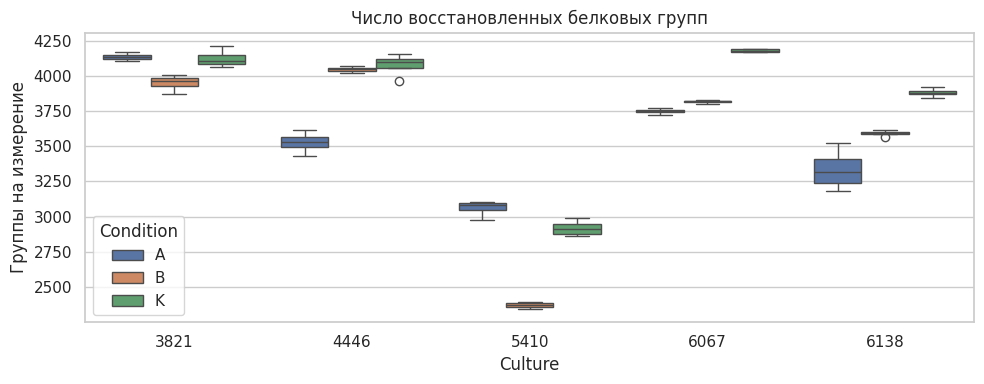

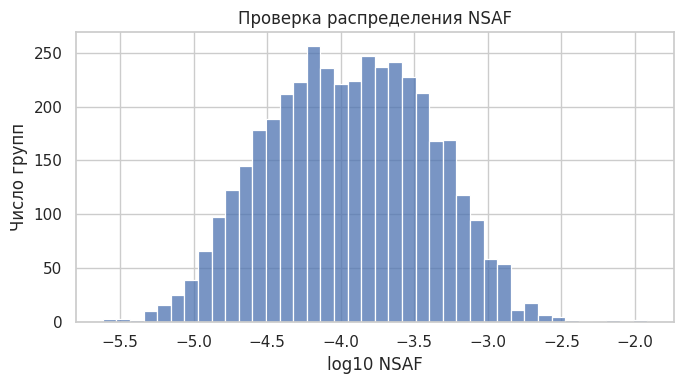

In [7]:
sample_qc = []
for i, record in design.iterrows():
    sample_qc.append(rebuild_sample(record, fasta_records))
    if (i + 1) % 4 == 0:
        print(f'Группы и NSAF: {i + 1}/{len(design)}')
sample_qc = save_table(pd.DataFrame(sample_qc), QC / 'sample_qc.tsv')
display(sample_qc)
display(sample_qc.groupby(['Culture', 'Condition'])['groups_rebuilt'].agg(['min', 'median', 'max']))

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=sample_qc, x='Culture', y='groups_rebuilt', hue='Condition', ax=ax)
ax.set(title='Число восстановленных белковых групп', ylabel='Группы на измерение')
fig.tight_layout()
fig.savefig(FIGURES / 'groups_per_sample.png', dpi=180)
plt.show()

example = pd.read_csv(GROUPS / (design.iloc[0]['File_stem'] + '_protein_groups.tsv'), sep='\t')
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(np.log10(example['NSAF']), bins=40, ax=ax)
ax.set(xlabel='log10 NSAF', ylabel='Число групп', title='Проверка распределения NSAF')
fig.tight_layout()
fig.savefig(FIGURES / 'nsaf_distribution.png', dpi=180)
plt.show()

## 4. Количественное сравнение QRePS

QRePS объединяет повторные измерения, нормирует NSAF, заполняет пропуски и проверяет различия
между обработкой и контролем. Выполнено десять сравнений: A/K и B/K для каждой культуры.
Для каждого запуска создаётся `sample_file.csv`, затем команда передаётся в `subprocess.run`,
как на семинаре. Результаты читаются из файлов `Quant_res_*.tsv` и `DRG_*.tsv`.

Группы с долей пропусков не менее 0.5 одновременно в обоих условиях исключаются.
После импутации QRePS выполняет непарный t-test и BH-коррекцию.
Встроенный запрос QRePS к STRING отключён: обогащение ниже рассчитывается отдельно
с общим экспериментальным фоном.


QRePS: GBM3821, A/K


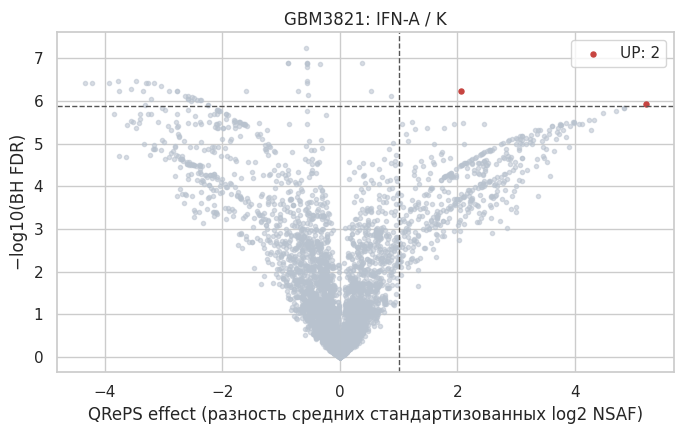

QRePS: GBM3821, B/K


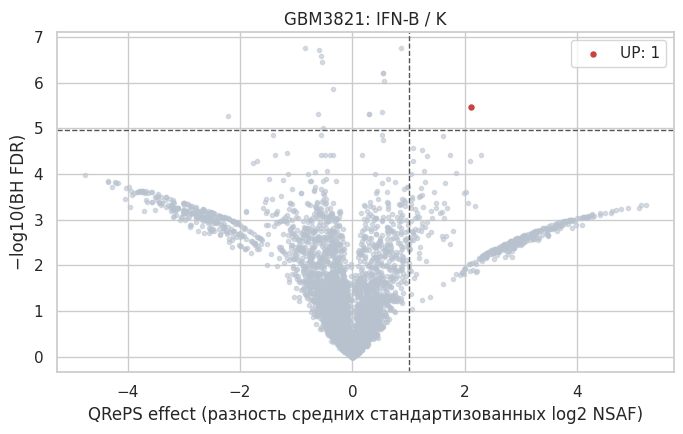

QRePS: GBM4446, A/K


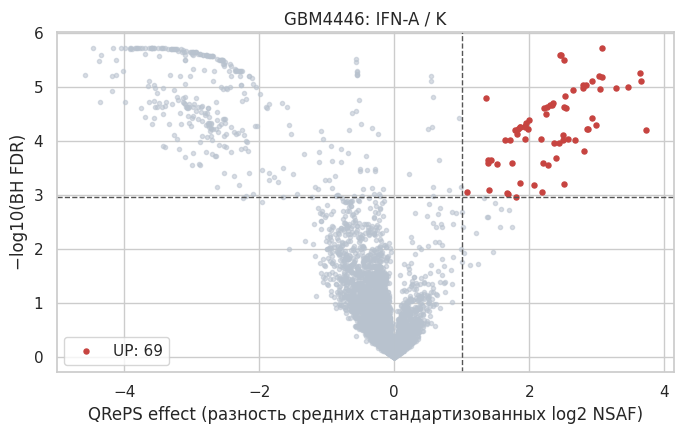

QRePS: GBM4446, B/K


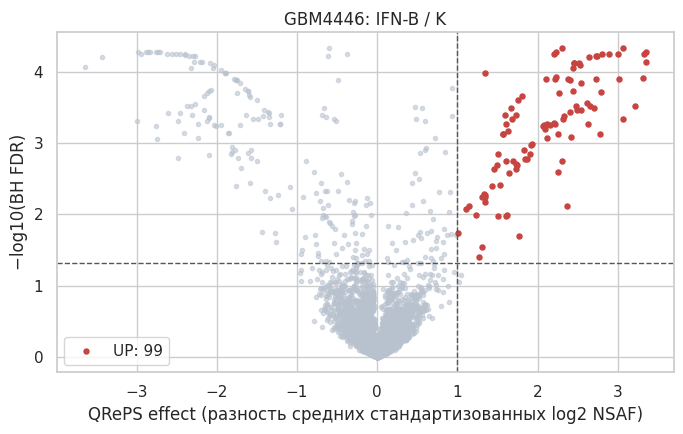

QRePS: GBM5410, A/K


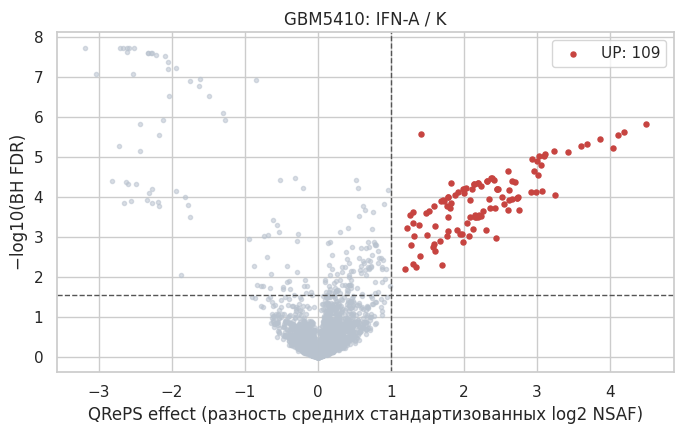

QRePS: GBM5410, B/K


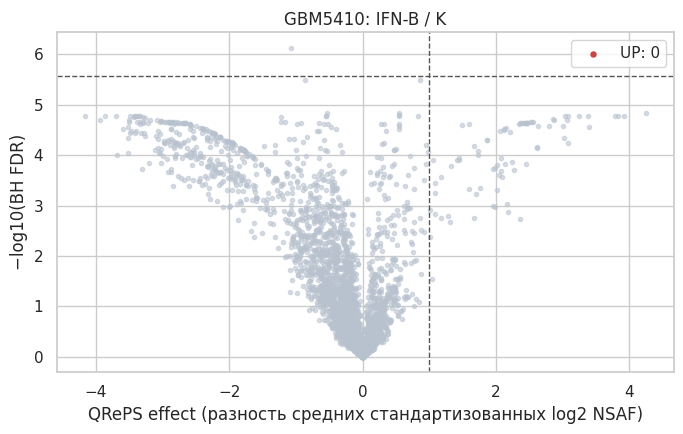

QRePS: GBM6067, A/K


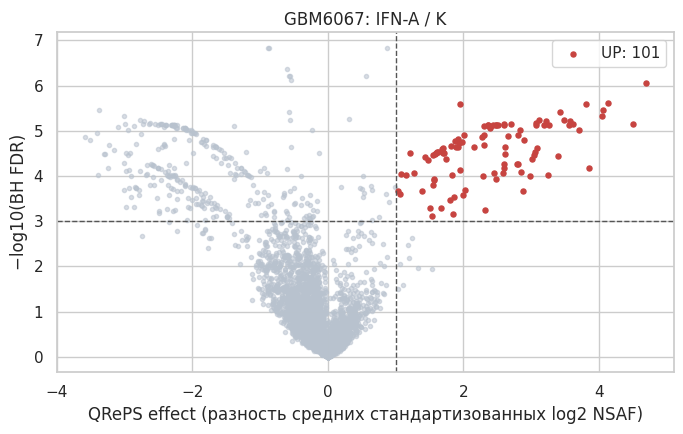

QRePS: GBM6067, B/K


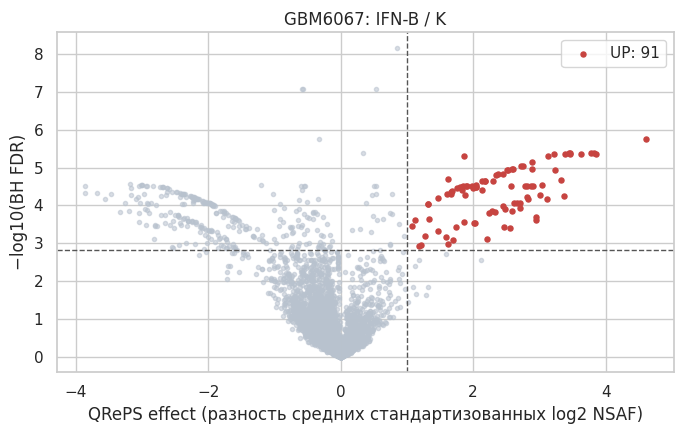

QRePS: GBM6138, A/K


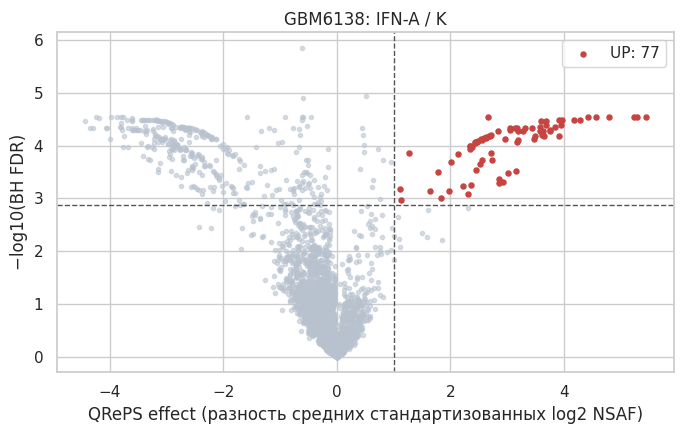

QRePS: GBM6138, B/K


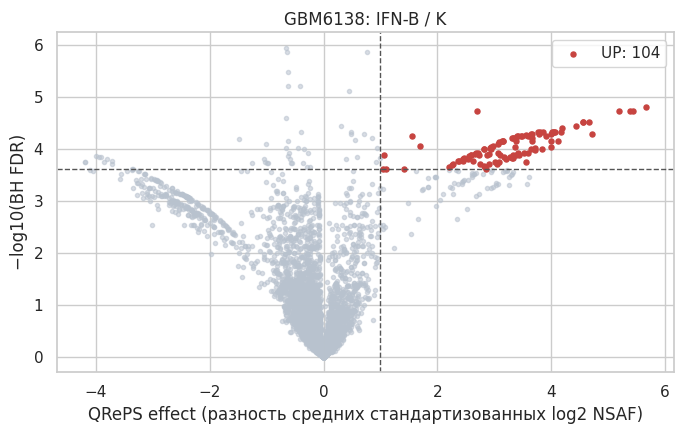

,Culture,Condition,Comparison,tested_groups,DRG_UP,DRG_unique_leaders,effective_BH_threshold,QRePS_effect_threshold,n_treatment,n_control
0,3821,A,3821A_3821K,4499,2,2,0.000001,1.0,4,4
1,3821,B,3821B_3821K,4390,1,1,0.000011,1.0,4,4
2,4446,A,4446A_4446K,4014,69,69,0.001091,1.0,4,4
3,4446,B,4446B_4446K,4149,99,99,0.048660,1.0,4,4
4,5410,A,5410A_5410K,3056,109,109,0.028758,1.0,4,4
5,5410,B,5410B_5410K,2886,0,0,0.000003,1.0,4,4
6,6067,A,6067A_6067K,4190,101,101,0.000993,1.0,4,4
7,6067,B,6067B_6067K,4208,91,91,0.001522,1.0,4,4
8,6138,A,6138A_6138K,3838,77,77,0.001363,1.0,4,4
9,6138,B,6138B_6138K,3984,104,104,0.000251,1.0,4,4


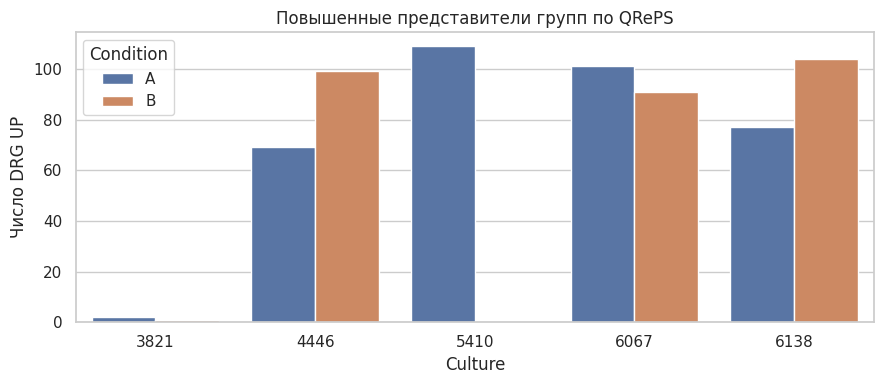

In [8]:
from IPython.display import Image

quant_results, drg_results, summary_rows = {}, {}, []
for culture in CULTURES:
    sample_df = pd.DataFrame(columns=['File Name', 'SampleID'])
    samples = design[design['Culture'] == culture]
    for _, sample in samples.iterrows():
        row = {
            'File Name': sample['File_stem'] + '_protein_groups.tsv',
            'SampleID': sample['SampleID'],
        }
        sample_df = pd.concat([sample_df, pd.DataFrame([row])], ignore_index=True)

    for condition in CONDITIONS:
        comparison = f'{culture}{condition}_{culture}K'
        outdir = QREPS / comparison
        outdir.mkdir(parents=True, exist_ok=True)
        sample_csv = outdir / 'sample_file.csv'
        sample_df.to_csv(sample_csv, index=False)
        labels = f'{culture}{condition},{culture}K'

        qreps_cmd = [
            sys.executable, str(QREPS_RUNNER),
            '--sample-file', str(sample_csv), '--labels', labels,
            '--input-dir', str(GROUPS), '--output-dir', str(outdir),
            '--imputation', 'kNN', '--thresholds', THRESHOLDS,
            '--alpha', str(ALPHA), '--regulation', REGULATION,
            '--fold-change', str(FOLD_CHANGE), '--max-mv', str(MAX_MISSING),
            '--fasta-size', str(fasta_counts['target_records']),
            '--species', '9606', '--report', 'True',
        ]
        print(f'QRePS: GBM{culture}, {condition}/K')
        (outdir / f'DRG_{comparison}.tsv').unlink(missing_ok=True)
        subprocess.run(qreps_cmd, check=True)

        quant_file = outdir / f'Quant_res_{comparison}.tsv'
        drg_file = outdir / f'DRG_{comparison}.tsv'
        quant = pd.read_csv(quant_file, sep='\t', index_col=0)
        quant.index.name = 'Protein'
        selected_index = pd.read_csv(drg_file, sep='\t', index_col=0).index if drg_file.exists() else []
        quant['UniProt'] = [accession(p) for p in quant.index]
        quant['fdr_BH'] = np.power(10., -quant['-log10(fdr_BH)'])
        quant['QRePS_effect'] = quant['log2(fold_change)']
        quant['Selected_UP'] = quant.index.isin(selected_index)

        # Описательное отношение NSAF без импутации.
        means = {}
        for group in (culture + condition, culture + 'K'):
            series = []
            for stem in samples.loc[samples['SampleID'].eq(group), 'File_stem']:
                df = pd.read_csv(GROUPS / (stem + '_protein_groups.tsv'), sep='\t')
                series.append(df.set_index('UniProt')['NSAF'])
            matrix = pd.concat(series, axis=1)
            means[group] = matrix.mean(axis=1, skipna=True)
            quant['observed_replicates_' + group] = quant['UniProt'].map(matrix.notna().sum(axis=1))
        ratio = means[culture + condition] / means[culture + 'K']
        quant['descriptive_log2_ratio_NSАF'] = quant['UniProt'].map(np.log2(ratio))
        quant['Culture'], quant['Condition'], quant['Comparison'] = culture, condition, comparison
        drg = quant[quant['Selected_UP']].copy()
        quant.to_csv(quant_file, sep='\t')
        drg.to_csv(drg_file, sep='\t')
        quant_results[culture, condition] = quant
        drg_results[culture, condition] = drg

        scores = quant['-log10(fdr_BH)']
        threshold = scores.quantile(.75) + 1.5 * (scores.quantile(.75) - scores.quantile(.25))
        summary_rows.append({
            'Culture': culture, 'Condition': condition, 'Comparison': comparison,
            'tested_groups': len(quant), 'DRG_UP': len(drg),
            'DRG_unique_leaders': drg['UniProt'].nunique(),
            'effective_BH_threshold': 10 ** (-threshold),
            'QRePS_effect_threshold': np.log2(FOLD_CHANGE),
            'n_treatment': int(samples.Condition.eq(condition).sum()),
            'n_control': int(samples.Condition.eq('K').sum()),
        })

        # График по тем же значениям эффекта и FDR.
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.scatter(quant['QRePS_effect'], scores, c='#b8c2ce', s=9, alpha=.55)
        ax.scatter(drg['QRePS_effect'], drg['-log10(fdr_BH)'], c='#c74440', s=13, label=f'UP: {len(drg)}')
        ax.axvline(np.log2(FOLD_CHANGE), color='#555', linestyle='--', linewidth=1)
        ax.axhline(threshold, color='#555', linestyle='--', linewidth=1)
        ax.set(xlabel='QRePS effect (разность средних стандартизованных log2 NSAF)',
               ylabel='−log10(BH FDR)', title=f'GBM{culture}: IFN-{condition} / K')
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGURES / f'volcano_{comparison}.png', dpi=180)
        plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(TABLES / 'qreps_summary.tsv', sep='\t', index=False)
display(summary)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=summary, x='Culture', y='DRG_UP', hue='Condition', ax=ax)
ax.set(title='Повышенные представители групп по QRePS', ylabel='Число DRG UP')
fig.tight_layout()
fig.savefig(FIGURES / 'drg_counts.png', dpi=180)
plt.show()


### Зависимость результата от порога

Для проверки дополнительно отобраны повышенные группы при фиксированном BH FDR < 0.01
и том же пороге эффекта QRePS. Особенно сильно результат меняется у GBM3821:
число DRG увеличивается с 2 до 422 для IFN-α и с 1 до 314 для IFN-β.
У GBM5410 для IFN-β вместо нуля отбирается 78 групп.
Это показывает зависимость числа находок от правила отбора.
В основной enrichment переданы исходные semi-dynamic списки.


In [9]:
sensitivity = []
for (culture, condition), quant in quant_results.items():
    selected_static = quant[
        quant.fdr_BH.lt(ALPHA) & quant.QRePS_effect.ge(np.log2(FOLD_CHANGE))
    ].copy()
    save_table(selected_static.reset_index(), QREPS / f'DRG_static_{culture}{condition}_{culture}K.tsv')
    sensitivity.append({
        'Culture': culture, 'Condition': condition,
        'UP_semi_dynamic': len(drg_results[culture, condition]),
        'UP_static_FDR001': len(selected_static),
    })
display(save_table(pd.DataFrame(sensitivity), TABLES / 'threshold_sensitivity.tsv'))

,Culture,Condition,UP_semi_dynamic,UP_static_FDR001
0,3821,A,2,422
1,3821,B,1,314
2,4446,A,69,80
3,4446,B,99,91
4,5410,A,109,109
5,5410,B,0,78
6,6067,A,101,105
7,6067,B,91,95
8,6138,A,77,86
9,6138,B,104,168


## 5. Пересечение изменившихся белков

Для сравнения культур использован UniProt accession представителя каждой группы.
Все возможные члены группы в список не добавлялись.
При таком подходе смена представителя между измерениями может уменьшать пересечение.
Сходство наборов показано индексом Жаккара: размер пересечения делится на размер объединения.

При IFN-α во всех пяти культурах найден один общий представитель: P20591 (MX1).
Ещё 48 представителей встречаются в нескольких культурах, а 227 отобраны только в одной.
Для IFN-β общего для пяти культур представителя нет: 34 встречаются в нескольких культурах,
214 отобраны в одной. Внутри GBM4446, GBM6067 и GBM6138 ответы на два интерферона
пересекаются по 31, 48 и 38 представителям соответственно.


IFN-A:


,n_leaders
class,
характерны для одной культуры,227
встречаются только в некоторых,48
общие для всех,1


,ID,n_cultures,cultures,3821,4446,5410,6067,6138,class
58,P20591,5,3821;4446;5410;6067;6138,1,1,1,1,1,общие для всех
274,Q9Y6K5,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
166,Q8IXQ6,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
131,Q15646,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
29,O95786,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
8,O14879,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
44,P09913,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
135,Q460N5,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
70,P29728,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых
59,P20592,4,4446;5410;6067;6138,0,1,1,1,1,встречаются только в некоторых


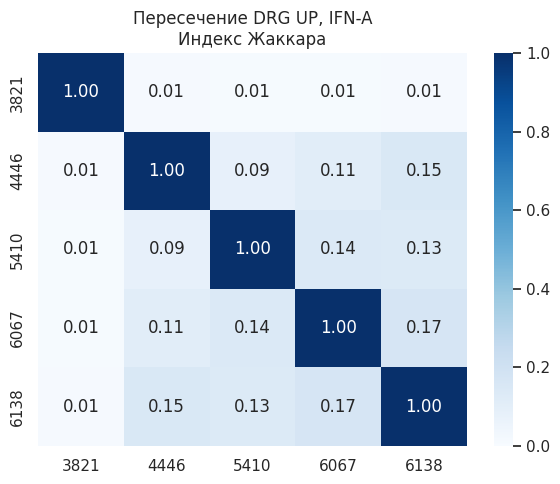

IFN-B:


,n_leaders
class,
характерны для одной культуры,214
встречаются только в некоторых,34


,ID,n_cultures,cultures,3821,4446,5410,6067,6138,class
9,O14879,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
54,P29728,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
49,P20592,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
48,P20591,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
40,P09914,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
26,O95786,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
115,Q460N5,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
110,Q15646,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
101,Q13287,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых
247,Q9Y6K5,3,4446;6067;6138,0,1,0,1,1,встречаются только в некоторых


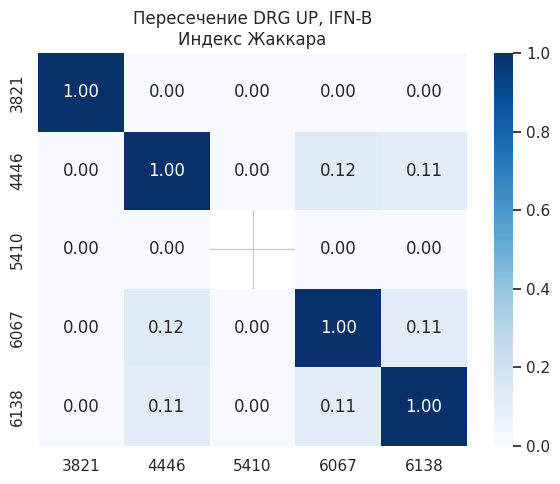

,Culture,common_A_B,A_only,B_only
0,3821,0,2,1
1,4446,31,38,68
2,5410,0,109,0
3,6067,48,53,43
4,6138,38,39,66


In [10]:
protein_memberships = {}
for condition in CONDITIONS:
    sets = {culture: set(drg_results[culture, condition]['UniProt'].dropna()) for culture in CULTURES}
    table = membership_table(sets)
    protein_memberships[condition] = table
    save_table(table, TABLES / f'protein_membership_{condition}.tsv')
    print(f'IFN-{condition}:')
    display(table['class'].value_counts().to_frame('n_leaders'))
    display(table.sort_values('n_cultures', ascending=False).head(20))
    name = f'proteins_{condition}'
    title = f'Пересечение DRG UP, IFN-{condition}'
    cultures = list(sets)
    matrix = pd.DataFrame(index=cultures, columns=cultures, dtype=float)
    for a in cultures:
        for b in cultures:
            union = sets[a] | sets[b]
            matrix.loc[a, b] = len(sets[a] & sets[b]) / len(union) if union else np.nan
    save_table(matrix.reset_index(names='Culture'), TABLES / f'{name}_jaccard.tsv')
    fig, ax = plt.subplots(figsize=(6, 5))
    if matrix.notna().any().any():
        sns.heatmap(matrix, vmin=0, vmax=1, annot=True, fmt='.2f', cmap='Blues', ax=ax)
    else:
        ax.text(.5, .5, 'Все множества пусты', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title + '\nИндекс Жаккара')
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}_jaccard.png', dpi=180)
    plt.show()

alpha_beta = []
for culture in CULTURES:
    a = set(drg_results[culture, 'A']['UniProt'])
    b = set(drg_results[culture, 'B']['UniProt'])
    alpha_beta.append({'Culture': culture, 'common_A_B': len(a & b), 'A_only': len(a - b), 'B_only': len(b - a)})
display(save_table(pd.DataFrame(alpha_beta), TABLES / 'within_culture_A_vs_B_proteins.tsv'))


## 6. Обогащение GO и KEGG в STRING

Для каждого интерферона выбран общий фон: пересечение белков,
количественно проверенных во всех пяти культурах.
До сопоставления с STRING в него вошли 2413 представителей для IFN-α и 2340 для IFN-β;
после сопоставления осталось 2387 и 2313 STRING ID соответственно.
Списки DRG для enrichment также ограничены этим фоном.
Поэтому они меньше полных списков QRePS, особенно для культур со многими редкими белками.

Обогащение рассчитано для Homo sapiens при FDR < 0.05.
Термины сопоставлены по категории и идентификатору.
Для IFN-β у GBM3821 и GBM5410 после ограничения общим фоном не осталось входных белков,
поэтому enrichment для этих двух сравнений не оценивался.
В таблицах это обозначено как NA.
Для GBM3821 при IFN-α анализ выполнен по двум белкам, что ограничивает его информативность.

Запросы выполнены через [STRING API](https://string-db.org/help/api/).


In [11]:
common_background = {}
for condition in CONDITIONS:
    sets = [set(quant_results[culture, condition]['UniProt'].dropna()) for culture in CULTURES]
    common_background[condition] = set.intersection(*sets)
    if len(common_background[condition]) < 100:
        raise ValueError(f'Слишком малый общий экспериментальный фон для IFN-{condition}')
    print(f'IFN-{condition}: общий фон до STRING = {len(common_background[condition])}')

to_map = set.union(*common_background.values())
string_mapping = map_to_string(to_map)
save_table(string_mapping, STRING / 'UniProt_to_STRING.tsv')
unmapped = sorted(to_map - set(string_mapping['UniProt']))
save_table(pd.DataFrame({'UniProt': unmapped}), STRING / 'unmapped_UniProt.tsv')
print('Не сопоставлено с STRING:', len(unmapped))

enrichment_results, enrichment_status_rows = {}, []
for culture in CULTURES:
    for condition in CONDITIONS:
        print(f'STRING enrichment: GBM{culture}, {condition}/K')
        result, status = enrich_comparison(
            quant_results[culture, condition], drg_results[culture, condition],
            culture, condition, string_mapping, common_background
        )
        enrichment_results[culture, condition] = result
        enrichment_status_rows.append(status)
enrichment_status = save_table(pd.DataFrame(enrichment_status_rows), STRING / 'enrichment_status.tsv')
display(enrichment_status)

IFN-A: общий фон до STRING = 2413
IFN-B: общий фон до STRING = 2340
STRING mapping: 400/2495
STRING mapping: 800/2495
STRING mapping: 1200/2495
STRING mapping: 1600/2495
STRING mapping: 2000/2495
STRING mapping: 2400/2495
STRING mapping: 2495/2495
Не сопоставлено с STRING: 26
STRING enrichment: GBM3821, A/K
STRING enrichment: GBM3821, B/K
STRING enrichment: GBM4446, A/K
STRING enrichment: GBM4446, B/K
STRING enrichment: GBM5410, A/K
STRING enrichment: GBM5410, B/K
STRING enrichment: GBM6067, A/K
STRING enrichment: GBM6067, B/K
STRING enrichment: GBM6138, A/K
STRING enrichment: GBM6138, B/K


,Culture,Condition,Comparison,DRG_total,DRG_in_common_background,foreground_STRING,background_STRING,foreground_unmapped,status
0,3821,A,3821A_3821K,2,2,2,2387,0,ok
1,3821,B,3821B_3821K,1,0,0,2313,0,too_few_foreground
2,4446,A,4446A_4446K,69,17,17,2387,0,ok
3,4446,B,4446B_4446K,99,21,21,2313,0,ok
4,5410,A,5410A_5410K,109,46,46,2387,0,ok
5,5410,B,5410B_5410K,0,0,0,2313,0,too_few_foreground
6,6067,A,6067A_6067K,101,36,36,2387,0,ok
7,6067,B,6067B_6067K,91,29,29,2313,0,ok
8,6138,A,6138A_6138K,77,27,26,2387,1,ok
9,6138,B,6138B_6138K,104,25,24,2313,1,ok


## 7. Общие и различающиеся функции

Для IFN-α получено 125 значимых GO/KEGG-терминов в объединении культур:
69 встречаются в нескольких культурах и 56 отобраны только в одной.
Терминов, значимых сразу во всех пяти культурах, нет.
При этом у GBM4446, GBM5410, GBM6067 и GBM6138 совпадают процессы ответа на интерферон I типа
и противовирусной защиты.

Для IFN-β сравнение enrichment возможно только между GBM4446, GBM6067 и GBM6138.
Поэтому общий или уникальный для всех пяти культур набор путей для этой обработки не определён.
Пустое множество DRG и неоценённый enrichment учитываются раздельно.


IFN-A: распределение значимых GO/KEGG-терминов


,n_terms
class,
встречаются только в некоторых,69
характерны для одной культуры,56


,общие для всех,встречаются только в некоторых,характерны для одной культуры
0,NaN,Component|GO:0045095 — Keratin filament [5410;...,Component|GO:0001533 — Cornified envelope [5410]
1,NaN,Function|GO:0001730 — 2-5-oligoadenylate synth...,Component|GO:0042825 — TAP complex [4446]
2,NaN,Function|GO:0016779 — Nucleotidyltransferase a...,Function|GO:0003725 — Double-stranded RNA bind...
3,NaN,Function|GO:0030280 — Structural constituent o...,Function|GO:0003950 — NAD+ poly-ADP-ribosyltra...
4,NaN,KEGG|hsa03250 — Viral life cycle - HIV-1 [6067...,Function|GO:0015433 — ABC-type peptide antigen...
5,NaN,KEGG|hsa04382 — Cornified envelope formation [...,Function|GO:0023029 — MHC class Ib protein bin...
6,NaN,KEGG|hsa04621 — NOD-like receptor signaling pa...,Function|GO:0046978 — TAP1 binding [4446]
7,NaN,KEGG|hsa04622 — RIG-I-like receptor signaling ...,Function|GO:0061630 — Ubiquitin protein ligase...
8,NaN,KEGG|hsa05160 — Hepatitis C [4446;5410;6067;6138],Function|GO:0097677 — STAT family protein bind...
9,NaN,KEGG|hsa05162 — Measles [4446;5410;6067;6138],KEGG|hsa02010 — ABC transporters [4446]


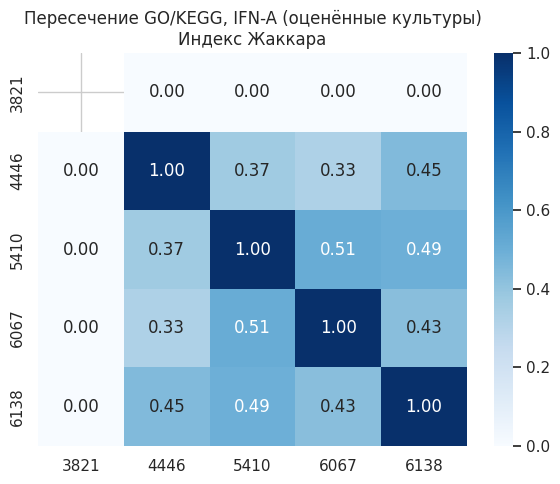

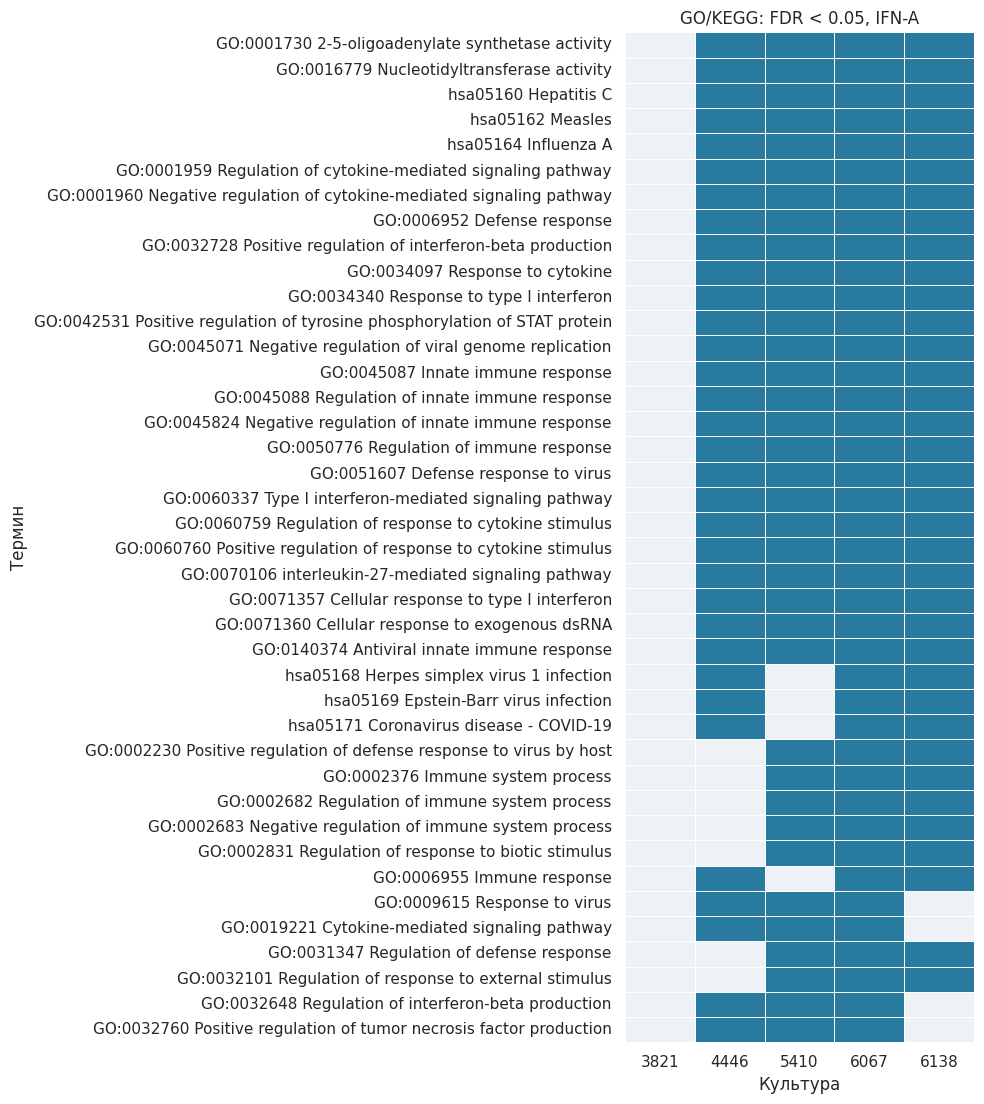

IFN-B: enrichment не оценён для ['3821', '5410'] из-за <2 входных белков; NA ≠ отсутствие пути.
IFN-B: распределение значимых GO/KEGG-терминов


,n_terms
class,
недостаточно данных для классификации во всех культурах,80


,общие для всех,встречаются только в некоторых,характерны для одной культуры


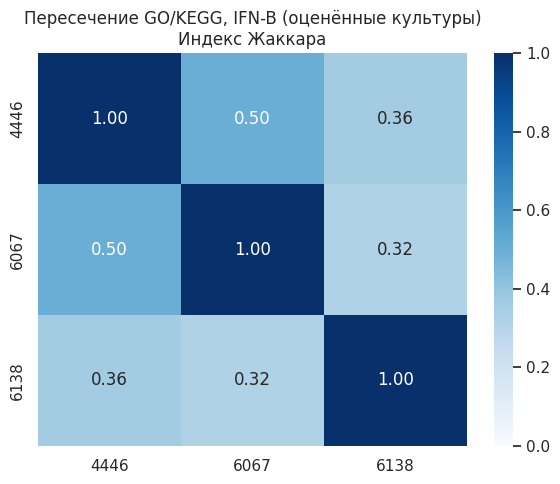

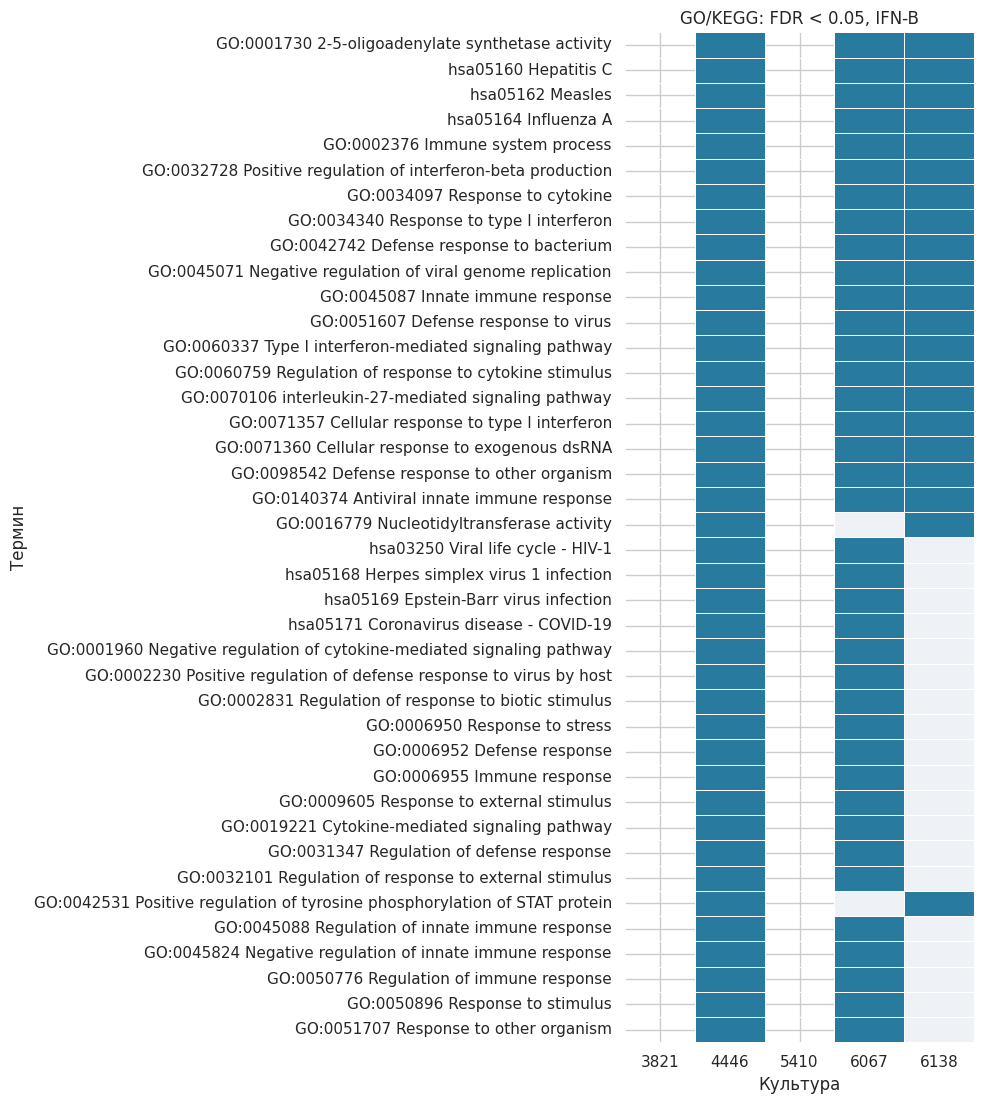

,Culture,common_A_B,A_only,B_only,status
0,3821,<NA>,<NA>,<NA>,not_evaluated_for_both_conditions
1,4446,41,11,23,ok
2,5410,<NA>,<NA>,<NA>,not_evaluated_for_both_conditions
3,6067,54,48,2,ok
4,6138,23,22,0,ok


GO BP / KEGG IFN-A:


,ID,n_cultures,cultures,description,3821,4446,5410,6067,6138,class,n_cultures_evaluated
22,KEGG|hsa05162,4,4446;5410;6067;6138,Measles,0,1,1,1,1,встречаются только в некоторых,5
23,KEGG|hsa05164,4,4446;5410;6067;6138,Influenza A,0,1,1,1,1,встречаются только в некоторых,5
21,KEGG|hsa05160,4,4446;5410;6067;6138,Hepatitis C,0,1,1,1,1,встречаются только в некоторых,5
34,Process|GO:0001960,4,4446;5410;6067;6138,Negative regulation of cytokine-mediated signa...,0,1,1,1,1,встречаются только в некоторых,5
33,Process|GO:0001959,4,4446;5410;6067;6138,Regulation of cytokine-mediated signaling pathway,0,1,1,1,1,встречаются только в некоторых,5
45,Process|GO:0006952,4,4446;5410;6067;6138,Defense response,0,1,1,1,1,встречаются только в некоторых,5
111,Process|GO:0060760,4,4446;5410;6067;6138,Positive regulation of response to cytokine st...,0,1,1,1,1,встречаются только в некоторых,5
110,Process|GO:0060759,4,4446;5410;6067;6138,Regulation of response to cytokine stimulus,0,1,1,1,1,встречаются только в некоторых,5
78,Process|GO:0042531,4,4446;5410;6067;6138,Positive regulation of tyrosine phosphorylatio...,0,1,1,1,1,встречаются только в некоторых,5
84,Process|GO:0045087,4,4446;5410;6067;6138,Innate immune response,0,1,1,1,1,встречаются только в некоторых,5


GO BP / KEGG IFN-B:


,ID,n_cultures,cultures,description,4446,6067,6138,class,3821,5410,n_cultures_evaluated
13,KEGG|hsa05162,3,4446;6067;6138,Measles,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
12,KEGG|hsa05160,3,4446;6067;6138,Hepatitis C,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
14,KEGG|hsa05164,3,4446;6067;6138,Influenza A,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
78,Process|GO:0098542,3,4446;6067;6138,Defense response to other organism,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
76,Process|GO:0071360,3,4446;6067;6138,Cellular response to exogenous dsRNA,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
45,Process|GO:0034097,3,4446;6067;6138,Response to cytokine,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
46,Process|GO:0034340,3,4446;6067;6138,Response to type I interferon,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
43,Process|GO:0032728,3,4446;6067;6138,Positive regulation of interferon-beta production,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
25,Process|GO:0002376,3,4446;6067;6138,Immune system process,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3
65,Process|GO:0051607,3,4446;6067;6138,Defense response to virus,1,1,1,недостаточно данных для классификации во всех ...,<NA>,<NA>,3


In [12]:
pathway_memberships = pathway_tables(enrichment_results, enrichment_status)

within_culture_pathways = []
for culture in CULTURES:
    status = enrichment_status[enrichment_status.Culture.eq(culture)]
    if not status['status'].eq('ok').all():
        within_culture_pathways.append({
            'Culture': culture, 'common_A_B': pd.NA, 'A_only': pd.NA, 'B_only': pd.NA,
            'status': 'not_evaluated_for_both_conditions',
        })
        continue
    subsets = [pathway_subset(enrichment_results[culture, c]) for c in CONDITIONS]
    sets = [set(t['category'].astype(str) + '|' + t['term'].astype(str)) for t in subsets]
    within_culture_pathways.append({
        'Culture': culture, 'common_A_B': len(sets[0] & sets[1]),
        'A_only': len(sets[0] - sets[1]), 'B_only': len(sets[1] - sets[0]), 'status': 'ok',
    })
display(save_table(pd.DataFrame(within_culture_pathways), TABLES / 'within_culture_A_vs_B_pathways.tsv'))


# Все значимые GO BP / KEGG, включая процессы, не содержащие слово interferon в названии.
for condition in CONDITIONS:
    table = pathway_memberships[condition]
    bp_kegg = table[table.ID.str.split('|', n=1).str[0].str.lower().isin(
        ['process', 'go process', 'kegg', 'kegg pathways']
    )].copy()
    save_table(bp_kegg, TABLES / f'GO_BP_KEGG_{condition}.tsv')
    print(f'GO BP / KEGG IFN-{condition}:')
    display(bp_kegg.sort_values('n_cultures', ascending=False).head(25))


### Интерпретация выбранных процессов

| Обработка | Термин | Культуры, в которых термин значим |
|---|---|---|
| IFN-α | GO:0060337, сигнальный путь интерферона I типа | GBM4446, GBM5410, GBM6067, GBM6138 |
| IFN-α | GO:0051607, защита от вирусов | GBM4446, GBM5410, GBM6067, GBM6138 |
| IFN-α | GO:0007259, передача сигнала через JAK/STAT | GBM4446 |
| IFN-α | GO:0032647, регуляция продукции IFN-α | GBM6067 |
| IFN-β | GO:0060337, сигнальный путь интерферона I типа | GBM4446, GBM6067, GBM6138 |
| IFN-β | GO:0071360, клеточный ответ на экзогенную двуцепочечную РНК | GBM4446, GBM6067, GBM6138 |

Совпадение интерферонового сигнального пути и защиты от вирусов согласуется с общим характером
ответа на обработку. Термин ответа на двуцепочечную РНК также относится к антивирусной реакции клетки.
Различия видны на уровне отдельных процессов: например, GO:0007259 значим только у GBM4446,
а GO:0032647 только у GBM6067 после IFN-α.
Эти результаты показывают различия в обогащении отобранных белков;
сами по себе они не доказывают, что соответствующий механизм отсутствует в остальных культурах.

В KEGG встречаются категории Measles (hsa05162), Influenza A (hsa05164) и Hepatitis C (hsa05160).
При IFN-α они общие для четырёх культур, кроме GBM3821, а при IFN-β для трёх оценённых культур.
Их появление может отражать общие белки ответа хозяина в аннотациях вирусных путей;
по этим категориям нельзя заключить, что клетки были заражены соответствующими вирусами.


## 8. Выводы

Выполнено сравнение протеомных ответов пяти preserved-культур глиобластомы на IFN-α и IFN-β по данным исследования [Lipatova et al. (2021)](https://doi.org/10.3390/cancers13215268).
Для анализа использовано 60 измерений из PXD022836 с одинаковыми настройками QRePS и отдельными сравнениями каждой обработки с контролем.
После IFN-α число повышенных групп составило 2 для GBM3821, 69 для GBM4446, 109 для GBM5410, 101 для GBM6067 и 77 для GBM6138.
После IFN-β для этих же культур отобрано 1, 99, 0, 91 и 104 группы соответственно.

Единственным общим для всех пяти культур представителем после IFN-α оказался MX1 (P20591), интерферон-индуцируемый белок.
Для IFN-β общего представителя при выбранных порогах не найдено.
Отсутствие DRG у GBM5410 и короткие списки GBM3821 зависят от правила semi-dynamic: при фиксированном FDR < 0.01 для GBM5410 после IFN-β отбирается 78 групп, а для GBM3821 списки увеличиваются до 422 и 314 групп для IFN-α и IFN-β.
Обогащённых GO/KEGG-терминов, значимых сразу во всех пяти культурах после IFN-α, нет.
Однако у GBM4446, GBM5410, GBM6067 и GBM6138 совпадают сигнальный путь интерферона I типа (GO:0060337) и защита от вирусов (GO:0051607).

Для IFN-β обогащение удалось сравнить у трёх культур, и у всех трёх значимы интерфероновый сигнальный путь и клеточный ответ на экзогенную двуцепочечную РНК (GO:0071360).
Среди различий после IFN-α можно отметить передачу сигнала через JAK/STAT (GO:0007259) у GBM4446 и регуляцию продукции IFN-α (GO:0032647) у GBM6067.
У культур есть общие признаки интерферонового ответа, хотя полный белковый состав ответа и набор значимых функций различаются.
Вывод ограничен анализом только направления UP, импутацией, выбором представителей групп, потерями при сопоставлении с FASTA и общим экспериментальным фоном STRING.
Незначимость отдельного пути не означает отсутствия этого механизма, а протеомный ответ сам по себе не позволяет оценить устойчивость культуры к вирусной инфекции.


## 9. Сохранение результатов


In [13]:
provenance = {
    'project': 'PXD022836', 'instrument': 'Orbitrap Fusion Lumos',
    'article': 'https://doi.org/10.3390/cancers13215268',
    'sample_metadata_source': BASE_URL + 'File_names_to_sample_names.csv',
    'snapshot_date': '2026-11-23', 'run_utc': pd.Timestamp.now(tz='UTC').isoformat(),
    'FASTA_filename': FASTA_FILE.name, 'FASTA_sha256': FASTA_SHA256,
    'FASTA_counts': fasta_counts,
    'ready_data': ['filtered PSM TSV', 'filtered protein TSV'],
    'not_rerun': ['RAW conversion', 'MSFragger search', 'Scavager ML/target-decoy validation'],
    'self_computed': ['protein regrouping', 'NSAF from PSM/length', 'QRePS', 'STRING', 'overlaps'],
    'grouping': 'greedy peptide coverage; alphabetical UniProt tie-break',
    'imputation': 'QRePS kNN with empty-partial-table compatibility fix',
    'execution': 'QRePS CLI via subprocess.run; standalone STRING with experimental background',
    'BH_compatibility': 'statsmodels.stats.multitest.multipletests',
    'thresholds': THRESHOLDS, 'nominal_alpha': ALPHA, 'fold_change_parameter': FOLD_CHANGE,
    'regulation': REGULATION, 'max_missing': MAX_MISSING,
    'STRING_API': STRING_API, 'enrichment_fdr': ENRICHMENT_FDR,
    'background': 'intersection of tested UniProt leaders across cultures, separately A and B',
    'metadata_policy': 'PRIDE mapping CSV; filename conflicts saved in tables',
    'replicate_caveat': 'four measurements; biological independence not assumed without protocol',
}
(RESULTS / 'analysis_parameters.json').write_text(
    json.dumps(provenance, ensure_ascii=False, indent=2), encoding='utf-8'
)
(RESULTS / 'README.txt').write_text(
    'Дизайн: tables/experimental_design.tsv\n'
    'Расхождения метаданных: tables/metadata_filename_discrepancies.tsv\n'
    'Группы и NSAF: protein_groups/\n'
    'QRePS и матрицы после импутации: qreps/\n'
    'STRING, экспериментальный фон и mapping: string/\n'
    'Пересечения и сводные таблицы: tables/\n'
    'Графики: figures/\n'
    'Потери при сопоставлении FASTA: qc/\n'
    'Настройки и источники: analysis_parameters.json\n'
    'Выполненный ipynb скачайте отдельно из Colab.\n', encoding='utf-8'
)
archive = shutil.make_archive(str(ROOT / 'proteomics_homework_results'), 'zip', RESULTS)
print('Готово:', archive)
print('QRePS выполнен для всех пяти культур и двух интерферонов; статусы STRING см. в enrichment_status.tsv.')
if DOWNLOAD_RESULTS:
    from google.colab import files
    files.download(archive)

Готово: /content/proteomics_homework/proteomics_homework_results.zip
QRePS выполнен для всех пяти культур и двух интерферонов; статусы STRING см. в enrichment_status.tsv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Источники

- Lipatova et al. (2021). *Multi-Omics Analysis of Glioblastoma Cells’ Sensitivity to Oncolytic Viruses*.
  [DOI: 10.3390/cancers13215268](https://doi.org/10.3390/cancers13215268).
- [PRIDE PXD022836](https://www.ebi.ac.uk/pride/archive/projects/PXD022836), таблица соответствия образцов и отфильтрованные результаты.
- [QRePS 1.2.1](https://pypi.org/project/QRePS/1.2.1/), [исходный репозиторий](https://github.com/kazakova/Metrics).
- [Scavager](https://github.com/markmipt/scavager), принцип группировки по общим пептидам.
- [STRING API](https://string-db.org/help/api/), Homo sapiens, версия 12.5.
